# Отчёт-воспроизведение: arXiv:2603.27498
## *High performance imaging of ¹⁷¹Yb atoms in shallow clock-magic tweezers by alternating dual-tone narrowline cooling*
Song, Kim, Han, Oh, Mun (KRISS), v2, май 2026

**Цель ноутбука.** Восстановить с нуля всю теорию статьи и численно воспроизвести все теоретические кривые и числа. Экспериментальные точки воспроизвести нельзя, поэтому везде сравниваем модель с числами, приведёнными в тексте.

| § | Что делаем | Что в статье |
|---|---|---|
| 0 | Константы, масштабы задачи | — |
| 1 | Клебш–Гордан, Вигнер–Эккарт, силы переходов | Fig. 1(b) |
| 2 | Вывод гамильтониана двухтонового возбуждения из $-\hat{\mathbf d}\cdot\mathbf E$ | (B1) |
| 3 | Преобразование Морриса–Шора (SVD) | (B2), (1) |
| 4 | Уравнение Линдблада, стационар, проверка формулы (2), секулярное приближение, тёмное состояние одного тона | (2), App. C, Fig. 2(a,b) |
| 5 | Теоретические кривые Fig. 2(c,d) с френелевским пропусканием кюветы | Fig. 2(c,d) |
| 6 | Доплеровское охлаждение в свободном пространстве | [36], Sec. III |
| 7 | Пинцет: потенциал, частоты, ангармонизм; поляризуемость ³P₁ на 759 нм, магический угол, $\gamma(\theta_B)$ | (D1), Fig. 5(a), App. A |
| 8 | Монте-Карло (D1)–(D4), валидация, модель дискретных фотонов | App. D |
| 9–11 | $T(\theta_k)$; release-recapture и частота чередования; скан отстройки | Fig. 3(a,b), 4(a) |
| 12 | Рамановское рассеяние света ловушки в ³P₀,₂ (Крамерс–Гейзенберг) | App. E |
| 13 | Потери на фотон: экспонента, глубина, температура, частота чередования, $\gamma$ | Fig. 4(b), 5(a), 6, 7 |
| 14 | Статистика изображений: гистограммы, порог, fidelity, survival, model-free, lifetime | Sec. IV, Fig. 1(e), 5(b–d) |
| 15 | Обсуждение: NA 0.6, бюджет потерь | Sec. V |
| 16 | Итоговая таблица, приближения, найденные неточности статьи | — |

**Инструменты.**
* **sympy** — все символьные выводы: КГ и 6j-символы в радикалах, переход во вращающуюся систему и секулярное приближение (B1), MS-диагонализация и ур. (1), стационар (C1)→(2), трение и доплеровская температура, разложение потенциала пинцета.
* **qutip** (≥5) — квантовая динамика: операторы (`Qobj`, `jmat`, `tensor`), стационар уравнения Линдблада (`steadystate`), временная эволюция (`mesolve`, в том числе с явно зависящим от времени гамильтонианом), `clebsch`.
* **numba** — ядро Монте-Карло (`@njit`), примерно 40 нс на атом-шаг.
* numpy, scipy, matplotlib — остальное.

**Как запускать.** `pip install qutip sympy numba`. Флаг `QUICK=True` в первой ячейке задаёт статистику МК; тогда весь ноутбук выполняется примерно за 10–15 мин на 2 ядрах (Linux). С `QUICK=False` статистика выше и время больше в несколько раз. На Linux параметрические сканы МК распараллеливаются через `fork`; на других ОС они выполняются последовательно. Все генераторы случайных чисел засеяны, результаты воспроизводимы.

**Соглашения, общие для всего ноутбука**
* $\Gamma = 2\pi\times182$ кГц — ширина ¹S₀–³P₁. Для ¹⁷¹Yb $\lambda = 555.8$ нм.
* $\Delta=\omega_L-\omega_0$, так что $\Delta<0$ — красная отстройка. В МК $\Delta$ отсчитывается от резонанса **на дне ловушки**.
* $s$ — **суммарный** параметр насыщения ретро-отражённой пары пучков (каждый пучок несёт $s/2$). При чередовании полная интенсивность фиксирована: активная ось получает весь $s$, при одновременной работе осей каждая получает $s/2$.
* $\gamma$ — относительный дифференциальный штарковский сдвиг: $U_e=(1+\gamma)U_g$. При $\gamma>0$ возбуждённое состояние захвачено сильнее и линия в ловушке сдвинута в красную сторону. Почему именно так и в чём расхождение со статьёй, см. §8.

In [28]:
import numpy as np, matplotlib.pyplot as plt, time, sys, os, warnings
from math import sqrt
from scipy import linalg, optimize, integrate, stats
import qutip as qt
import sympy as sp
import numba
from numba import njit
from IPython.display import display, Math
from sympy.physics.wigner import clebsch_gordan, wigner_3j, wigner_6j
sp.init_printing()
np.set_printoptions(precision=5, suppress=True, linewidth=130)
print("qutip", qt.__version__, "| sympy", sp.__version__, "| numba", numba.__version__, "| numpy", np.__version__)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3, "font.size": 10,
                     "axes.titlesize": 10, "legend.fontsize": 8})
QUICK = True                     # False -> больше статистики в МК (дольше)
SCALE = 1 if QUICK else 4        # множитель числа атомов / времени в МК

# ---------- фундаментальные константы (CODATA 2018), СИ ----------
hbar = 1.054571817e-34; h = 2*np.pi*hbar; kB = 1.380649e-23; c = 299792458.0
eps0 = 8.8541878128e-12; e_ch = 1.602176634e-19; a0 = 5.29177210903e-11; amu = 1.66053906660e-27
muB_h = 1.39962449361e6          # мю_Б/h, Гц/Гс
ea0 = e_ch*a0

# ---------- 171Yb, переход 1S0(F=1/2) - 3P1(F'=3/2) ----------
m_Yb  = 170.9363*amu
lam   = 555.80e-9; k_L = 2*np.pi/lam
Gam   = 2*np.pi*182e3            # с^-1
lam_tr = 759.356e-9              # длина волны пинцета
w0    = 0.9e-6                   # перетяжка пинцета
B_G   = 15.0                     # поле, Гс
eta_det = 0.0224                 # эффективность регистрации (App. A)
gJ_3P1 = 1.4928                  # g_J(3P1)
gF_e  = gJ_3P1*(1.5*2.5 + 1*2 - 0.5*1.5)/(2*1.5*2.5)     # g_F(F'=3/2)
mu_I  = 0.4919                   # магнитный момент ядра 171Yb, мю_N
muN_h = 7.6225932e2              # мю_N/h, Гц/Гс

E_r   = (hbar*k_L)**2/(2*m_Yb)
T_D   = hbar*Gam/(2*kB)
dZ    = gF_e*muB_h*B_G           # расщепление e(+1/2)-e(-1/2), Гц
dg    = mu_I/0.5*muN_h*B_G       # расщепление g(+1/2)-g(-1/2), Гц
zR    = np.pi*w0**2/lam_tr
def trap_freqs(U0_mK, w=w0):
    U0 = U0_mK*1e-3*kB; zr = np.pi*w**2/lam_tr
    return np.sqrt(4*U0/(m_Yb*w**2))/2/np.pi, np.sqrt(2*U0/(m_Yb*zr**2))/2/np.pi

print(f"Gamma/2pi            = {Gam/2/np.pi/1e3:.0f} кГц,  tau = {1/Gam*1e9:.0f} нс")
print(f"доплеровский предел  T_D = hbar*Gamma/2kB = {T_D*1e6:.2f} мкК")
print(f"отдача  E_r/h = {E_r/h/1e3:.2f} кГц,  T_r = 2E_r/kB = {2*E_r/kB*1e6:.3f} мкК,  v_r = {hbar*k_L/m_Yb*1e3:.2f} мм/с")
print(f"g_F(3P1,F'=3/2) = {gF_e:.4f};  расщепление e(+-1/2) = {dZ/1e6:.2f} МГц = {dZ*2*np.pi/Gam:.0f} Gamma")
print(f"ядерный зееман основного: {dg/1e3:.2f} кГц = {dg*2*np.pi/Gam:.3f} Gamma")
print(f"z_R = {zR*1e6:.2f} мкм")
for U in (0.14, 0.2):
    fr, fz = trap_freqs(U)
    eta_LD = k_L*np.sqrt(hbar/(2*m_Yb*2*np.pi*fr))
    print(f"U0={U} мК: U0/h = {U*1e-3*kB/h/1e6:.2f} МГц = {U*1e-3*kB/hbar/Gam:.1f} Gamma; "
          f"nu_r = {fr/1e3:.1f} кГц, nu_z = {fz/1e3:.2f} кГц; omega_r/Gamma = {2*np.pi*fr/Gam:.2f}; eta_LD(r) = {eta_LD:.2f}")
v10 = np.sqrt(kB*10e-6/m_Yb)
print(f"при T=10 мкК: v_rms(1D) = {v10*100:.2f} см/с, k v_rms / Gamma = {k_L*v10/Gam:.2f}")

qutip 5.3.1 | sympy 1.14.0 | numba 0.68.0 | numpy 2.5.3
Gamma/2pi            = 182 кГц,  tau = 874 нс
доплеровский предел  T_D = hbar*Gamma/2kB = 4.37 мкК
отдача  E_r/h = 3.78 кГц,  T_r = 2E_r/kB = 0.363 мкК,  v_r = 4.20 мм/с
g_F(3P1,F'=3/2) = 0.9952;  расщепление e(+-1/2) = 20.89 МГц = 115 Gamma
ядерный зееман основного: 11.25 кГц = 0.062 Gamma
z_R = 3.35 мкм
U0=0.14 мК: U0/h = 2.92 МГц = 16.0 Gamma; nu_r = 29.2 кГц, nu_z = 5.54 кГц; omega_r/Gamma = 0.16; eta_LD(r) = 0.36
U0=0.2 мК: U0/h = 4.17 МГц = 22.9 Gamma; nu_r = 34.9 кГц, nu_z = 6.62 кГц; omega_r/Gamma = 0.19; eta_LD(r) = 0.33
при T=10 мкК: v_rms(1D) = 2.21 см/с, k v_rms / Gamma = 0.22


**Что дают эти масштабы.** Иерархия энергий задачи определяет все последующие приближения.

$$\underbrace{E_r/h\approx3.7\ \text{кГц}}_{\text{отдача}} \;<\; \underbrace{\delta_g\approx11\ \text{кГц}}_{\text{ядерный зееман}} \;\ll\; \underbrace{\nu_r\approx30\ \text{кГц}}_{\text{пинцет}} \;<\; \underbrace{\Gamma/2\pi=182\ \text{кГц}}_{\text{линия}} \;\ll\; \underbrace{U_0/h\approx4\ \text{МГц}}_{\text{глубина}} \;\ll\; \underbrace{\delta_Z\approx21\ \text{МГц}}_{\text{зееман }e}$$

* $\omega_r/\Gamma\approx0.2$: боковые полосы не разрешены. Поэтому движение можно описывать классически, а рассеяние — локальными стационарными скоростями (полуклассическое приближение, App. D). Запас по этому параметру небольшой.
* $kv/\Gamma\approx0.2$ при 10 мкК: доплеровский сдвиг не мал по сравнению с $|\Delta|\sim\Gamma$. Линеаризация силы трения ($F=-\alpha v$) работает лишь приближённо. В §8 это проверено отдельной моделью с дискретными фотонами.
* $U_0\approx23\,\Gamma$: даже малая относительная разница поляризуемостей ($\gamma\sim0.05$) даёт сдвиг линии около $\Gamma$. Отсюда важность угла $\theta_B$ (§7).
* $\delta_Z\approx115\,\Gamma$: каждый тон резонансен только «своему» подуровню $e_{\pm1/2}$. Это секулярное приближение, оно проверено в §4.
* $\delta_g\approx0.06\,\Gamma$: в статье этим расщеплением пренебрегают. Мы его сохраняем и смотрим, где оно важно (тёмное состояние).

---
## §1. Угловой момент: коэффициенты Клебша–Гордана и теорема Вигнера–Эккарта

**Задача.** Получить относительные амплитуды дипольных переходов $|{}^1S_0,F{=}\tfrac12,m\rangle\to|{}^3P_1,F'{=}\tfrac32,m'\rangle$ (Fig. 1(b)) и коэффициенты ветвления спонтанного распада.

**Определение.** Коэффициенты Клебша–Гордана (КГ) — элементы унитарной (в конвенции Кондона–Шортли вещественной ортогональной) матрицы перехода между несвязанным базисом $|j_1m_1\rangle|j_2m_2\rangle$ и связанным базисом $|JM\rangle$:
$$|JM\rangle=\sum_{m_1m_2}\langle j_1m_1;j_2m_2|JM\rangle\,|j_1m_1\rangle|j_2m_2\rangle,\qquad m_1+m_2=M .$$
Точные значения в радикалах даёт `sympy.physics.wigner.clebsch_gordan` (формула Рака в рациональной арифметике). Для численной работы используем `qutip.clebsch` и сверяем одно с другим.

**Теорема Вигнера–Эккарта.** Компоненты $\hat d_q$ ($q=0,\pm1$) дипольного оператора образуют неприводимый тензор ранга 1. Поэтому
$$\langle F'm'|\hat d_q|Fm\rangle=\frac{\langle F'\|d\|F\rangle}{\sqrt{2F'+1}}\,\langle F m;1q|F'm'\rangle .$$
Вся зависимость от $m,m',q$ — чистая геометрия (КГ). Физика атома сидит в одном числе, приведённом матричном элементе. Правило отбора $m'=m+q$ следует из условия $M=m_1+m_2$.

**Следствия.**
1. Относительные амплитуды переходов равны КГ. Для $F=\tfrac12\to F'=\tfrac32$: π-переходы ($m=\pm\tfrac12\to m'=\pm\tfrac12$) имеют $\sqrt{2/3}$, σ-переходы к $|m'|=\tfrac12$ имеют $\sqrt{1/3}$, растянутые $m'=\pm\tfrac32$ имеют $1$.
2. Сумма $\sum_{m,q}|\langle Fm;1q|F'm'\rangle|^2=1$ (нормировка $|F'm'\rangle$). Значит, квадраты КГ — вероятности ветвления распада из $|F'm'\rangle$. Например, $|e_{-1/2}\rangle$ распадается в $|g_{-1/2}\rangle$ (π) с вероятностью 2/3 и в $|g_{+1/2}\rangle$ (σ) с вероятностью 1/3.

In [29]:
Sh = sp.Rational(1, 2)
def cg(j1, m1, j2, m2, J, M):
    '''<j1 m1; j2 m2 | J M> численно (qutip.clebsch, конвенция Кондона-Шортли).'''
    if abs(m1 + m2 - M) > 1e-9 or abs(m1) > j1 + 1e-9 or abs(m2) > j2 + 1e-9 or abs(M) > J + 1e-9: return 0.0
    if J < abs(j1 - j2) - 1e-9 or J > j1 + j2 + 1e-9: return 0.0
    return float(qt.clebsch(j1, j2, J, m1, m2, M))

def threej(j1, m1, j2, m2, j3, m3):
    '''3j-символ через КГ.'''
    return (-1)**int(round(j1 - j2 - m3))/sqrt(2*j3 + 1)*cg(j1, m1, j2, m2, j3, -m3)

def mlist(j): return [j - i for i in range(int(round(2*j)) + 1)]
def R_(x): return sp.Rational(int(round(2*x)), 2)                  # 0.5 -> 1/2 для sympy

# --- сверка qutip.clebsch с точными sympy-значениями для всех j1,j2 <= 2
err = 0.0; n = 0
for j1 in np.arange(0, 2.01, .5):
    for j2 in np.arange(0, 2.01, .5):
        for J in np.arange(abs(j1 - j2), j1 + j2 + .01, 1):
            for m1 in mlist(j1):
                for m2 in mlist(j2):
                    if abs(m1 + m2) <= J:
                        ex = float(clebsch_gordan(R_(j1), R_(j2), R_(J), R_(m1), R_(m2), R_(m1 + m2)))
                        err = max(err, abs(ex - cg(j1, m1, j2, m2, J, m1 + m2))); n += 1
print(f"qutip.clebsch vs sympy (точно): max |разница| = {err:.1e} по {n} коэффициентам")

# --- ортогональность матрицы КГ для 1/2 x 1 = 1/2 + 3/2
rows = [(J, M) for J in (0.5, 1.5) for M in mlist(J)]
cols = [(m1, m2) for m1 in mlist(0.5) for m2 in mlist(1)]
C = np.array([[cg(0.5, m1, 1, m2, J, M) for (m1, m2) in cols] for (J, M) in rows])
print("C C^T = 1 ?", np.allclose(C @ C.T, np.eye(6)))

# --- точная таблица КГ F=1/2 -> F'=3/2 (sympy): строки m=+1/2,-1/2; столбцы m'=+3/2..-3/2  (= Fig. 1(b))
CGtab = sp.Matrix(2, 4, lambda i, j: clebsch_gordan(Sh, 1, 3*Sh, [Sh, -Sh][i], [3*Sh, Sh, -Sh, -3*Sh][j] - [Sh, -Sh][i],
                                                    [3*Sh, Sh, -Sh, -3*Sh][j]) if abs([3*Sh, Sh, -Sh, -3*Sh][j] - [Sh, -Sh][i]) <= 1 else 0)
print("КГ <1/2 m; 1 q | 3/2 m'> (строки m=+1/2,-1/2; столбцы m'=+3/2,+1/2,-1/2,-3/2):")
display(CGtab)
print("квадраты (относительные силы линий):")
display(CGtab.applyfunc(lambda x: x**2))
print("ветвление распада из m'=-1/2 (сумма квадратов по столбцу = 1):", [CGtab[i, 2]**2 for i in range(2)])

qutip.clebsch vs sympy (точно): max |разница| = 1.1e-16 по 517 коэффициентам
C C^T = 1 ? True
КГ <1/2 m; 1 q | 3/2 m'> (строки m=+1/2,-1/2; столбцы m'=+3/2,+1/2,-1/2,-3/2):


⎡   √6  √3   ⎤
⎢1  ──  ──  0⎥
⎢   3   3    ⎥
⎢            ⎥
⎢   √3  √6   ⎥
⎢0  ──  ──  1⎥
⎣   3   3    ⎦

квадраты (относительные силы линий):


⎡1  2/3  1/3  0⎤
⎢              ⎥
⎣0  1/3  2/3  1⎦

ветвление распада из m'=-1/2 (сумма квадратов по столбцу = 1): [1/3, 2/3]


---
## §2. Гамильтониан двухтонового возбуждения (вывод (B1))

**Задача.** Получить эффективный не зависящий от времени гамильтониан системы $\{|g_-\rangle,|g_+\rangle,|e_-\rangle,|e_+\rangle\}$ (здесь $g_\pm\equiv|{}^1S_0,\tfrac12,\pm\tfrac12\rangle$, $e_\pm\equiv|{}^3P_1,\tfrac32,\pm\tfrac12\rangle$). Атом освещён одним пучком с двумя частотами $\omega_\pm$ и общей поляризацией.

**Обозначения.** Ось квантования $\hat z_B\parallel\mathbf B$; в лабораторной системе статьи это ось $y$. Поле
$$\mathbf E(t)=\tfrac12\,\boldsymbol{\mathcal E}\,\big(e^{-i\omega_+t}+e^{-i\omega_-t}\big)+\text{c.c.},\qquad
\boldsymbol{\mathcal E}=\mathcal E_0\big(e^{i\phi}\cos\theta\,\hat e_\perp+\sin\theta\,\hat e_\parallel\big),$$
где $\hat e_\parallel=\hat z_B$, $\hat e_\perp\perp\mathbf B$. Сферические орты: $\hat e_{\pm1}=\mp(\hat x\pm i\hat y)/\sqrt2$, $\hat e_0=\hat z$.

**Допущения.** (i) Дипольное приближение, $\hat V=-\hat{\mathbf d}\cdot\mathbf E$. (ii) Приближение вращающейся волны (RWA): отбрасываем члены $e^{\pm2i\omega t}$. (iii) Секулярное приближение: тон $\omega_\pm$ взаимодействует только с $e_{\pm}$, поскольку «чужой» тон отстроен на $\delta_Z\approx115\Gamma$. (iv) Подуровни $e_{\pm3/2}$ отстроены от ближайшего тона на $\sim\delta_Z$, уровень $F'=1/2$ — на ГГц; их отбрасываем. Все эти допущения проверены численно в §4.

**Вывод.**

*Шаг 1 (матричные элементы).* В RWA важен только член, повышающий энергию атома: $\langle e_{m'}|\hat V|g_m\rangle=-\tfrac12\langle e_{m'}|\hat{\mathbf d}\cdot\boldsymbol{\mathcal E}|g_m\rangle e^{-i\omega t}$. Раскладываем $\hat{\mathbf d}\cdot\boldsymbol{\mathcal E}=\sum_q(-1)^q\hat d_q\mathcal E_{-q}$. Компонента с $q=m'-m$ даёт
$$\langle e_{m'}|\hat{\mathbf d}\cdot\boldsymbol{\mathcal E}|g_m\rangle=\varepsilon_q\,\langle e_{m'}|\hat d_q|g_m\rangle,\qquad \varepsilon_q\equiv\hat e_q^{\,*}\cdot\boldsymbol{\mathcal E}.$$
По Вигнеру–Эккарту отсюда $\hbar\Omega_{m'm}\equiv-\langle e_{m'}|\hat{\mathbf d}\cdot\boldsymbol{\mathcal E}|g_m\rangle=\hbar\Omega_{\rm ref}\,\varepsilon_q\,\langle\tfrac12 m;1q|\tfrac32 m'\rangle/\mathcal E_0$.

*Шаг 2 (сферические компоненты).* $\varepsilon_0=\mathcal E_\parallel$. Для $\hat e_\perp=\hat x_B$ получаем $\varepsilon_{\pm1}=\mp\mathcal E_\perp/\sqrt2$. Значит,
$$\Omega_\pi\propto\sqrt{\tfrac23}\,\mathcal E_\parallel,\qquad \Omega_{\sigma\pm}\propto\sqrt{\tfrac13}\cdot\big(\mp\tfrac{1}{\sqrt2}\big)\mathcal E_\perp
\;\;\Rightarrow\;\;\Omega_\pi:\Omega_{\sigma+}:\Omega_{\sigma-}=2\mathcal E_\parallel:(-\mathcal E_\perp):(+\mathcal E_\perp).$$
Это «$2E_\parallel$» на Fig. 1(b) и равенство $\Omega_{\sigma+}=-\Omega_{\sigma-}$ из App. B. Условие $\mathbf k\perp\mathbf B$ нужно только для того, чтобы $\hat e_\perp$ было единственным поперечным направлением. **Для любой линейной поляризации** ($\phi=0$) $|\varepsilon_{+1}|=|\varepsilon_{-1}|$ при любом $\mathbf k$; это свойство вещественного вектора.

*Шаг 3 (вращающаяся система).* Невозмущённые энергии: $\hbar\omega_{e\pm}=\hbar(\omega_0\pm\delta_Z/2)$, $\hbar\omega_{g\pm}=\pm\hbar\delta_g/2$. Тоны выбраны так: $\omega_\pm=\omega_{e\pm}-\omega_{g}+\Delta$. Унитарное преобразование $\hat U=\exp\big(i\sum_{\pm}\omega_\pm t\,|e_\pm\rangle\langle e_\pm|\big)$ даёт $\tilde H=\hat U\hat H\hat U^\dagger+i\hbar\dot{\hat U}\hat U^\dagger$. В нём остаются стационарные члены, а «чужие» члены, умноженные на $e^{\pm i\delta_Z t}$, отбрасываются по (iii). Итог:
$$\boxed{\;\frac{\tilde H}{\hbar}=-\Delta\sum_\pm|e_\pm\rangle\langle e_\pm|+\frac{\delta_g}{2}\big(|g_+\rangle\langle g_+|-|g_-\rangle\langle g_-|\big)+\frac12\Big(\sum_{m'm}V_{m'm}|e_{m'}\rangle\langle g_m|+\text{h.c.}\Big),\quad
V=\begin{pmatrix}\Omega_\pi&\Omega_{\sigma-}\\ \Omega_{\sigma+}&\Omega_\pi\end{pmatrix}\;}$$
Строки $V$ соответствуют $e_-,e_+$, столбцы $g_-,g_+$. Связь $e_-\leftarrow g_+$ — это $\Delta m=-1$, то есть $\sigma_-$.

**Сравнение с (B1).** Блочная структура и $V$ совпадают. Расхождения в конвенциях: в (B1) нет множителя ½ (у авторов $\Omega$ означает $\hbar\Omega/2$) и на диагонали стоит $+\Delta$, то есть $\Delta$ там отсчитан в противоположную сторону. При этом в (C1) стоит $-(\Gamma/2+i\Delta)$, что соответствует нашему знаку. Для скорости рассеяния знак $\Delta$ не важен (входит $\Delta^2$), для МК важен (§8). Член $\delta_g$ в (B1) опущен; мы его сохраняем как параметр.

**Почему ровно один тон на подуровень?** Из-за $\delta_g\ll\Gamma$ оба основных состояния резонансны любому тону, а из-за $\delta_Z\gg\Gamma$ возбуждённые разделены. Получается «двойная Λ-система».

### 2a. Символьный вывод в sympy
Повторяем шаги 1–3 буквально. Строим $V_{m'm}=c\,\varepsilon_q\langle\tfrac12m;1q|\tfrac32m'\rangle$ с точными КГ и пишем «лабораторный» гамильтониан с двумя тонами. Затем делаем преобразование $\tilde H=UHU^\dagger+iU'U^\dagger$, $U=\mathrm{diag}(1,1,e^{i\omega_-t},e^{i\omega_+t})$. Наконец отбрасываем члены, осциллирующие как $e^{\pm i\delta_Zt}$, и сравниваем с итоговой формулой.

In [62]:
t = sp.symbols('t', real=True)
D_, dZ_, dg_, w0_ = sp.symbols('Delta delta_Z delta_g omega_0', real=True)
Eperp, Epar = sp.symbols(r'E_\perp E_\parallel', positive=True)    # амплитуды (фаза вынесена в phi)
ph_ = sp.symbols('phi', real=True)
c_ = sp.symbols('c', positive=True)                         # <F'||d||F>/(hbar sqrt(2F'+1)) - общий множитель
eps_sym = {+1: -sp.exp(sp.I*ph_)*Eperp/sp.sqrt(2), 0: Epar, -1: sp.exp(sp.I*ph_)*Eperp/sp.sqrt(2)}   # e_q^* . E
ms2 = [-Sh, Sh]                                              # порядок: (-1/2, +1/2)
Vsym = sp.Matrix(2, 2, lambda i, j: c_*eps_sym[int(ms2[i] - ms2[j])]*clebsch_gordan(Sh, 1, 3*Sh, ms2[j], ms2[i] - ms2[j], ms2[i]))
print("V (строки e-, e+; столбцы g-, g+):"); display(Vsym)
print("V * sqrt(6)/c  -> отношение 2E_par : -E_perp : +E_perp:"); display(sp.simplify(Vsym*sp.sqrt(6)/c_))

wp_ = w0_ + dZ_/2 + D_; wm_ = w0_ - dZ_/2 + D_               # частоты тонов
H0s = sp.diag(-dg_/2, dg_/2, w0_ - dZ_/2, w0_ + dZ_/2)        # энергии/hbar
ftone = sp.exp(-sp.I*wp_*t) + sp.exp(-sp.I*wm_*t)
Hc = sp.zeros(4, 4); Hc[2:, :2] = Vsym*ftone/2; Hc[:2, 2:] = (Vsym*ftone/2).H
Ulab = sp.diag(1, 1, sp.exp(sp.I*wm_*t), sp.exp(sp.I*wp_*t))
Hrot = (Ulab*(H0s + Hc)*Ulab.H + sp.I*sp.diff(Ulab, t)*Ulab.H).applyfunc(lambda e: sp.expand(sp.simplify(e), power_exp=True))
print("H во вращающейся системе (до секулярного приближения):"); display(Hrot)
Hsec = Hrot.applyfunc(lambda e: e.replace(lambda a: isinstance(a, sp.exp) and a.has(t), lambda a: sp.S(0)))
Htarget = sp.diag(-dg_/2, dg_/2, -D_, -D_); Htarget[2:, :2] = Vsym/2; Htarget[:2, 2:] = Vsym.H/2
print("после отбрасывания членов ~exp(±i delta_Z t):"); display(Hsec)
print("H_sec - H_target =", sp.simplify(Hsec - Htarget))

V (строки e-, e+; столбцы g-, g+):


⎡                                   ⅈ⋅φ⎤
⎢ √6⋅E_\parallel⋅c    √6⋅E_\perp⋅c⋅ℯ   ⎥
⎢ ────────────────    ─────────────────⎥
⎢        3                    6        ⎥
⎢                                      ⎥
⎢               ⅈ⋅φ                    ⎥
⎢-√6⋅E_\perp⋅c⋅ℯ      √6⋅E_\parallel⋅c ⎥
⎢───────────────────  ──────────────── ⎥
⎣         6                  3         ⎦

V * sqrt(6)/c  -> отношение 2E_par : -E_perp : +E_perp:


⎡                        ⅈ⋅φ ⎤
⎢2⋅E_\parallel  E_\perp⋅ℯ    ⎥
⎢                            ⎥
⎢          ⅈ⋅φ               ⎥
⎣-E_\perp⋅ℯ     2⋅E_\parallel⎦

H во вращающейся системе (до секулярного приближения):


⎡                                                                              ↪
⎢                     -δ_g                                                     ↪
⎢                     ─────                                               0    ↪
⎢                       2                                                      ↪
⎢                                                                              ↪
⎢                                                                              ↪
⎢                                                                        δ_g   ↪
⎢                       0                                                ───   ↪
⎢                                                                         2    ↪
⎢                                                                              ↪
⎢                                      -ⅈ⋅δ_Z⋅t                  ⅈ⋅φ           ↪
⎢ √6⋅E_\parallel⋅c   √6⋅E_\parallel⋅c⋅ℯ            √6⋅E_\perp⋅c⋅ℯ      √6⋅E_\p ↪
⎢ ──────────────── + ───────

после отбрасывания членов ~exp(±i delta_Z t):


⎡                                                                           -ⅈ ↪
⎢       -δ_g                              √6⋅E_\parallel⋅c   -√6⋅E_\perp⋅c⋅ℯ   ↪
⎢       ─────                 0           ────────────────   ───────────────── ↪
⎢         2                                      6                    12       ↪
⎢                                                                              ↪
⎢                                                      -ⅈ⋅φ                    ↪
⎢                            δ_g         √6⋅E_\perp⋅c⋅ℯ        √6⋅E_\parallel⋅ ↪
⎢         0                  ───         ──────────────────    ─────────────── ↪
⎢                             2                  12                   6        ↪
⎢                                                                              ↪
⎢                                   ⅈ⋅φ                                        ↪
⎢ √6⋅E_\parallel⋅c    √6⋅E_\perp⋅c⋅ℯ                                           ↪
⎢ ────────────────    ──────

H_sec - H_target = Matrix([[0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0]])


In [32]:
def sph_components(Evec, Bhat, xhat=None):
    '''eps_q = e_q^* . E  (q=-1,0,+1) в системе с осью z || B. xhat задаёт x_B (по умолчанию любая ортогональ).'''
    zb = np.asarray(Bhat, float); zb /= np.linalg.norm(zb)
    if xhat is None:
        tmp = np.array([1., 0, 0]) if abs(zb[0]) < .9 else np.array([0, 1., 0])
        xhat = tmp - tmp @ zb*zb
    xb = np.asarray(xhat, float); xb = xb - xb @ zb*zb; xb /= np.linalg.norm(xb)
    yb = np.cross(zb, xb)
    Ex, Ey, Ez = Evec @ xb, Evec @ yb, Evec @ zb
    # e_{+1} = -(x+iy)/sqrt2, e_{-1} = (x-iy)/sqrt2 ;  eps_q = e_q^* . E
    return {+1: -(Ex - 1j*Ey)/np.sqrt(2), 0: Ez + 0j, -1: (Ex + 1j*Ey)/np.sqrt(2)}

def coupling_matrix(Evec, Bhat, mprime=(-0.5, 0.5), xhat=None):
    '''V_{m'm} = eps_q * <1/2 m;1 q|3/2 m'>  (Omega_ref=1);  строки m' из mprime, столбцы m=-1/2,+1/2.'''
    eps = sph_components(np.asarray(Evec, complex), Bhat, xhat)
    V = np.zeros((len(mprime), 2), complex)
    for i, mp in enumerate(mprime):
        for j, mm in enumerate((-0.5, 0.5)):
            q = int(round(mp - mm))
            if abs(q) <= 1: V[i, j] = eps[q]*cg(0.5, mm, 1, q, 1.5, mp)
    return V

def pol_vector(theta, phi, eperp=(1, 0, 0), epar=(0, 1, 0)):
    '''E = e^{i phi} cos(theta) e_perp + sin(theta) e_par  (лаб. система статьи: B || y).'''
    return np.exp(1j*phi)*np.cos(theta)*np.array(eperp, complex) + np.sin(theta)*np.array(epar, complex)

def H_rwa(V, Delta, delta_g=0.0):
    '''4x4 гамильтониан/hbar в базисе (g-, g+, e-, e+), единицы - любые (обычно Gamma).'''
    H = np.zeros((4, 4), complex)
    H[2, 2] = H[3, 3] = -Delta
    H[0, 0], H[1, 1] = -delta_g/2, +delta_g/2
    H[2:, :2] = V/2; H[:2, 2:] = V.conj().T/2
    return H

Bhat = np.array([0, 1., 0])             # B || y (как в статье)
kvec_test = np.array([0, 0, 1.])        # k || z, т.е. k ⊥ B
for th, ph in [(0, 0), (np.pi/2, 0), (np.radians(30), np.pi/2)]:
    V = coupling_matrix(pol_vector(th, ph), Bhat, xhat=[1, 0, 0])*np.sqrt(6)   # нормировка: Omega_sigma = |E_perp|
    print(f"theta={np.degrees(th):5.1f}, phi={np.degrees(ph):5.1f}:  V/(c)=\n{np.round(V, 4)}")
print("\nпроверка Omega_sigma+ = -Omega_sigma- для k ⊥ B:", np.isclose(V[1, 0], -V[0, 1]))

theta=  0.0, phi=  0.0:  V/(c)=
[[ 0.+0.j  1.+0.j]
 [-1.+0.j  0.+0.j]]
theta= 90.0, phi=  0.0:  V/(c)=
[[ 2.+0.j  0.+0.j]
 [-0.+0.j  2.+0.j]]
theta= 30.0, phi= 90.0:  V/(c)=
[[ 1.+0.j     0.+0.866j]
 [-0.-0.866j  1.+0.j   ]]

проверка Omega_sigma+ = -Omega_sigma- для k ⊥ B: True


---
## §3. Преобразование Морриса–Шора: (B2) и (1)

**Задача.** Свести двойную Λ-систему к независимым двухуровневым системам.

**Идея.** При $\delta_g=0$ основной блок $\tilde H$ равен $0\cdot\mathbb 1_2$, возбуждённый $-\Delta\cdot\mathbb 1_2$. Любое блочно-диагональное унитарное $U_g\oplus U_e$ сохраняет диагональные блоки и меняет связь как $V\to U_e^\dagger VU_g$. Сингулярное разложение (SVD) $V=U_e\,\mathrm{diag}(\Omega_+,\Omega_-)\,U_g^\dagger$ даёт базисы $|g_\pm\rangle=U_g|\cdot\rangle$, $|e_\pm\rangle=U_e|\cdot\rangle$, в которых связь диагональна: $|g_+\rangle\leftrightarrow|e_+\rangle$ с $\Omega_+$ и $|g_-\rangle\leftrightarrow|e_-\rangle$ с $\Omega_-$. Это и есть MS-преобразование [34].

**Явная формула.** $\Omega_\pm^2$ — собственные значения $V^\dagger V$:
$$\Omega_\pm^2=\tfrac12\mathrm{Tr}\,V^\dagger V\pm\sqrt{\tfrac14(\mathrm{Tr}\,V^\dagger V)^2-|\det V|^2},$$
$$\mathrm{Tr}\,V^\dagger V=2|\Omega_\pi|^2+|\Omega_{\sigma+}|^2+|\Omega_{\sigma-}|^2,\qquad \det V=\Omega_\pi^2-\Omega_{\sigma+}\Omega_{\sigma-}.$$
Раскрывая $\tfrac14\mathrm{Tr}^2-|\det|^2=\tfrac14(|\Omega_{\sigma+}|^2-|\Omega_{\sigma-}|^2)^2+|\Omega_\pi|^2(|\Omega_{\sigma+}|^2+|\Omega_{\sigma-}|^2)+2\,\mathrm{Re}(\Omega_\pi^2\Omega_{\sigma+}^*\Omega_{\sigma-}^*)$, получаем **ровно (B2)**.

**Подстановка шага 2 из §2.** Берём $\Omega_\pi=2c\mathcal E_\parallel$, $\Omega_{\sigma\pm}=\mp c\mathcal E_\perp$, $\mathcal E_\perp=e^{i\phi}\mathcal E\cos\theta$, $\mathcal E_\parallel=\mathcal E\sin\theta$. Тогда $2\mathrm{Re}(\dots)=-8c^4|\mathcal E_\parallel|^2|\mathcal E_\perp|^2\cos2\phi$, и
$$\Omega_\pm^2=c^2\Big[|\mathcal E_\perp|^2+4|\mathcal E_\parallel|^2\pm2|\mathcal E_\perp||\mathcal E_\parallel|\sqrt{2(1-\cos2\phi)}\Big]\quad\text{— уравнение (1).}$$

**Два частных случая.**
* $\phi=\pi/2$ (круговая/эллиптическая поляризация): $\Omega_\pm\propto\big||\mathcal E_\perp|\pm2|\mathcal E_\parallel|\big|$. Значит, $\Omega_-=0$ при $\tan\theta=\tfrac12$ ($\theta=26.57^\circ$), и $|g_-\rangle$ — **тёмное состояние**.
* $\phi=0$ (линейная поляризация): $\Omega_+=\Omega_-$, $V^\dagger V\propto\mathbb 1$. Тёмного состояния нет при любом $\theta$, а MS-базис определён неоднозначно (вырожден).

**Применимость.** MS требует $\delta_g=0$ и одинаковых отстроек обоих тонов. Ядерный зееман ($\delta_g\approx0.06\Gamma$) и разный штарковский сдвиг $e_{\pm1/2}$ в ловушке нарушают оба условия. Насколько это важно, видно в §4–5.

In [141]:
# --- символьно: собственные значения V^dag V  ->  (B2) и (1)
M_ = sp.simplify(Vsym.H*Vsym)
tr_ = sp.simplify(M_.trace()); det_ = sp.simplify(Vsym.det())
disc_ = sp.trigsimp(sp.expand(sp.simplify(sp.expand(tr_**2/4 - det_*sp.conjugate(det_)).rewrite(sp.cos))))
print("Tr V^dag V ="); display(tr_)
print("Tr^2/4 - |det V|^2 ="); display(disc_)
eq1_mean = c_**2/6*(Eperp**2 + 4*Epar**2)
eq1_rad2 = (c_**2/6)**2*4*Eperp**2*Epar**2*2*(1 - sp.cos(2*ph_))
print("Tr/2 - c^2/6 (E_perp^2 + 4 E_par^2) =", sp.simplify(tr_/2 - eq1_mean))
print("disc - [c^2/6 * 2 E_perp E_par sqrt(2(1-cos 2phi))]^2 =", sp.simplify(sp.expand_trig(disc_ - eq1_rad2)))
print("=> Omega_+-^2 = c^2/6 [E_perp^2 + 4E_par^2 +- 2 E_perp E_par sqrt(2(1-cos2phi))]  — ур. (1)")
print("phi=pi/2:", sp.factor(sp.simplify((eq1_mean - sp.sqrt(eq1_rad2)).subs(ph_, sp.pi/2))), " -> ноль при E_perp = 2 E_par")

Tr V^dag V =


Tr^2/4 - |det V|^2 =


Tr/2 - c^2/6 (E_perp^2 + 4 E_par^2) = 0
disc - [c^2/6 * 2 E_perp E_par sqrt(2(1-cos 2phi))]^2 = 0
=> Omega_+-^2 = c^2/6 [E_perp^2 + 4E_par^2 +- 2 E_perp E_par sqrt(2(1-cos2phi))]  — ур. (1)
phi=pi/2: c**2*(2*E_\parallel - E_\perp)**2/6  -> ноль при E_perp = 2 E_par


In [144]:
sp.simplify(M_.det())

Так так уравнение $\frac{c^{4} \left(16 E_{\parallel}^{4} - 16 E_{\parallel}^{2} E_{\perp}^{2} \sin^{2}{\left(\phi \right)} + 8 E_{\parallel}^{2} E_{\perp}^{2} + E_{\perp}^{4}\right)}{36}$

max |SVD - (B2)| по 200 случайным конфигурациям: 2.0573820425084932e-15
max |SVD - (1)| : 2.3869795029440866e-15
тёмный угол при phi=pi/2: arctan(1/2) = 26.56505117707799 град
Omega_+-, (theta_dark, phi=pi/2): [0.7303 0.    ] 
|g_dark> в базисе (g-, g+): [ 0.7071-0.j     -0.    +0.7071j]


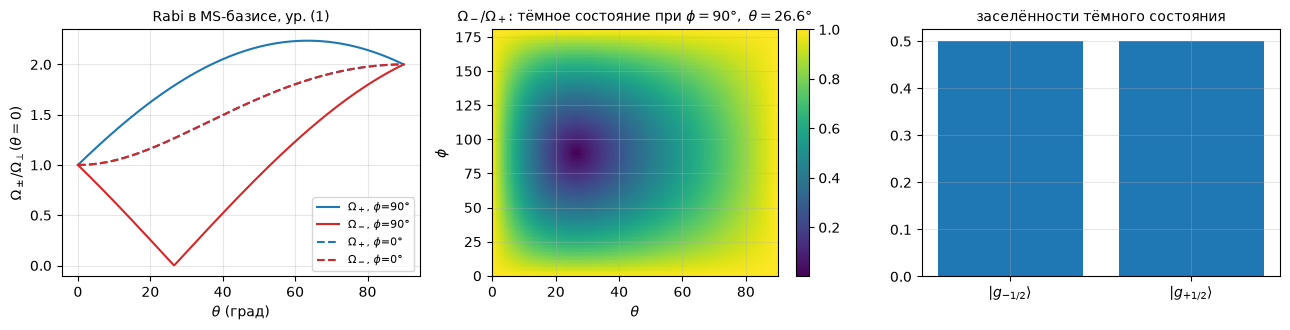

In [145]:
def ms_transform(V):
    U_e, sv, U_gh = np.linalg.svd(V)
    return sv, U_e, U_gh.conj().T                    # (Omega_+, Omega_-), базисы e и g

def eq_B2(Op, Osp, Osm):
    a, b = abs(Osp)**2, abs(Osm)**2
    rad = np.sqrt(0.25*(a - b)**2 + abs(Op)**2*(a + b) + 2*np.real(Op**2*np.conj(Osp)*np.conj(Osm)) + 0j).real
    base = abs(Op)**2 + a/2 + b/2
    return np.sqrt(base + rad), np.sqrt(max(base - rad, 0))

def eq_1(theta, phi):          # в единицах c*E, т.е. Omega при theta=0 равна 1
    Ep, Epar = np.cos(theta), np.sin(theta)
    r = 2*Ep*Epar*np.sqrt(2*(1 - np.cos(2*phi)))
    return np.sqrt(Ep**2 + 4*Epar**2 + r), np.sqrt(np.maximum(Ep**2 + 4*Epar**2 - r, 0))

rng = np.random.default_rng(0); err = 0
for _ in range(200):                                   # случайные поляризации и направления B
    E = rng.normal(size=3) + 1j*rng.normal(size=3); Bv = rng.normal(size=3)
    V = coupling_matrix(E, Bv)
    sv, _, _ = ms_transform(V)
    err = max(err, np.max(np.abs(np.array(eq_B2(V[0, 0], V[1, 0], V[0, 1])) - sv)))
print("max |SVD - (B2)| по 200 случайным конфигурациям:", err)

th = np.linspace(0, np.pi/2, 361); err1 = 0
for ph in (0, np.pi/2, 0.7):
    for t in th[::10]:
        V = coupling_matrix(pol_vector(t, ph), Bhat, xhat=[1, 0, 0])*np.sqrt(6)
        err1 = max(err1, np.max(np.abs(ms_transform(V)[0] - np.array(eq_1(t, ph)))))
print("max |SVD - (1)| :", err1)
print("тёмный угол при phi=pi/2: arctan(1/2) =", np.degrees(np.arctan(0.5)), "град")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for ph, ls in [(np.pi/2, '-'), (0, '--')]:
    Op, Om = eq_1(th, ph)
    ax[0].plot(np.degrees(th), Op, 'C0'+ls, label=f'$\\Omega_+$, $\\phi$={np.degrees(ph):.0f}°')
    ax[0].plot(np.degrees(th), Om, 'C3'+ls, label=f'$\\Omega_-$, $\\phi$={np.degrees(ph):.0f}°')
ax[0].set_xlabel(r'$\theta$ (град)'); ax[0].set_ylabel(r'$\Omega_\pm/\Omega_\perp(\theta=0)$'); ax[0].legend(); ax[0].set_title('Rabi в MS-базисе, ур. (1)')
TH, PH = np.meshgrid(np.linspace(0, 90, 181), np.linspace(0, 180, 181))
Op, Om = eq_1(np.radians(TH), np.radians(PH))
im = ax[1].pcolormesh(TH, PH, Om/Op, shading='auto', cmap='viridis'); plt.colorbar(im, ax=ax[1])
ax[1].set_xlabel(r'$\theta$'); ax[1].set_ylabel(r'$\phi$'); ax[1].set_title(r'$\Omega_-/\Omega_+$: тёмное состояние при $\phi=90°,\ \theta=26.6°$')
# состав тёмного состояния
V = coupling_matrix(pol_vector(np.arctan(.5), np.pi/2), Bhat, xhat=[1, 0, 0])
sv, Ue, Ug = ms_transform(V)
print("Omega_+-, (theta_dark, phi=pi/2):", sv.round(6), "\n|g_dark> в базисе (g-, g+):", np.round(Ug[:, 1], 4))
ax[2].bar(['$|g_{-1/2}\\rangle$', '$|g_{+1/2}\\rangle$'], np.abs(Ug[:, 1])**2); ax[2].set_title('заселённости тёмного состояния')
plt.tight_layout(); plt.show()

---
## §4. Уравнение Линдблада: стационарная скорость рассеяния (2), App. C, секулярное приближение

**Задача.** Вычислить полную скорость рассеяния $R_{\rm tot}=\Gamma\,\mathrm{Tr}(\hat P_e\hat\rho_{ss})$ без MS-упрощений и сравнить с (2).

**Модель.** Мастер-уравнение (марковское, борновское приближения для вакуумного резервуара):
$$\dot{\hat\rho}=-\tfrac{i}{\hbar}[\tilde H,\hat\rho]+\sum_{q=-1}^{1}\Big(\hat C_q\hat\rho\hat C_q^\dagger-\tfrac12\{\hat C_q^\dagger\hat C_q,\hat\rho\}\Big),\qquad
\hat C_q=\sqrt\Gamma\sum_{m,m'}\langle\tfrac12m;1q|\tfrac32m'\rangle\,|g_m\rangle\langle e_{m'}|.$$
**Важно:** операторы скачков нумеруются **поляризацией** испущенного фотона $q$, а не отдельными переходами. Если завести отдельный оператор на каждый переход $|g_m\rangle\langle e_{m'}|$, теряются когерентности основного состояния, которые создаёт спонтанный распад. Это ошибка, а не просто иное приближение: поляризации разных фотонов ортогональны, а переходы с одной $q$ — нет. Проверка: $\sum_q\hat C_q^\dagger\hat C_q=\Gamma\hat P_e$ (сумма правило из §1).

**Численно.** `qutip.steadystate(H, c_ops)` — ядро супероператора Линдблада $\mathcal L$ (16×16) с условием $\mathrm{Tr}\rho=1$. Символьно (sympy) решаем стационар модели (C1) при произвольных $f,\Omega_\pm,\Delta$.

**Формула (2) и App. C.** В MS-базисе (C1) — две двухуровневые системы, связанные только распадом: доля $f$ уходит «к себе», $1-f$ — «в соседний сектор». В стационаре:
* Из баланса населённостей секторов: $\dot P_-=-(1-f)\Gamma(\rho_{e_-e_-}-\rho_{e_+e_+})=0\Rightarrow\rho_{e_-e_-}=\rho_{e_+e_+}$. Это первая строка (C2). Неочевидный вывод: **населённости возбуждённых состояний равны при любых $s_\pm$, а от $f$ результат не зависит.**
* В каждом секторе двухуровневый стационар: $\rho_{ee}=P\cdot\frac{s/2}{1+s+(2\Delta/\Gamma)^2}$, то есть $P_\pm=\frac{2(1+s_\pm+\delta^2)}{s_\pm}\rho_{e_\pm e_\pm}$, $\delta\equiv2\Delta/\Gamma$.
* Нормировка $P_++P_-=1$: $\sum_\pm\frac{2(1+s_\pm+\delta^2)}{s_\pm}\rho_{e_\pm e_\pm}=1$. **Во второй строке (C2) статьи потерян множитель 2.** С ним получается $R_{\rm tot}=2\Gamma\rho_{ee}$, то есть ровно (2); без него результат был бы вдвое больше.
* Итог: $R_{\rm tot}=\frac{2R_+R_-}{R_++R_-}$ — гармоническое среднее. Эквивалентно $R_{\rm tot}=\frac\Gamma2\frac{s_{\rm tot}}{1+s_{\rm tot}+\delta^2}$ с $s_{\rm tot}=\frac{2s_+s_-}{s_++s_-}$.

**Смысл.** Населённость основного состояния распределяется обратно пропорционально скорости откачки: «медленный» сектор накапливает атом. При $s_-\to0$ атом застревает в $|g_-\rangle$, и $R_{\rm tot}\to0$.

Ниже проверяем, остаётся ли (2) точным в полной 4-уровневой модели, где кросс-когерентности между MS-секторами сохранены.

In [ ]:
def jump_ops(mprime=(-0.5, 0.5), Gamma=1.0):
    '''C_q (qutip Qobj) в базисе (g-, g+, e(m')...), q=-1,0,1.'''
    n = 2 + len(mprime); Cs = []
    for q in (-1, 0, 1):
        Cq = np.zeros((n, n))
        for j, mp in enumerate(mprime):
            for i, mm in enumerate((-0.5, 0.5)):
                Cq[i, 2 + j] = cg(0.5, mm, 1, q, 1.5, mp)
        Cs.append(qt.Qobj(np.sqrt(Gamma)*Cq))
    return Cs

C4 = jump_ops()
P_e4 = qt.Qobj(np.diag([0, 0, 1., 1.]))
print("sum_q C_q^dag C_q = P_e ?", (sum(Cq.dag()*Cq for Cq in C4) - P_e4).norm() < 1e-12)

def R_lindblad(V, Delta, delta_g=0.0, return_rho=False):
    '''qutip.steadystate; V, Delta, delta_g в единицах Gamma; возвращает R_tot/Gamma.'''
    rho = qt.steadystate(qt.Qobj(H_rwa(V, Delta, delta_g)), C4)
    R = qt.expect(P_e4, rho)
    return (R, rho.full()) if return_rho else R

def R_eq2(s_p, s_m, Delta):
    st = 2*s_p*s_m/(s_p + s_m) if s_p*s_m > 0 else 0.0
    return 0.5*st/(1 + st + (2*Delta)**2)

def V_for(theta, phi, s_ref):
    '''Нормируем так, чтобы при theta=0 (чистая E_perp) s_+-=2 Omega^2/Gamma^2 = s_ref.'''
    V = coupling_matrix(pol_vector(theta, phi), Bhat, xhat=[1, 0, 0])*np.sqrt(6)   # Omega(theta=0)=1
    return V*np.sqrt(s_ref/2)

worst = {}
for ph in (np.pi/2, 0.0, 0.4):
    dev = []
    for t in np.radians(np.linspace(0, 90, 46)):
        for D in (-0.3, -0.92, -2.0):
            V = V_for(t, ph, 2.0); sv = ms_transform(V)[0]; s_p, s_m = 2*sv**2
            dev.append(abs(R_lindblad(V, D) - R_eq2(s_p, s_m, D))/max(R_eq2(s_p, s_m, D), 1e-12))
    worst[f"phi={np.degrees(ph):.0f}°"] = max(dev)
print("max относительное отклонение Lindblad vs (2) при delta_g=0:", {k: f"{v:.1e}" for k, v in worst.items()})

# доля f и равенство возбуждённых населённостей (C2)
V = V_for(np.radians(40), np.pi/2, 2.0); sv, Ue, Ug = ms_transform(V)
R, rho = R_lindblad(V, -0.92, return_rho=True)
T = np.block([[Ug, np.zeros((2, 2))], [np.zeros((2, 2)), Ue]])      # (g+,g-,e+,e-) MS -> исходный
rho_ms = T.conj().T @ rho @ T
f_minus = sum(abs((T.conj().T @ Cq.full() @ T)[1, 3])**2 for Cq in C4)   # e- -> g-  в MS-базисе
print(f"theta=40°, phi=90°:  f = {f_minus:.4f};  rho_e+e+ = {rho_ms[2,2].real:.5f}, rho_e-e- = {rho_ms[3,3].real:.5f} (C2: равны)")
print(f"   R_tot/Gamma: Lindblad {R:.6f}  vs  ур.(2) {R_eq2(*(2*sv**2), -0.92):.6f}")
print(f"   то же, если в (C2) не исправлять множитель 2: {2*R_eq2(*(2*sv**2), -0.92):.6f}  (вдвое больше -> опечатка)")

sum_q C_q^dag C_q = P_e ? True
max относительное отклонение Lindblad vs (2) при delta_g=0: {'phi=90°': '2.6e-13', 'phi=0°': '4.0e-16', 'phi=23°': '8.9e-16'}
theta=40°, phi=90°:  f = 0.8333;  rho_e+e+ = 0.04697, rho_e-e- = 0.04697 (C2: равны)
   R_tot/Gamma: Lindblad 0.093940  vs  ур.(2) 0.093940
   то же, если в (C2) не исправлять множитель 2: 0.187880  (вдвое больше -> опечатка)


rho_e-e- - rho_e+e+ = 0   (первая строка C2)
dR_tot/df = 0   (от f не зависит)
R_tot - Gamma/2 s_tot/(1+s_tot+delta^2) = 0   (ур. (2))
P_- / [2(1+s_-+delta^2)/s_- * rho_e-e-] = 1  (множитель 2 в нормировке C2)


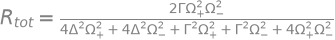

In [154]:
# --- символьно: стационар модели (C1) для произвольных f, Omega_+-, Delta  ->  (C2) и (2)
f_, G_, Op_, Om_ = sp.symbols('f Gamma Omega_+ Omega_-', positive=True)
gm, em, xm, ym, gp, ep, xp, yp = sp.symbols('g_- e_- x_- y_- g_+ e_+ x_+ y_+', real=True)   # rho_ge = x + i y
def sector(gg, ee, x, y, Om, gain):
    # уравнения (C1) для одного сектора; gain - приход в g за счёт распада
    return [gain + Om*y,                         # d rho_gg/dt
            -G_*ee - Om*y,                       # d rho_ee/dt
            -G_/2*x + D_*y,                      # Re d rho_ge/dt
            -G_/2*y - D_*x + Om/2*(ee - gg)]     # Im d rho_ge/dt
eqs = sector(gm, em, xm, ym, Om_, f_*G_*em + (1 - f_)*G_*ep) + sector(gp, ep, xp, yp, Op_, (1 - f_)*G_*em + f_*G_*ep)
eqs = eqs[1:] + [gm + em + gp + ep - 1]           # одно уравнение баланса лишнее -> нормировка
sol = sp.solve(eqs, [gm, em, xm, ym, gp, ep, xp, yp], dict=True)[0]
Rtot_sym = sp.simplify(G_*(sol[em] + sol[ep]))
s_p_, s_m_ = 2*Op_**2/G_**2, 2*Om_**2/G_**2; dl_ = 2*D_/G_
st_ = 2*s_p_*s_m_/(s_p_ + s_m_)
print("rho_e-e- - rho_e+e+ =", sp.simplify(sol[em] - sol[ep]), "  (первая строка C2)")
print("dR_tot/df =", sp.simplify(sp.diff(Rtot_sym, f_)), "  (от f не зависит)")
print("R_tot - Gamma/2 s_tot/(1+s_tot+delta^2) =", sp.simplify(Rtot_sym - G_/2*st_/(1 + st_ + dl_**2)), "  (ур. (2))")
P_minus = sp.simplify(sol[gm] + sol[em])
print("P_- / [2(1+s_-+delta^2)/s_- * rho_e-e-] =", sp.simplify(P_minus/(2*(1 + s_m_ + dl_**2)/s_m_*sol[em])), " (множитель 2 в нормировке C2)")
display(sp.Eq(sp.Symbol('R_tot'), sp.factor(Rtot_sym)))

**Вывод.** Формула (2) оказывается **точной** для полной 4-уровневой модели при $\delta_g=0$ и любой поляризации, а не только при $\phi=0,\pi/2$. Отклонение на уровне машинной точности. Кросс-когерентности, которые (C1) не учитывает, в стационар не входят.

### Нарушения MS: ядерный зееман и секулярное приближение
1. **$\delta_g\neq0$.** В вращающейся системе член $\tfrac{\delta_g}{2}\sigma_z$ на основных уровнях убрать нельзя: оба тона связывают оба $g$ с разными $e$, и фазовые условия совместны только при $\omega_{g+}=\omega_{g-}$. Он работает как двухфотонная (рамановская) отстройка. Тёмное состояние $|g_-\rangle$ прецессирует в светлое со скоростью $\sim\delta_g$, и откачка из него становится $\sim\delta_g^2/\Gamma_{\rm opt}$.
2. **Секулярное приближение.** Решаем полное зависящее от времени уравнение для 6 уровней ($e_{\pm1/2},e_{\pm3/2}$, оба тона на всех переходах) в системе отсчёта, вращающейся с $\omega_0$. Затем сравниваем усреднённое по времени $\langle P_e\rangle$ с RWA-стационаром.

In [ ]:

H = [qt.Qobj(H0), [qt.Qobj(Wf), f], [qt.Qobj(Wf.conj().T), fc]]
mp6 = (-1.5, -0.5, 0.5, 1.5)
rh0 = qt.Qobj(np.zeros((6,1)))
res = qt.mesolve(H, rho0, ts, c_ops=jump_ops(mp6))


Quantum object: dims=[[6], [1]], shape=(6, 1), type='ket', dtype=Dense
Qobj data =
[[0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]]

In [ ]:
# 1) влияние delta_g на тёмное состояние (phi = pi/2)
thg = np.radians(np.linspace(0, 90, 361)); D = -0.92
dg_G = dg*2*np.pi/Gam
Rg0 = [R_lindblad(V_for(t, np.pi/2, 2), D) for t in thg]
Rg1 = [R_lindblad(V_for(t, np.pi/2, 2), D, dg_G) for t in thg]
i0 = np.argmin(Rg1)
print(f"delta_g = {dg_G:.4f} Gamma: в минимуме R/Gamma = {Rg1[i0]:.2e} при theta = {np.degrees(thg[i0]):.2f}°  (без delta_g: {min(Rg0):.1e})")
print(f"  отношение к R(theta=0): {Rg1[i0]/Rg1[0]:.3f} -> дно провала поднимается до ~4% от R(0), положение минимума почти не меняется")

# 2) секулярное приближение: 6 уровней, оба тона, явная зависимость от времени
mp6 = (-1.5, -0.5, 0.5, 1.5)
def full_td_Pe(theta, phi, s_ref, Delta, dZ_G, dg_G=0.0, t_end=40.0, t_avg=10.0):
    '''qutip.mesolve: 6 уровней, оба тона на всех переходах, H(t) = H0 + W f(t) + W^dag f*(t) в системе omega_0'''
    E = pol_vector(theta, phi)
    W = coupling_matrix(E, Bhat, mprime=mp6, xhat=[1, 0, 0])*np.sqrt(6)*np.sqrt(s_ref/2)/2
    n = 6; H0 = np.zeros((n, n), complex)
    H0[0, 0], H0[1, 1] = -dg_G/2, dg_G/2
    for j, mp in enumerate(mp6): H0[2 + j, 2 + j] = dZ_G*mp
    Wf = np.zeros((n, n), complex); Wf[2:, :2] = W
    nus = (dZ_G/2 + Delta, -dZ_G/2 + Delta)
    f = lambda t: np.exp(-1j*nus[0]*t) + np.exp(-1j*nus[1]*t)
    fc = lambda t: np.exp(1j*nus[0]*t) + np.exp(1j*nus[1]*t)
    H = [qt.Qobj(H0), [qt.Qobj(Wf), f], [qt.Qobj(Wf.conj().T), fc]]
    rho0 = qt.Qobj(np.diag([.5, .5, 0, 0, 0, 0]).astype(complex))
    Pe6 = qt.Qobj(np.diag([0, 0, 1., 1, 1, 1]))
    ts = np.concatenate([[0], np.linspace(t_end - t_avg, t_end, 4001)])
    res = qt.mesolve(H, rho0, ts, c_ops=jump_ops(mp6), e_ops=[Pe6],
                     options={"nsteps": 10**7, "atol": 1e-10, "rtol": 1e-8, "method": "adams", "max_step": 0.005})
    Pe = np.array(res.expect[0][1:]).real
    return Pe.mean(), Pe

t0 = time.time()
for (th_, ph_) in [(0.0, 0.0), (np.radians(60), 0.0), (np.radians(45), np.pi/2)]:
    Pe_full, _, __ = full_td_Pe(th_, ph_, 2.0, -0.92, dZ*2*np.pi/Gam)
    Pe_rwa = R_lindblad(V_for(th_, ph_, 2.0), -0.92)
    print(f"theta={np.degrees(th_):4.0f}°, phi={np.degrees(ph_):3.0f}°:  <P_e> полная = {Pe_full:.5f},  RWA 4 ур. = {Pe_rwa:.5f},  "
          f"отн. разница = {abs(Pe_full/Pe_rwa - 1):.1e}")
print(f"(время {time.time()-t0:.1f} с)")

delta_g = 0.0618 Gamma: в минимуме R/Gamma = 6.93e-03 при theta = 26.75°  (без delta_g: 2.9e-06)
  отношение к R(theta=0): 0.044 -> дно провала поднимается до ~4% от R(0), положение минимума почти не меняется
theta=   0°, phi=  0°:  <P_e> полная = 0.15670,  RWA 4 ур. = 0.15660,  отн. разница = 6.3e-04
theta=  60°, phi=  0°:  <P_e> полная = 0.29859,  RWA 4 ур. = 0.29856,  отн. разница = 9.4e-05
theta=  45°, phi= 90°:  <P_e> полная = 0.14567,  RWA 4 ур. = 0.14550,  отн. разница = 1.2e-03
(время 3.2 с)


**Вывод.**
* $\delta_g=11$ кГц поднимает дно тёмного провала с $\sim10^{-5}$ до $\approx4\%$ от $R(\theta{=}0)$. Порядок величины: тёмное состояние перемешивается со светлым со скоростью $\delta_g$ и выкачивается за время $\sim\Gamma_{\rm opt}/\delta_g^2$. Положение минимума смещается лишь на 0.2°. Для Fig. 2 это малая, но в принципе измеримая поправка.
* Секулярное приближение (отбрасывание «чужого» тона и уровней $e_{\pm3/2}$) даёт относительную поправку к $\langle P_e\rangle$ порядка $10^{-3}$. Это световые сдвиги $\sim\Omega^2/4\delta_Z$ от нерезонансных связей. В полном решении $P_e(t)$ дрожит на частотах $\sim\delta_Z$; после усреднения дрожание исчезает.

### Почему нужен именно двойной тон: оптическая накачка в тёмное состояние (Fig. 2(a,b))
С одним тоном (только $e_-$) система $\{g_-,g_+\}\to e_-$ — Λ-схема. Для неё **всегда** есть тёмная суперпозиция $|g_d\rangle\propto\Omega_{\sigma-}|g_-\rangle-\Omega_\pi|g_+\rangle$, ортогональная связи. Атом за несколько рассеяний накачивается в неё, и флуоресценция гаснет. Это видно по эволюции (qutip `mesolve`) с $\hat\rho(0)=\tfrac12(|g_-\rangle\langle g_-|+|g_+\rangle\langle g_+|)$.

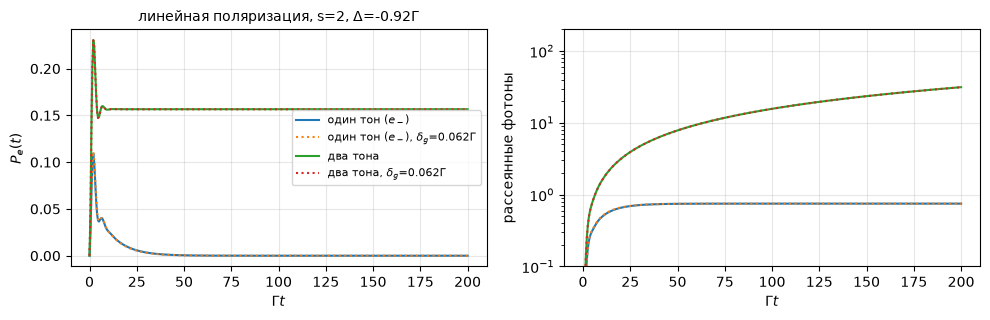

один тон: всего рассеивается ~0.75 фотона, после чего атом в тёмном состоянии


In [38]:
def evolve_photons(V, Delta, tones=('-', '+'), delta_g=0.0, tmax=200., nt=400):
    '''qutip.mesolve: P_e(t) и число рассеянных фотонов N(t) = Gamma int P_e dt'''
    V = V.copy()
    if '+' not in tones: V[1, :] = 0
    if '-' not in tones: V[0, :] = 0
    ts = np.linspace(0, tmax, nt)
    res = qt.mesolve(qt.Qobj(H_rwa(V, Delta, delta_g)), qt.Qobj(np.diag([.5, .5, 0, 0]).astype(complex)), ts,
                     c_ops=C4, e_ops=[P_e4], options={"nsteps": 10**6})
    Pe = np.array(res.expect[0]).real
    Nph = integrate.cumulative_trapezoid(Pe, ts, initial=0)
    return ts, Pe, Nph

V = V_for(0.0, 0.0, 2.0)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
for tones, lab in [(('-',), 'один тон ($e_-$)'), (('-', '+'), 'два тона')]:
    for dgv, ls in [(0, '-'), (dg_G, ':')]:
        ts, Pe, N = evolve_photons(V, -0.92, tones, dgv)
        ax[0].plot(ts, Pe, ls, label=lab + (f', $\\delta_g$={dgv:.3f}Γ' if dgv else ''))
        ax[1].plot(ts, N, ls)
ax[0].set_xlabel(r'$\Gamma t$'); ax[0].set_ylabel(r'$P_e(t)$'); ax[0].legend(); ax[0].set_title('линейная поляризация, s=2, Δ=-0.92Γ')
ax[1].set_xlabel(r'$\Gamma t$'); ax[1].set_ylabel('рассеянные фотоны'); ax[1].set_yscale('log'); ax[1].set_ylim(.1, 200)
plt.tight_layout(); plt.show()
ts, Pe, N = evolve_photons(V, -0.92, ('-',), 0)
print(f"один тон: всего рассеивается ~{N[-1]:.2f} фотона, после чего атом в тёмном состоянии")

---
## §5. Fig. 2(c,d): зависимость скорости счёта от угла поляризации

**Задача.** Построить теоретические линии Fig. 2(c) ($\phi=\pi/2$) и 2(d) ($\phi=0$) при фиксированной входной интенсивности ($s=2$ при $\theta=0$), $\Delta=-0.92\Gamma$, $R_{\rm det}=\eta R_{\rm tot}$, $\eta=2.24\%$.

**Штриховая линия (без кюветы).** Подставляем (1) в (2).

**Сплошная линия (с кюветой).** Пучок лежит в плоскости $xz$ (горизонтальной), а поле $\mathbf B\parallel y$ вертикально. Для стенки кюветы, нормаль к которой лежит в плоскости $xz$, плоскость падения — $xz$. Значит, $\mathcal E_\parallel\parallel y$ — это **S**-поляризация, а $\mathcal E_\perp$ (в плоскости $xz$) — **P**. Непросветлённое стекло пропускает P лучше S, поэтому после кюветы $\mathcal E_\parallel/\mathcal E_\perp=(t_S/t_P)\tan\theta$. Тёмное условие $|\mathcal E_\perp|=2|\mathcal E_\parallel|$ даёт $\tan\theta_d=\tfrac12\,t_P/t_S$, то есть смещение минимума к большим $\theta$.

**Оценка.** Две границы стекла с $n=1.45$, по формулам Френеля для мощности $T_{S,P}$; амплитудное отношение $t_P/t_S=\sqrt{T_P^2/T_S^2}$. Угол падения на стенку не указан. Для пучка под 52° к оси $z$ возможны 52° (стенка $\perp z$) или 38° (стенка $\perp x$). Нормировка: $s=2$ задано при $\theta=0$, где поле чисто P.

**Обе фазы φ создаются одной оптикой.** Полуволновая пластинка поворачивает поляризацию, а неподвижная четвертьволновая задаёт сдвиг фаз $\pi/2$ между $\mathcal E_\perp$ и $\mathcal E_\parallel$ ($\phi=\pi/2$). Френелевское пропускание вещественно и фазу не меняет.

падение 38°: T_S=0.938, T_P=0.987 на границу;  t_P/t_S (2 границы) = 1.052;  тёмный угол = 27.7°
падение 52°: T_S=0.892, T_P=0.999 на границу;  t_P/t_S (2 границы) = 1.120;  тёмный угол = 29.2°


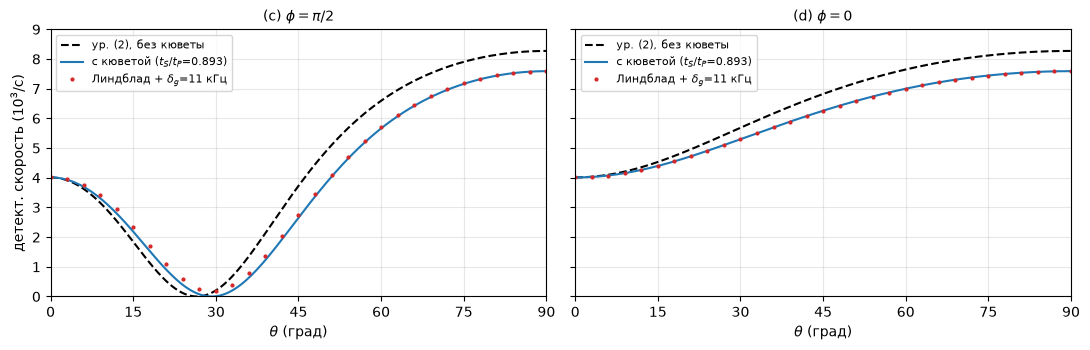

theta=0  : 4.01 x10^3/с  (s=2)
theta=90 : phi=0 -> 7.59 x10^3/с (s=8*kappa^2=6.38);  без кюветы 8.27


In [39]:
def fresnel_T(theta_i, n=1.45):
    st = np.sin(theta_i)/n; tt = np.arcsin(st)
    rs = (np.cos(theta_i) - n*np.cos(tt))/(np.cos(theta_i) + n*np.cos(tt))
    rp = (n*np.cos(theta_i) - np.cos(tt))/(n*np.cos(theta_i) + np.cos(tt))
    return 1 - rs**2, 1 - rp**2                       # T_S, T_P (одна граница)

for ang in (38, 52):
    TS, TP = fresnel_T(np.radians(ang))
    ratio = np.sqrt(TP**2/TS**2)                       # две границы: in + out
    print(f"падение {ang}°: T_S={TS:.3f}, T_P={TP:.3f} на границу;  t_P/t_S (2 границы) = {ratio:.3f};  "
          f"тёмный угол = {np.degrees(np.arctan(0.5*ratio)):.1f}°")
TS, TP = fresnel_T(np.radians(52)); kappa = np.sqrt(TS**2/TP**2)     # t_S/t_P

def rate_det(theta, phi, s0=2.0, Delta=-0.92, kappa=1.0, dual=True, delta_g=0.0, exact=True):
    '''детектируемая скорость, 1/с. kappa = t_S/t_P (кювета).'''
    E = np.exp(1j*phi)*np.cos(theta)*np.array([1, 0, 0], complex) + kappa*np.sin(theta)*np.array([0, 1, 0], complex)
    V = coupling_matrix(E, Bhat, xhat=[1, 0, 0])*np.sqrt(6)*np.sqrt(s0/2)
    if exact:
        R = R_lindblad(V, Delta, delta_g)
    else:
        sv = ms_transform(V)[0]; R = R_eq2(*(2*sv**2), Delta)
    return eta_det*Gam*R

thd = np.radians(np.linspace(0, 90, 181))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, ph, title in [(ax[0], np.pi/2, r'(c) $\phi=\pi/2$'), (ax[1], 0.0, r'(d) $\phi=0$')]:
    a.plot(np.degrees(thd), [rate_det(t, ph, exact=False)/1e3 for t in thd], 'k--', label='ур. (2), без кюветы')
    a.plot(np.degrees(thd), [rate_det(t, ph, kappa=kappa, exact=False)/1e3 for t in thd], 'C0-', label=f'с кюветой ($t_S/t_P$={kappa:.3f})')
    a.plot(np.degrees(thd[::6]), [rate_det(t, ph, kappa=kappa, delta_g=dg_G)/1e3 for t in thd[::6]], 'C3.', ms=4,
           label=r'Линдблад + $\delta_g$=11 кГц')
    a.set_xlabel(r'$\theta$ (град)'); a.set_title(title); a.set_xlim(0, 90); a.set_xticks(range(0, 91, 15)); a.legend()
ax[0].set_ylabel(r'детект. скорость ($10^3$/с)'); ax[0].set_ylim(0, 9)
plt.tight_layout(); plt.show()
print(f"theta=0  : {rate_det(0, 0)/1e3:.2f} x10^3/с  (s=2)")
print(f"theta=90 : phi=0 -> {rate_det(np.pi/2, 0, kappa=kappa)/1e3:.2f} x10^3/с (s=8*kappa^2={8*kappa**2:.2f});  без кюветы {rate_det(np.pi/2, 0)/1e3:.2f}")

**Смысл и сравнение.**
* При $\theta=0$ получаем $4.0\times10^3$ с⁻¹, при $\theta=90^\circ$ и $\phi=0$ — $8.3\times10^3$ с⁻¹ без кюветы (насыщение растёт в 4 раза, так как $\Omega_\pi=2\Omega_\perp$). Это совпадает с крайними значениями на осях Fig. 2(c,d).
* Френелевский учёт непросветлённой кюветы (падение около 52°) сдвигает тёмный угол с 26.6° к ≈29°. Это объясняет экспериментальный минимум «около 30°» без подгоночных параметров. Мы не знаем точной геометрии кюветы, так что совпадение — правдоподобная оценка, а не доказательство.
* $\delta_g=11$ кГц (красные точки) поднимают дно провала до нескольких процентов. На масштабе Fig. 2 это едва заметно, но объясняет, почему экспериментальный минимум не идёт строго в ноль.

---
## §6. Доплеровское охлаждение в свободном пространстве (база для App. D)

**Задача.** Получить силу трения $\alpha$, коэффициент диффузии $D_p$ и равновесную температуру для ретро-отражённой пары пучков. Скорость рассеяния описывается (2), как для двухуровневого атома (§4).

**Обозначения.** $\delta\equiv2\Delta/\Gamma$; $s$ — насыщение пары, $s/2$ — одного пучка; $S=\sum_i s_i$ — полное насыщение всеми парами (знаменатель).

**Допущения.** (i) Скорости рассеяния от разных пучков **складываются**, интерференция не учитывается (так же в App. D). (ii) $|k v|\ll|\Delta|,\Gamma$: силу можно линеаризовать. (iii) Отдача мала: $E_r\ll k_BT$, и каждое рассеяние меняет импульс на малую величину.

**Вывод.**
1. Сила от пучка $\pm\hat k$: $F_\pm=\pm\hbar k\,\frac\Gamma2\,\frac{s/2}{1+S+[2(\Delta\mp kv)/\Gamma]^2}$, где $\hbar k\times$скорость рассеяния — передача импульса при поглощении.
2. Раскладываем по $v$: $\partial_v\big[1+S+(2(\Delta-kv)/\Gamma)^2\big]^{-1}\big|_0=\frac{4k\delta/\Gamma}{(1+S+\delta^2)^2}$. Отсюда
$$F=-\alpha v,\qquad \alpha=-4\hbar k^2\,\frac{s}{2}\,\frac{\delta}{(1+S+\delta^2)^2}>0\ \text{при}\ \delta<0 .$$
Это в точности (D3) статьи (с $\tfrac{s_i}{2}$ и весом $(\hat k_i\cdot\hat v)^2$ для 3D).
3. Нагрев. Каждое рассеяние даёт два случайных толчка $\hbar k$: поглощение (вдоль $\pm\hat k$) и испускание (по диаграмме направленности). Средний квадрат изменения импульса за рассеяние равен $2(\hbar k)^2$, поэтому $\frac{d}{dt}\langle|\mathbf p|^2\rangle=2(\hbar k)^2R=2D_p$ с $D_p=\hbar^2k^2R$ — это (D4).
4. **Энергетический баланс** — ключ к пинцету. Нагрев полной энергии $\dot E_+=D_p/m$. Охлаждение $\dot E_-=\alpha\langle(\hat k\cdot\mathbf v)^2\rangle/m$. Если движение в ловушке термализовано (ангармонизм перемешивает степени свободы), то $\langle(\hat k\cdot\mathbf v)^2\rangle=k_BT/m$ **при любом направлении $\hat k$**, и
$$k_BT=\frac{D_p}{\alpha}=\frac{\hbar\Gamma}{4}\,\frac{1+S+\delta^2}{|\delta|}.$$
5. Минимум по $\delta$: $\delta_{\rm opt}=-\sqrt{1+S}$, то есть $\Delta_{\rm opt}=-\sqrt{1+S}\,\Gamma/2$, и $k_BT_{\min}=\frac{\hbar\Gamma}{2}\sqrt{1+S}$.

**Смысл.** Одна наклонная пара пучков в идеальном (перемешивающем) пинцете охлаждает все три степени свободы до той же температуры, что 3D-патока. Если перемешивания нет (анизотропия, вырождение частот), энергия в «неохлаждаемых» направлениях растёт, и $T$ выше. Это главная тема Fig. 3(a).

**Применимость.** $kv_{\rm rms}/\Gamma\approx0.2$ при 10 мкК при $|\delta|\sim1$–2. Кубический член $\beta v^3$ (sympy ниже) показывает, где ломается линеаризация: при $\delta=-2$ поправка ~1%, при $\delta=-1$ уже ~4% на $kv=0.2\Gamma$ и ~25% в хвосте распределения ($kv\approx0.5\Gamma$). Поэтому при малых $|\Delta|$ линейная теория переоценивает охлаждение (проверено моделью с дискретными фотонами в §8). $E_r/k_B=0.18$ мкК $\ll T$.

F = -alpha v + beta v^3 + ...;  alpha =


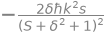

beta (кубическая поправка) =


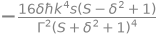

k_B T = D_p / alpha =


оптимум delta: [-sqrt(S + 1)]


относительная кубическая поправка к силе при kv = 0.2 Gamma, delta=-2, S=2: -0.007
то же при delta=-1 (Delta=-Gamma/2):                                   +0.040;  при kv = 0.5 Gamma: +0.250


In [40]:
# --- символьный вывод (sympy): сила двух пучков -> трение, нелинейность, диффузия, температура, оптимум
v_, k_, hb_, Gs_, ss_, Ss_, Ds_ = sp.symbols('v k hbar Gamma s S Delta', real=True)
dl_s = sp.symbols('delta', negative=True)                                # delta = 2 Delta / Gamma < 0
Fbeam = lambda sg: sg*hb_*k_*Gs_/2*(ss_/2)/(1 + Ss_ + (2*(Ds_ - sg*k_*v_)/Gs_)**2)
Fmol = Fbeam(1) + Fbeam(-1)
ser = sp.series(Fmol, v_, 0, 4).removeO().subs(Ds_, dl_s*Gs_/2)
alpha_s = sp.factor(sp.simplify(-ser.coeff(v_, 1)))
beta_s = sp.factor(sp.simplify(ser.coeff(v_, 3)))
print("F = -alpha v + beta v^3 + ...;  alpha ="); display(alpha_s)
print("beta (кубическая поправка) ="); display(beta_s)
R_s = Gs_/2*ss_/(1 + Ss_ + dl_s**2); Dp_s = hb_**2*k_**2*R_s
kT_s = sp.simplify(Dp_s/alpha_s)
print("k_B T = D_p / alpha ="); display(kT_s)
dopt = sp.solve(sp.diff(kT_s, dl_s), dl_s); print("оптимум delta:", dopt)
display(sp.Eq(sp.Symbol('k_B T_min'), sp.simplify(kT_s.subs(dl_s, dopt[0]))))
# масштаб нелинейности: |beta/alpha| (kv)^2 / Gamma^2 при delta=-2, S=2 и kv = 0.2 Gamma
nl = sp.simplify((beta_s/alpha_s*k_**-2*Gs_**2)).subs({dl_s: -2, Ss_: 2})
print(f"относительная кубическая поправка к силе при kv = 0.2 Gamma, delta=-2, S=2: {float(nl*0.04):+.3f}")
nl1 = sp.simplify((beta_s/alpha_s*k_**-2*Gs_**2)).subs({dl_s: -1, Ss_: 2})
print(f"то же при delta=-1 (Delta=-Gamma/2):                                   {float(nl1*0.04):+.3f};  при kv = 0.5 Gamma: {float(nl1*0.25):+.3f}")

 s    Delta_opt/Gamma   T_min(теория) мкК   T_min(МК статьи, пинцет) мкК   отношение
 0.1     -0.524            4.58                4.9                   1.07
   1     -0.707            6.18                7.1                   1.15
   2     -0.866            7.56                8.8                   1.16
   3     -1.000            8.73               10.3                   1.18


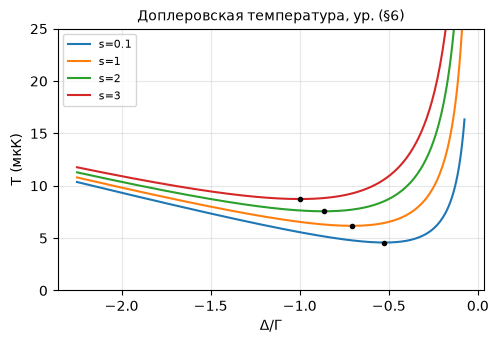

In [41]:
def T_doppler(delta, S):
    '''k_B T (в мкК) = hbar Gamma (1+S+delta^2)/(4|delta|),  delta = 2 Delta / Gamma'''
    return hbar*Gam*(1 + S + delta**2)/(4*np.abs(delta))/kB*1e6

paper_MC = {0.1: 4.9, 1: 7.1, 2: 8.8, 3: 10.3}
print(" s    Delta_opt/Gamma   T_min(теория) мкК   T_min(МК статьи, пинцет) мкК   отношение")
for s_, Tp in paper_MC.items():
    dopt = -np.sqrt(1 + s_)
    print(f"{s_:4}   {dopt/2:8.3f}          {T_doppler(dopt, s_):6.2f}              {Tp:5.1f}                   {Tp/T_doppler(dopt, s_):.2f}")
dd = np.linspace(-4.5, -0.15, 300)
plt.figure(figsize=(5.5, 3.4))
for s_ in paper_MC:
    plt.plot(dd/2, T_doppler(dd, s_), label=f's={s_}')
    plt.plot(-np.sqrt(1 + s_)/2, T_doppler(-np.sqrt(1 + s_), s_), 'k.')
plt.ylim(0, 25); plt.xlabel(r'$\Delta/\Gamma$'); plt.ylabel('T (мкК)'); plt.legend(); plt.title('Доплеровская температура, ур. (§6)')
plt.show()

---
## §7. Атом в пинцете

### 7.1 Потенциал, частоты, ангармонизм
**Потенциал (D1).** Гауссов пучок $U(\mathbf r)=-U_0\,\frac{w_0^2}{w^2(z)}\exp\!\big(-\frac{2\rho^2}{w^2(z)}\big)$, $w(z)=w_0\sqrt{1+z^2/z_R^2}$, $z_R=\pi w_0^2/\lambda_{\rm tr}$. Для учёта анизотропии (Fig. 3) используем эллиптический пучок с перетяжками $w_x\neq w_y$:
$$U=-\frac{U_0}{\sqrt{a_xa_y}}\exp\Big(-\frac{2x^2}{w_x^2a_x}-\frac{2y^2}{w_y^2a_y}\Big),\quad a_{x,y}=1+z^2/z_{x,y}^2 .$$
**Разложение до 4-го порядка** (круглый пучок): $U\approx-U_0+\frac{2U_0}{w_0^2}\rho^2+\frac{U_0}{z_R^2}z^2-\frac{2U_0}{w_0^4}\rho^4-\frac{U_0}{z_R^4}z^4-\frac{4U_0}{w_0^2z_R^2}\rho^2z^2+\dots$

Отсюда:
* $\omega_r=\sqrt{4U_0/mw_0^2}$, $\omega_z=\sqrt{2U_0/mz_R^2}$; при 0.14 мК это 29 и 5.5 кГц — штриховая и пунктирная линии Fig. 7(b).
* Члены $\rho^4$ и $z^4$ сдвигают частоту вниз с ростом энергии.
* Член $-\rho^2z^2$ связывает радиальное и аксиальное движение. Это и есть «anharmonic mixing», через который одна наклонная пара пучков охлаждает 3D. Перемешивание эффективно, когда расстройка между модами мала по сравнению с ангармонической связью. При $w_x=w_y$ радиальные частоты вырождены, и обмен $x\leftrightarrow y$ резонансный. Анизотропия 10% снимает вырождение: $\Delta\omega/\omega\approx10\%$ много больше ангармонических поправок $\sim k_BT/U_0\sim5\%$. Обмен $x\leftrightarrow y$ становится нерезонансным, что объясняет синюю кривую Fig. 3(a).

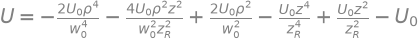

omega_r =


omega_z =


член связи радиального и аксиального движения: -4*U_0*rho**2*z**2/(w_0**2*z_R**2)


In [42]:
# --- символьно: разложение гауссова пинцета до 4-го порядка (sympy)
rho_, z_, U0_, w0_, zR_, eps_ = sp.symbols('rho z U_0 w_0 z_R epsilon', positive=True)
Usym = -U0_/(1 + (z_/zR_)**2)*sp.exp(-2*rho_**2/(w0_**2*(1 + (z_/zR_)**2)))
U4 = sp.expand(sp.series(Usym.subs({rho_: eps_*rho_, z_: eps_*z_}), eps_, 0, 5).removeO().subs(eps_, 1))
display(sp.Eq(sp.Symbol('U'), U4))
m_s = sp.symbols('m', positive=True)
wr_s = sp.sqrt(2*U4.coeff(rho_, 2).subs(z_, 0)/m_s); wz_s = sp.sqrt(2*U4.coeff(z_, 2).subs(rho_, 0)/m_s)
print("omega_r ="); display(sp.simplify(wr_s)); print("omega_z ="); display(sp.simplify(wz_s))
print("член связи радиального и аксиального движения:", U4.coeff(rho_, 2).coeff(z_, 2)*rho_**2*z_**2)

 U0(мК)   nu_r(кГц)  nu_z(кГц)   U0/kB/T(10мкК)
  0.05      17.44      3.31         5.0
  0.10      24.67      4.68        10.0
  0.14      29.19      5.54        14.0
  0.20      34.88      6.62        20.0
  0.30      42.72      8.11        30.0
  0.40      49.33      9.37        40.0


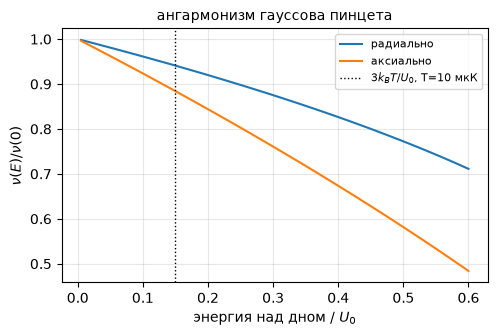

гравитация: m g w0 / kB = 0.182 мкК  ->  пренебрегаем (U0 ~ 100-200 мкК)


In [43]:
U_list = np.array([0.05, 0.1, 0.14, 0.2, 0.3, 0.4])
print(" U0(мК)   nu_r(кГц)  nu_z(кГц)   U0/kB/T(10мкК)")
for U in U_list:
    fr, fz = trap_freqs(U); print(f"{U:6.2f}    {fr/1e3:7.2f}    {fz/1e3:6.2f}      {U*1e-3/10e-6:6.1f}")

# частота 1D-колебаний в радиальном и аксиальном направлениях как функция энергии (численный период)
def period_1d(Efrac, axis, U0_mK=0.2):
    U0 = U0_mK*1e-3*kB
    Uf = (lambda x: -U0*np.exp(-2*x**2/w0**2)) if axis == 'r' else (lambda z: -U0/(1 + (z/zR)**2))
    E = -U0*(1 - Efrac)
    xt = optimize.brentq(lambda x: Uf(x) - E, 0, 20*zR)
    # T/4 = int_0^xt dx / sqrt(2(E-U)/m);  g(x) = sqrt((xt-x)/(E-U)) гладкая, вес (xt-x)^(-1/2) берёт quad (QAWS)
    g = lambda x: np.sqrt(m_Yb/2*(xt - x)/max(E - Uf(x), 1e-300)) if x < xt else np.sqrt(m_Yb/2/abs((Uf(xt) - Uf(xt*(1 - 1e-9)))/(xt*1e-9)))
    T4, _ = integrate.quad(g, 0, xt, weight='alg', wvar=(0, -0.5))
    return 1/(4*T4)
Ef = np.linspace(0.005, 0.6, 40)
fr0, fz0 = trap_freqs(0.2)
plt.figure(figsize=(5.5, 3.3))
plt.plot(Ef, [period_1d(x, 'r')/fr0 for x in Ef], label='радиально')
plt.plot(Ef, [period_1d(x, 'z')/fz0 for x in Ef], label='аксиально')
plt.axvline(3*10e-6/0.2e-3, color='k', ls=':', lw=1, label=r'$3k_BT/U_0$, T=10 мкК')
plt.xlabel(r'энергия над дном / $U_0$'); plt.ylabel(r'$\nu(E)/\nu(0)$'); plt.legend(); plt.title('ангармонизм гауссова пинцета')
plt.show()
print("гравитация: m g w0 / kB =", round(m_Yb*9.81*w0/kB*1e6, 3), "мкК  ->  пренебрегаем (U0 ~ 100-200 мкК)")

### 7.2 Дифференциальный световой сдвиг ³P₁ на 759 нм: $\gamma(\theta_B)$

**Зачем.** В МК входит $\gamma$, определённое через $U_e=(1+\gamma)U_g$. В статье $\gamma$ задаётся «руками», а на Fig. 5(a) показаны значения при $\theta_B=16.5^\circ$ и $0^\circ$ без чисел. Мы считаем $\gamma$ из атомной структуры.

**Поляризуемость.** Для состояния $|i\rangle$ в поле $\mathbf E=\mathrm{Re}(\boldsymbol\varepsilon E_le^{-i\omega t})$ (вещественная $\boldsymbol\varepsilon$) сдвиг равен $\delta E=-\tfrac14E_l^2\,\hat\alpha$, где
$$\hat\alpha_{mm'}=\sum_k\langle m|\boldsymbol\varepsilon\cdot\hat{\mathbf d}|k\rangle\langle k|\boldsymbol\varepsilon\cdot\hat{\mathbf d}|m'\rangle\Big[\frac1{\hbar(\omega_{ki}-\omega)}+\frac1{\hbar(\omega_{ki}+\omega)}\Big]$$
(второй порядок теории возмущений; матрица по вырожденному мультиплету). Это сумма скалярной и тензорной частей. Для $J=1$ тензорная часть даёт зависимость от угла между $\boldsymbol\varepsilon$ и $\mathbf B$.

**Входные данные.** Энергии из NIST. Приведённые матричные элементы $|\langle{}^3P_1\|D\|k\rangle|$ (CI+MBPT) взяты из Porsev et al., arXiv:1712.08888, табл. 3. Матричные элементы к ³P₀, ³P₂ (нужны в §12) получаем из них **через LS-связь**: диполь действует только на $L$, а $J$-зависимость задаётся пересвязкой. Численно строим $|(LS)JM\rangle$ в несвязанном базисе $|Lm_L\rangle|Sm_S\rangle$ через КГ и сверяем с аналитической формулой через 6j-символ (sympy). Знаки при этом определены однозначно: произведение $\langle f\|d\|k\rangle\langle k\|d\|i\rangle$ содержит квадрат радиального интеграла.

**Проверки модели.**
1. LS-отношение $\langle{}^3P_1\|D\|{}^3D_1\rangle/\langle{}^3P_1\|D\|{}^3D_2\rangle=0.577$ против 2.57/4.45 = 0.578 из расчёта.
2. $A({}^3P_1\to{}^1S_0)=\frac{\omega^3|\langle\|D\|\rangle|^2}{3\pi\epsilon_0\hbar c^3(2J'+1)}$ при 0.54 a.u. должно дать 182 кГц.
3. Статическая тензорная поляризуемость ³P₁: литература 24.1 a.u.

**Сверхтонкая структура и поле.** $|{}^3P_1,F{=}\tfrac32,m\rangle$ — суперпозиция $|J{=}1,m_J\rangle|I{=}\tfrac12,m_I\rangle$ с КГ-весами, ядерный спин — наблюдатель. Строим в qutip (`jmat`, `tensor`) 6×6 гамильтониан $A_{\rm hf}\,\mathbf I\cdot\mathbf J+g_J\mu_BBJ_z-\tfrac14E_l^2\hat\alpha_J$ и точно диагонализуем (`eigenstates`). Так автоматически учтены эффекты второго порядка (смешивание $m_F$ тензорным сдвигом при конечном зеемане), о которых статья говорит «no perfect imaging-magic angle due to higher order contributions».

**Калибровка.** Сумма по конечному числу состояний не включает остов и высоколежащие уровни. Это недостающая скалярная добавка $\delta\alpha$; её подбираем по единственному числу из статьи — первому магическому углу $15.5^\circ$ (App. A). Поляризуемость основного состояния на магической длине волны: $\alpha_g=186$ a.u. (литература).

In [44]:
# ----- атомные данные (NIST энергии, Porsev et al. 1712.08888 Table 3: |<3P1||D||k>|, a.u.)
E3P = {0: 17288.439, 1: 17992.007, 2: 19710.388}         # 6s6p 3P_J, см^-1
INTER = [('6s2 1S0', None, 0, 0.0, 0.58),
         ('5d6s 3D1', 2, 1, 24489.102, 2.57), ('5d6s 3D2', 2, 2, 24751.948, 4.45),
         ('6s7s 3S1', 0, 1, 32694.692, 3.47),
         ('6s6d 3D1', 2, 1, 39808.72, 1.57), ('6s6d 3D2', 2, 2, 39838.04, 2.72),
         ('6s8s 3S1', 0, 1, 41615.04, 1.00),
         ('6p2 3P0', 1, 0, 42436.91, 2.59), ('6p2 3P1', 1, 1, 43805.42, 0.18), ('6p2 3P2', 1, 2, 44760.37, 2.92),
         ('6s7d 3D1', 2, 1, 44311.38, 2.47), ('6s7d 3D2', 2, 2, 44313.05, 1.67)]
alpha_g_au = 186.0          # alpha(1S0) = alpha(3P0) на 759.35 нм, a.u.
A_hf_3P1 = 3957.2e6         # Гц, A(3P1) 171Yb
cm2au = 1/219474.6313705    # см^-1 -> hartree

def ls_vec(L, S, J, mJ):
    return np.array([cg(L, mL, S, mS, J, mJ) for mL in mlist(L) for mS in mlist(S)])
def d_uncoupled(L, Lp, S, q):
    '''<L mL, S mS| d_q |L' mL', S mS'> при <L||d||L'>=1 (3j-конвенция)'''
    bL = [(mL, mS) for mL in mlist(L) for mS in mlist(S)]; bR = [(mL, mS) for mL in mlist(Lp) for mS in mlist(S)]
    M = np.zeros((len(bL), len(bR)))
    for i, (mL, mS) in enumerate(bL):
        for j, (mLp, mSp) in enumerate(bR):
            if abs(mS - mSp) < 1e-9: M[i, j] = (-1)**int(round(L - mL))*threej(L, -mL, 1, q, Lp, mLp)
    return M
def dJ_LS(L, J, Lp, Jp, S=1):
    A = np.array([ls_vec(L, S, J, m) for m in mlist(J)]); B = np.array([ls_vec(Lp, S, Jp, m) for m in mlist(Jp)])
    return {q: A @ d_uncoupled(L, Lp, S, q) @ B.T for q in (-1, 0, 1)}
def reduced_eff(L, J, Lp, Jp):
    d = dJ_LS(L, J, Lp, Jp)
    for q in (-1, 0, 1):
        for i, mm in enumerate(mlist(J)):
            for j, mp in enumerate(mlist(Jp)):
                t = threej(J, -mm, 1, q, Jp, mp)
                if abs(t) > 1e-6: return d[q][i, j]/((-1)**int(round(J - mm))*t)
    return 0.0
def ME_3P(J, k):
    '''матрицы <3P_J m|d_q|k m_k> (a.u.), нормированные на |<3P1||D||k>| из таблицы'''
    name, L, Jk, Ek, d1 = k
    if L is None:                                  # 1S0: только для J=1 (интеркомбинационная линия)
        if J != 1: return None
        return {q: np.array([[(-1)**int(round(1 - mm))*threej(1, -mm, 1, q, 0, 0)*d1] for mm in mlist(1)]) for q in (-1, 0, 1)}
    r1 = reduced_eff(1, 1, L, Jk); rJ = reduced_eff(1, J, L, Jk)
    if abs(r1) < 1e-12 or abs(rJ) < 1e-12: return None
    d = dJ_LS(1, J, L, Jk); rad = d1/abs(r1)
    return {q: d[q]*rad for q in d}
def cart(dq):
    return {'x': (dq[-1] - dq[1])/np.sqrt(2), 'y': 1j*(dq[-1] + dq[1])/np.sqrt(2), 'z': dq[0]}

print("LS-проверка 5d6s: <3P1||3D1>/<3P1||3D2>: LS =", round(reduced_eff(1, 1, 2, 1)/reduced_eff(1, 1, 2, 2), 4), " таблица =", round(2.57/4.45, 4))
print("LS-ветвление 6s7s 3S1 -> 3P0:3P1:3P2 (|<||>|^2) =",
      np.round([reduced_eff(1, J, 0, 1)**2/reduced_eff(1, 1, 0, 1)**2 for J in (0, 1, 2)], 3), " (ожидаем 1/3 : 1 : 5/3)")
# сверка численной LS-пересвязки с аналитической формулой через 6j-символ (sympy):
# <(LS)J||d||(L'S)J'> = (-1)^(L+S+J'+1) sqrt((2J+1)(2J'+1)) {L J S; J' L' 1} <L||d||L'>
print(" J  L' J'   численно   через 6j (sympy)")
for (J, Lp, Jp) in [(0, 0, 1), (1, 0, 1), (2, 0, 1), (0, 2, 1), (1, 2, 1), (1, 2, 2), (2, 2, 1), (2, 2, 2), (1, 1, 2), (2, 1, 2)]:
    an = (-1)**(1 + 1 + Jp + 1)*sp.sqrt((2*J + 1)*(2*Jp + 1))*wigner_6j(1, J, 1, Jp, Lp, 1)
    print(f" {J}  {Lp}  {Jp}   {reduced_eff(1, J, Lp, Jp):+.5f}   {float(an):+.5f}  = {sp.nsimplify(an)}")
w31 = 2*np.pi*c*100*E3P[1]
print(f"A(3P1->1S0)/2pi при 0.54 a.u. = {w31**3*(0.54*ea0)**2/(3*np.pi*eps0*hbar*c**3*3)/2/np.pi/1e3:.1f} кГц  (Gamma/2pi = 182 кГц)")

def alpha_op(J, wl_nm):
    '''оператор поляризуемости (a.u.) мультиплета 3P_J как функция eps'''
    w = 1e7/wl_nm*cm2au; blocks = []
    for k in INTER:
        dq = ME_3P(J, k)
        if dq is None: continue
        blocks.append((cart(dq), (k[3] - E3P[J])*cm2au))
    def op(eps):
        A = 0
        for dc, wk in blocks:
            D = eps[0]*dc['x'] + eps[1]*dc['y'] + eps[2]*dc['z']
            A = A + (D @ D.conj().T)*(1/(wk - w) + 1/(wk + w))
        return A.real
    return op
for wl in (1e9, 759.356):
    op = alpha_op(1, wl); az = np.diag(op([0, 0, 1])); aS = np.trace(op([0, 0, 1]))/3
    print(f"lambda={'static' if wl > 1e8 else wl}: 3P1 alpha_S = {aS:6.1f}, alpha_T = alpha_zz(m=1)-alpha_S = {az[0]-aS:6.1f} a.u."
          + ("   (лит.: 328(19), 24.1(1.5))" if wl > 1e8 else ""))
print("3P0 на 759 нм (сумма по состояниям):", round(np.trace(alpha_op(0, 759.356)([0, 0, 1]))/1, 1),
      "a.u. против 186 -> недостающая (остов+высокие уровни) часть ~ 25-30 a.u.")

LS-проверка 5d6s: <3P1||3D1>/<3P1||3D2>: LS = 0.5774  таблица = 0.5775
LS-ветвление 6s7s 3S1 -> 3P0:3P1:3P2 (|<||>|^2) = [0.333 1.    1.667]  (ожидаем 1/3 : 1 : 5/3)
 J  L' J'   численно   через 6j (sympy)
 0  0  1   +0.57735   +0.57735  = sqrt(3)/3
 1  0  1   -1.00000   -1.00000  = -1
 2  0  1   +1.29099   +1.29099  = sqrt(15)/3
 0  2  1   +0.57735   +0.57735  = sqrt(3)/3
 1  2  1   +0.50000   +0.50000  = 1/2
 1  2  2   +0.86603   +0.86603  = sqrt(3)/2
 2  2  1   +0.12910   +0.12910  = sqrt(15)/30
 2  2  2   +0.50000   +0.50000  = 1/2
 1  1  2   -0.64550   -0.64550  = -sqrt(15)/6
 2  1  2   +1.11803   +1.11803  = sqrt(5)/2
A(3P1->1S0)/2pi при 0.54 a.u. = 182.6 кГц  (Gamma/2pi = 182 кГц)
lambda=static: 3P1 alpha_S =  301.0, alpha_T = alpha_zz(m=1)-alpha_S =   23.8 a.u.   (лит.: 328(19), 24.1(1.5))
lambda=759.356: 3P1 alpha_S =  232.0, alpha_T = alpha_zz(m=1)-alpha_S =   89.3 a.u.
3P0 на 759 нм (сумма по состояниям): 158.6 a.u. против 186 -> недостающая (остов+высокие уровни) часть ~ 25

калибровка: delta_alpha = 33.2 a.u. -> первый магический угол 15.5° (App. A)
theta_B = 16.5°, U0=0.2 мК, 15 Гс: gamma(mF=+1/2, -1/2) = [ 0.0185 -0.0083]
theta_B =  0°  : gamma = [-0.0514 -0.0582]
расщепление gamma(+1/2)-gamma(-1/2) из-за 2-го порядка (0.2 мК, 15 Гс): до 0.0633  (~ 264 кГц)


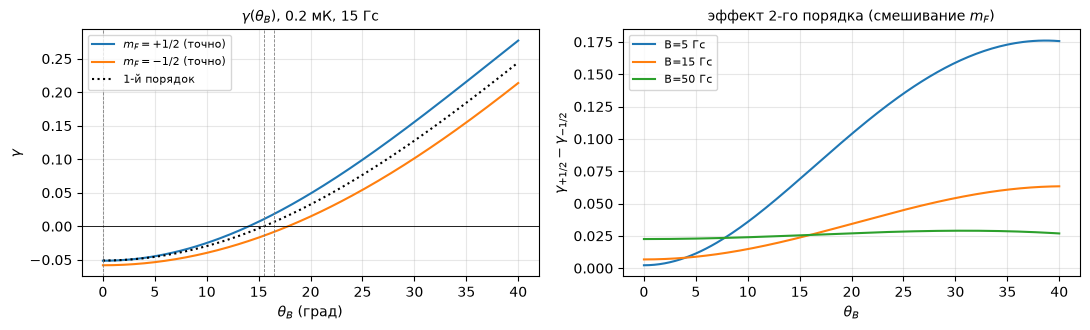

для МК: gamma_clock-magic(16.5°) = 0.0051


In [45]:
_alpha1 = alpha_op(1, 759.356)
JX, JY, JZ = [qt.tensor(o, qt.qeye(2)) for o in (qt.jmat(1, 'x'), qt.jmat(1, 'y'), qt.jmat(1, 'z'))]
IX, IY, IZ = [qt.tensor(qt.qeye(3), o) for o in (qt.jmat(0.5, 'x'), qt.jmat(0.5, 'y'), qt.jmat(0.5, 'z'))]
IdotJ = JX*IX + JY*IY + JZ*IZ
def H_3P1(theta_B, U0_mK, B, dalpha):
    '''qutip: A I.J + g_J mu_B B J_z - E_l^2/4 alpha_J (x) 1_I   (Гц), базис |m_J>|m_I> (m по убыванию)'''
    eps = [np.sin(theta_B), 0, np.cos(theta_B)]
    aJ = _alpha1(eps) + dalpha*np.eye(3)
    El2 = 4*U0_mK*1e-3*kB/(4*np.pi*eps0*a0**3*alpha_g_au)            # E_l^2 из U0 = alpha_g E_l^2/4
    LS = qt.tensor(qt.Qobj(-El2/4*(4*np.pi*eps0*a0**3)*aJ/h), qt.qeye(2))
    return A_hf_3P1*IdotJ + gJ_3P1*muB_h*B*JZ + LS
def Fvec(F, mF):
    return qt.Qobj(np.array([cg(1, mJ, 0.5, mI, F, mF) for mJ in mlist(1) for mI in mlist(0.5)]).reshape(6, 1),
                   dims=[[3, 2], [1, 1]])
def gamma_3P1(theta_B, U0_mK=0.2, B=B_G, dalpha=0.0):
    '''gamma для |F=3/2, mF=+1/2> и |-1/2>: U_e = (1+gamma) U_g, точная диагонализация (qutip eigenstates)'''
    E0, K0 = H_3P1(theta_B, 0.0, B, dalpha).eigenstates(); E1, K1 = H_3P1(theta_B, U0_mK, B, dalpha).eigenstates()
    U0Hz = U0_mK*1e-3*kB/h; out = []
    for mF in (0.5, -0.5):
        v = Fvec(1.5, mF)
        i0 = np.argmax([abs(k.overlap(v)) for k in K0]); i1 = np.argmax([abs(k.overlap(v)) for k in K1])
        out.append((E1[i1] - E0[i0])/(-U0Hz) - 1)
    return np.array(out)
def magic_angle_1st(dal):        # первый порядок: малое U0 -> нет смешивания m_F
    return np.degrees(optimize.brentq(lambda t: gamma_3P1(t, 1e-5, B_G, dal)[0], 1e-3, np.pi/2 - 1e-3))
DALPHA = optimize.brentq(lambda d: magic_angle_1st(d) - 15.5, 0.0, 40.0)
print(f"калибровка: delta_alpha = {DALPHA:.1f} a.u. -> первый магический угол 15.5° (App. A)")
GAMMA_EXP = gamma_3P1(np.radians(16.5), 0.2, B_G, DALPHA)
GAMMA_0 = gamma_3P1(0.0, 0.2, B_G, DALPHA)
print(f"theta_B = 16.5°, U0=0.2 мК, 15 Гс: gamma(mF=+1/2, -1/2) = {GAMMA_EXP.round(4)}")
print(f"theta_B =  0°  : gamma = {GAMMA_0.round(4)}")
thB = np.radians(np.linspace(0, 40, 161))
g_hi = np.array([gamma_3P1(t, 0.2, B_G, DALPHA) for t in thB]); g_1st = np.array([gamma_3P1(t, 1e-5, B_G, DALPHA) for t in thB])
diff = g_hi[:, 0] - g_hi[:, 1]
print(f"расщепление gamma(+1/2)-gamma(-1/2) из-за 2-го порядка (0.2 мК, 15 Гс): до {np.max(abs(diff)):.4f}  "
      f"(~ {np.max(abs(diff))*0.2e-3*kB/h/1e3:.0f} кГц)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(np.degrees(thB), g_hi[:, 0], label=r'$m_F=+1/2$ (точно)'); ax[0].plot(np.degrees(thB), g_hi[:, 1], label=r'$m_F=-1/2$ (точно)')
ax[0].plot(np.degrees(thB), g_1st[:, 0], 'k:', label='1-й порядок')
for a_ in (0, 15.5, 16.5): ax[0].axvline(a_, color='gray', lw=.6, ls='--')
ax[0].axhline(0, color='k', lw=.6); ax[0].set_xlabel(r'$\theta_B$ (град)'); ax[0].set_ylabel(r'$\gamma$'); ax[0].legend(); ax[0].set_title(r'$\gamma(\theta_B)$, 0.2 мК, 15 Гс')
for Bv in (5, 15, 50):
    gg = np.array([gamma_3P1(t, 0.2, Bv, DALPHA) for t in thB]); ax[1].plot(np.degrees(thB), gg[:, 0] - gg[:, 1], label=f'B={Bv} Гс')
ax[1].set_xlabel(r'$\theta_B$'); ax[1].set_ylabel(r'$\gamma_{+1/2}-\gamma_{-1/2}$'); ax[1].legend(); ax[1].set_title('эффект 2-го порядка (смешивание $m_F$)')
plt.tight_layout(); plt.show()
GAMMA_CLOCK = float(GAMMA_EXP.mean())     # одно число для МК (среднее по m_F)
print("для МК: gamma_clock-magic(16.5°) =", round(GAMMA_CLOCK, 4))

**Итог 7.2.**
* Модель воспроизводит статическую тензорную поляризуемость ³P₁ (≈24 a.u.) и $\Gamma$. LS-соотношения матричных элементов выполняются с точностью $10^{-3}$.
* После калибровки одной скалярной добавки по углу 15.5° получаем: при $\theta_B=16.5^\circ$ $\gamma\approx+0.005$ в среднем по $m_F$, то есть возбуждённое состояние немного глубже, сдвиг красный («smaller and red-detuned», Sec. IV). При $\theta_B=0$ $\gamma\approx-0.055$; это сдвиг линии на дне ловушки 0.2 мК на $|\gamma|U_0/\hbar\approx1.2\Gamma$ в синюю сторону.
* $\gamma_{+1/2}\neq\gamma_{-1/2}$: при 16.5° получаем +0.019 и −0.008. Расщепление дают два эффекта высшего порядка, и оба есть в точной диагонализации:
  (a) тензорный сдвиг смешивает $m_F$ внутри $F=3/2$ (связи $\Delta m=\pm1,\pm2$ при $\theta_B\neq0$). Поправка второго порядка $\sim|V_T|^2/(g_F\mu_BB)$ асимметрична для $m_F=\pm\tfrac12$ и падает как $1/B$; поэтому кривые при 5 и 15 Гс растут с углом;
  (b) зееман смешивает $F=3/2$ и $F=1/2$ с тем же $m_F$ (амплитуда $\sim g_J\mu_BB/\tfrac32A_{\rm hf}$). Перекрёстный член со световым сдвигом нечётен по $m_F$ и растёт как $B$; он виден уже при $\theta_B=0$ (≈0.007 при 15 Гс, ≈0.023 при 50 Гс).
  Поэтому единого «imaging-magic» угла для обоих подуровней нет, что и утверждает статья («higher order contributions»).
* Ограничение: в МК, как и в статье, используется одно $\gamma$ для обоих MS-секторов.

---
## §8. Монте-Карло лазерного охлаждения в пинцете (App. D)

**Модель статьи (D1)–(D4).** Движение классическое, шаг $\delta t=1$ мкс:
1. Начальные $\mathbf r,\mathbf v$ — Максвелл–Больцман при $T_0$ (в гармоническом приближении).
2. Локальная отстройка $\Delta'(\mathbf r)$ (см. ниже про знак). Скорость рассеяния пары $i$: $R_i=\frac\Gamma2\frac{s_i}{1+\sum s+(2\Delta'/\Gamma)^2}$ (D2).
3. $\mathbf v\to\mathbf v+\big(-\nabla U'-\alpha\mathbf v\big)\delta t/m+\hat e_p\sqrt{2D_p\delta t}/m$. Здесь $U'=(1-\rho_{ee})U+\rho_{ee}(1+\gamma)U$, $\rho_{ee}=\sum R_i/\Gamma$ — средний по внутреннему состоянию потенциал; $\alpha$ из (D3); $D_p=\hbar^2k^2\sum R_i$ (D4); $\hat e_p$ — случайный орт с распределением дипольного излучения относительно $\mathbf B\parallel y$.
4. $\mathbf r\to\mathbf r+\mathbf v\delta t$. Атом потерян, если $E=\tfrac12mv^2+U(\mathbf r)\ge0$.

**Детали реализации и где мы отходим от буквы статьи.**
* **Знак в $\Delta'$.** Если $U_e=(1+\gamma)U$, то частота перехода в точке $\mathbf r$ равна $\omega_0+\gamma U(\mathbf r)/\hbar$. При $\Delta$, отсчитанном от резонанса на дне ($U=-U_0$), получаем $\Delta'=\Delta-\gamma(U_0+U)/\hbar$. В статье написано $+$. Это согласуется с выражением для $U'$ только если $\Delta=\omega_0-\omega_L$ (знак как в (B1)), но тогда красная отстройка — это $\Delta>0$, а в тексте везде $\Delta<0$. Мы используем физически согласованную пару; знак статьи доступен флагом `paper_sign=True`. Разница — это просто $\gamma\to-\gamma$.
* **Трение.** В (D3) трение скалярное: $\alpha\propto\sum_is_i(\hat k_i\cdot\hat v)^2$, сила направлена вдоль $\mathbf v$. Физически сила вдоль $\hat k_i$: $\mathbf F=-\sum_i\alpha_i(\hat k_i\cdot\mathbf v)\hat k_i$ (тензорная форма). Обе формы дают одинаковую мощность охлаждения $\mathbf F\cdot\mathbf v$, но скалярная форма «поворачивает» охлаждение на поперечные к $\hat k$ компоненты скорости. По умолчанию используем тензорную форму, скалярная доступна (`friction='scalar'`); сравнение ниже.
* **Направление диффузионного толчка.** Как в статье, весь толчок идёт по диаграмме испускания: смесь π (2/3, $\propto\sin^2\vartheta$) и σ (1/3, $\propto(1+\cos^2\vartheta)/2$) относительно $y$. Это доли распада $|e_{\pm1/2}\rangle$ из §1.
* **Модель дискретных фотонов** (`model='photon'`) — независимая проверка. Для каждого пучка $\pm\hat k_i$ своя доплеровски сдвинутая скорость $\frac\Gamma2\frac{s_i/2}{1+S+[2(\Delta'\mp k\hat k_i\cdot\mathbf v)/\Gamma]^2}$. Число событий за шаг — пуассоновское. Каждое событие даёт толчок поглощения $\pm\hbar k\hat k_i$ и испускания $\hbar k\hat u$. Трение и диффузия получаются сами, без линеаризации.
* **Чередование осей** с частотой $f_{\rm alt}$: период $1/f_{\rm alt}$, каждая ось активна половину периода с полным $s$. При одновременной работе каждая ось получает $s/n_{\rm axes}$.
* Потери и фотоны считаются только после $t_{\rm skip}$, чтобы убрать начальный переходный процесс. Вектор $\hat e_p$ берётся из таблицы $2^{14}$ направлений, заранее разыгранных по дипольной диаграмме (таблица целиком лежит в кэше).
* **Реализация:** ядро `_mc_kernel` скомпилировано numba (`@njit`), цикл по атомам и шагам явный, ГСЧ numba засеян. Обёртка `mc_run` готовит начальные условия и считает release–recapture. Параметрические сканы распараллеливаются по процессам (`pmap`).

In [46]:
import multiprocessing as _mp
PARALLEL = sys.platform.startswith('linux')
NPROC = max(1, min(4, os.cpu_count() or 1))
def pmap(f, args):
    if PARALLEL and NPROC > 1 and len(args) > 1:
        with _mp.get_context('fork').Pool(NPROC) as p:
            return p.map(f, args, chunksize=1)
    return [f(a) for a in args]

def _dipole_exact(n, rng, frac_pi=2/3):
    out = np.empty((n, 3)); filled = 0
    while filled < n:
        N = 2*(n - filled) + 16
        v = rng.normal(size=(N, 3)); v /= np.linalg.norm(v, axis=1)[:, None]
        c2 = v[:, 1]**2                                          # cos^2 угла к y (ось квантования)
        p = np.where(rng.random(N) < frac_pi, 1 - c2, (1 + c2)/2)
        acc = v[rng.random(N) < p]; t = min(len(acc), n - filled)
        out[filled:filled + t] = acc[:t]; filled += t
    return out
DIP = np.ascontiguousarray(_dipole_exact(1 << 14, np.random.default_rng(2026)))   # 16384 направления: таблица в кэше L2

class Trap:
    def __init__(self, U0_mK, w=w0, aniso=0.0, free=False):
        self.free = free; self.U0_mK = U0_mK; self.U0 = U0_mK*1e-3*kB
        self.wx, self.wy = w*(1 + aniso/2), w*(1 - aniso/2)
        self.zx, self.zy = np.pi*self.wx**2/lam_tr, np.pi*self.wy**2/lam_tr
    def omegas(self):
        return np.sqrt(4*self.U0/(m_Yb*self.wx**2)), np.sqrt(4*self.U0/(m_Yb*self.wy**2)), \
               np.sqrt(self.U0/m_Yb*(1/self.zx**2 + 1/self.zy**2))
    def U_grad(self, r):
        if self.free: return np.full(len(r), -1.0), np.zeros_like(r)
        x, y, z = r[:, 0], r[:, 1], r[:, 2]
        ax = 1 + (z/self.zx)**2; ay = 1 + (z/self.zy)**2
        ex = 2*x*x/(self.wx**2*ax); ey = 2*y*y/(self.wy**2*ay)
        U = -self.U0/np.sqrt(ax*ay)*np.exp(-ex - ey)
        axp = 2*z/self.zx**2; ayp = 2*z/self.zy**2
        g = np.empty_like(r)
        g[:, 0] = U*(-4*x/(self.wx**2*ax)); g[:, 1] = U*(-4*y/(self.wy**2*ay))
        g[:, 2] = U*(-0.5*(axp/ax + ayp/ay) + ex*axp/ax + ey*ayp/ay)
        return U, g

def kdir(theta_deg, plane):
    t = np.radians(theta_deg)
    return {'xz': np.array([np.sin(t), 0, np.cos(t)]), 'yz': np.array([0, np.sin(t), np.cos(t)])}[plane]
AX3 = [np.array([1., 0, 0]), np.array([0, 1., 0]), np.array([0, 0, 1.])]
BEAMS_EXP = [kdir(52, 'xz'), kdir(73, 'yz')]           # геометрия эксперимента

@njit(cache=False, fastmath=True)
def _mc_kernel(r, v, K, s_mode, s_tot, f_alt, Dl, gamma, sg, U0, wx, wy, zx, zy, free,
               nsteps, nskip, dt, photon_model, tensor, seed, rec_every, DIP,
               m, hbar, k, Gam):
    np.random.seed(seed)
    N = r.shape[0]; nbm = K.shape[0]; ND = DIP.shape[0]
    alive = np.ones(N, np.bool_)
    nrec = nsteps//rec_every + 1
    rec_t = np.zeros(nrec); rec_T = np.zeros((nrec, 3)); rec_N = np.zeros(nrec, np.int64); rec_ph = np.zeros(nrec)
    nph = 0.0; nlost = 0; nlost_all = 0; nalive = N
    s_i = np.zeros(nbm); hk_m = hbar*k/m
    sqdt = np.sqrt(dt)
    irec = 0
    for it in range(nsteps):
        t = it*dt
        if s_mode == 0:
            for b in range(nbm): s_i[b] = s_tot/nbm
        else:
            act = int(2.0*f_alt*t) % nbm
            for b in range(nbm): s_i[b] = s_tot if b == act else 0.0
        S = 0.0
        for b in range(nbm): S += s_i[b]
        sum_v2 = np.zeros(3)
        for i in range(N):
            if not alive[i]: continue
            x = r[i, 0]; y = r[i, 1]; z = r[i, 2]
            if free:
                U = -1.0; gx = 0.0; gy = 0.0; gz = 0.0
            else:
                ax = 1.0 + (z/zx)**2; ay = 1.0 + (z/zy)**2
                ex = 2.0*x*x/(wx*wx*ax); ey = 2.0*y*y/(wy*wy*ay)
                U = -U0/np.sqrt(ax*ay)*np.exp(-ex - ey)
                axp = 2.0*z/(zx*zx); ayp = 2.0*z/(zy*zy)
                gx = U*(-4.0*x/(wx*wx*ax)); gy = U*(-4.0*y/(wy*wy*ay))
                gz = U*(-0.5*(axp/ax + ayp/ay) + ex*axp/ax + ey*ayp/ay)
                E = 0.5*m*(v[i, 0]**2 + v[i, 1]**2 + v[i, 2]**2) + U
                if E >= 0.0:
                    alive[i] = False; nalive -= 1; nlost_all += 1
                    if it >= nskip: nlost += 1
                    continue
            Dp = Dl + sg*gamma*(U0 + U)/hbar if (gamma != 0.0 and not free) else Dl
            d = 2.0*Dp/Gam; den = 1.0 + S + d*d
            Rtot = Gam/2.0*S/den
            fac = -(1.0 + gamma*Rtot/Gam)/m*dt
            dvx = fac*gx; dvy = fac*gy; dvz = fac*gz
            if not photon_model:
                if tensor:
                    for b in range(nbm):
                        kv = K[b, 0]*v[i, 0] + K[b, 1]*v[i, 1] + K[b, 2]*v[i, 2]
                        coef = 4.0*hbar*k*k*(s_i[b]/2.0)*d/(den*den)*kv*dt/m
                        dvx += coef*K[b, 0]; dvy += coef*K[b, 1]; dvz += coef*K[b, 2]
                else:
                    vn2 = v[i, 0]**2 + v[i, 1]**2 + v[i, 2]**2 + 1e-300
                    acc = 0.0
                    for b in range(nbm):
                        kv = K[b, 0]*v[i, 0] + K[b, 1]*v[i, 1] + K[b, 2]*v[i, 2]
                        acc += 4.0*hbar*k*k*(s_i[b]/2.0)*d/(den*den)*kv*kv/vn2
                    dvx += acc*v[i, 0]*dt/m; dvy += acc*v[i, 1]*dt/m; dvz += acc*v[i, 2]*dt/m
                j = np.random.randint(0, ND)
                amp = np.sqrt(2.0*hbar*hbar*k*k*Rtot*dt)/m
                dvx += DIP[j, 0]*amp; dvy += DIP[j, 1]*amp; dvz += DIP[j, 2]*amp
                if it >= nskip: nph += Rtot*dt
            else:
                for b in range(nbm):
                    kv = K[b, 0]*v[i, 0] + K[b, 1]*v[i, 1] + K[b, 2]*v[i, 2]
                    for sgn in (1.0, -1.0):
                        dd = 2.0*(Dp - sgn*k*kv)/Gam
                        lam = Gam/2.0*(s_i[b]/2.0)/(1.0 + S + dd*dd)*dt
                        n = np.random.poisson(lam) if lam > 0 else 0
                        for _ in range(n):
                            dvx += hk_m*sgn*K[b, 0]; dvy += hk_m*sgn*K[b, 1]; dvz += hk_m*sgn*K[b, 2]
                            j = np.random.randint(0, ND)
                            dvx += hk_m*DIP[j, 0]; dvy += hk_m*DIP[j, 1]; dvz += hk_m*DIP[j, 2]
                        if it >= nskip: nph += n
            v[i, 0] += dvx; v[i, 1] += dvy; v[i, 2] += dvz
            r[i, 0] += v[i, 0]*dt; r[i, 1] += v[i, 1]*dt; r[i, 2] += v[i, 2]*dt
            if it % rec_every == 0:
                sum_v2[0] += v[i, 0]**2; sum_v2[1] += v[i, 1]**2; sum_v2[2] += v[i, 2]**2
        if it % rec_every == 0:
            rec_t[irec] = t; rec_N[irec] = nalive; rec_ph[irec] = nph
            for a in range(3): rec_T[irec, a] = m*sum_v2[a]/max(nalive, 1)
            irec += 1
        if nalive == 0: break
    return rec_t[:irec], rec_T[:irec], rec_N[:irec], rec_ph[:irec], nph, nlost, nlost_all, alive

def mc_run(U0_mK=0.2, beams=BEAMS_EXP, s=2.0, Delta=-1.0, gamma=0.0, f_alt=None, T_run=10e-3, N=500,
           T0=15e-6, dt=1e-6, seed=0, model='paper', friction='tensor', aniso=0.0, rec_every=20,
           t_skip=0.0, t_release=None, free=False, paper_sign=False, keep_state=False):
    '''Обёртка над numba-ядром. Delta в единицах Gamma (от резонанса на дне). Возвращает dict.'''
    rng = np.random.default_rng(seed)
    trap = Trap(U0_mK, aniso=aniso, free=free); K = np.ascontiguousarray(np.array(beams, float))
    r = np.zeros((N, 3)) if free else rng.normal(size=(N, 3))*np.sqrt(kB*T0/m_Yb)/np.array(trap.omegas())
    v = rng.normal(size=(N, 3))*np.sqrt(kB*T0/m_Yb)
    nsteps = int(round(T_run/dt)); nskip = int(round(t_skip/dt))
    s_mode = 0 if (f_alt is None or len(K) == 1) else 1
    t, T, Nal, ph, nph, nlost, nla, alive = _mc_kernel(
        r, v, K, s_mode, float(s), float(f_alt or 0.0), Delta*Gam, float(gamma), 1.0 if paper_sign else -1.0,
        trap.U0, trap.wx, trap.wy, trap.zx, trap.zy, free, nsteps, nskip, dt, model == 'photon',
        friction == 'tensor', int(seed), int(rec_every), DIP, m_Yb, hbar, k_L, Gam)
    out = dict(t=t, T=T/kB*1e6, Nalive=Nal, ph=ph, nph=nph, nlost=int(nlost), nlost_all=int(nla), N=N,
               ret=alive.sum()/N, U0_mK=U0_mK)
    r, v = r[alive], v[alive]
    if t_release is not None and not free:            # release & recapture (+ гравитация вдоль -y)
        g = np.array([0, -9.81, 0]); rr = r + v*t_release + 0.5*g*t_release**2; vv = v + g*t_release
        Ur, _ = trap.U_grad(rr)
        out['recap'] = np.sum(0.5*m_Yb*np.einsum('ij,ij->i', vv, vv) + Ur < 0)/N
    if keep_state: out['r'], out['v'] = r, v
    return out

def mc_task(p): return mc_run(**p)
def Tmean(res, frac=0.5):
    '''средняя кинетическая температура (мкК) за последнюю долю frac времени: (Tx+Ty+Tz)/3 и по осям'''
    i = int(len(res['t'])*(1 - frac)); Tax = np.nanmean(res['T'][i:], 0); return Tax.mean(), Tax
t0 = time.time(); _ = mc_run(T_run=1e-5, N=4); print(f"JIT-компиляция numba: {time.time()-t0:.1f} с")
t0 = time.time(); _ = mc_run(T_run=5e-3, N=2000); dtm = time.time() - t0
print(f"скорость: {dtm/5000/2000*1e9:.0f} нс на атом-шаг (numba, 1 ядро)")

JIT-компиляция numba: 3.7 с
скорость: 37 нс на атом-шаг (numba, 1 ядро)


### 8.1 Валидация МК
1. **Свободное пространство, три ортогональные пары**, полное насыщение $S$. Теория §6: $k_BT=\frac{\hbar\Gamma}4\frac{1+S+\delta^2}{|\delta|}$ для каждой оси. Здесь $s$ одной пары равно $S/3$, а в нагрев оси $x$ входят поглощение из пары $x$ и проекция испускания. Для изотропного испускания это даёт ту же формулу; дипольная диаграмма перераспределяет нагрев между осями, но средняя по трём осям $T$ не меняется.
2. **Модель дискретных фотонов** против линеаризованной.
3. **Трение в пинцете:** тензорное против скалярного (D3).

(время 30 с)
 delta=2D/G   теория   МК(D1-D4)   МК(фотоны)   [мкК]
   -0.5        9.83      9.87       17.58
   -1.0        6.55      6.58        7.47
   -2.0        6.55      6.59        6.56
   -3.0        8.01      8.12        7.91


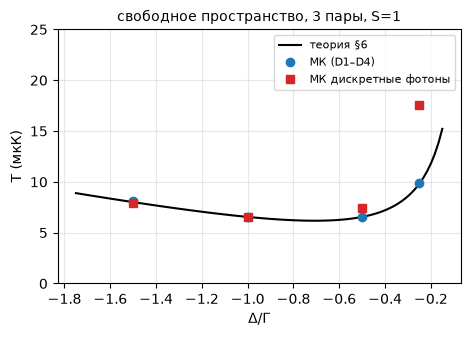

пинцет 0.2 мК, 52°/73°, s=2, D=-G:  T (Tx,Ty,Tz) тензорное = [ 9.38  4.53 12.2 ]  скалярное = [ 8.95  5.7  10.08]


In [47]:
deltas = [-0.5, -1.0, -2.0, -3.0]; S_ = 1.0
tasks = []
for dl in deltas:
    for mdl in ('paper', 'photon'):
        tasks.append(dict(free=True, beams=AX3, s=S_, Delta=dl/2, T_run=12e-3, N=4000*SCALE,
                          T0=15e-6, model=mdl, seed=11, rec_every=20))
t0 = time.time(); res = pmap(mc_task, tasks)
print(f"(время {time.time()-t0:.0f} с)\n delta=2D/G   теория   МК(D1-D4)   МК(фотоны)   [мкК]")
Tp, Tf = [], []
for i, dl in enumerate(deltas):
    a = Tmean(res[2*i], .6)[0]; b = Tmean(res[2*i + 1], .6)[0]; Tp.append(a); Tf.append(b)
    print(f"  {dl:5.1f}      {T_doppler(dl, S_):6.2f}    {a:6.2f}      {b:6.2f}")
dd = np.linspace(-3.5, -0.3, 100)
plt.figure(figsize=(5.2, 3.3)); plt.plot(np.array(dd)/2, T_doppler(dd, S_), 'k-', label='теория §6')
plt.plot(np.array(deltas)/2, Tp, 'C0o', label='МК (D1–D4)'); plt.plot(np.array(deltas)/2, Tf, 'C3s', label='МК дискретные фотоны')
plt.xlabel(r'$\Delta/\Gamma$'); plt.ylabel('T (мкК)'); plt.ylim(0, 25); plt.legend(); plt.title('свободное пространство, 3 пары, S=1'); plt.show()

# трение: тензорное vs скалярное (D3) в пинцете, геометрия эксперимента, одновременно 2 оси
tasks = [dict(U0_mK=0.2, s=2, Delta=-1.0, friction=fr, T_run=8e-3, N=800*SCALE, seed=5, aniso=0.1) for fr in ('tensor', 'scalar')]
r_t, r_s = pmap(mc_task, tasks)
print("пинцет 0.2 мК, 52°/73°, s=2, D=-G:  T (Tx,Ty,Tz) тензорное =", np.round(Tmean(r_t)[1], 2), " скалярное =", np.round(Tmean(r_s)[1], 2))

**Вывод 8.1.**
* Модель (D1)–(D4) воспроизводит доплеровскую формулу в свободном пространстве. Значит, нормировка трения (со $s_i/2$) и диффузии согласована.
* Модель дискретных фотонов совпадает при $|\Delta|\gtrsim\Gamma$ и даёт **более высокую** $T$ при малых $|\Delta|$ (на 14% при $\Delta=-\Gamma/2$, на ≈80% при $\Delta=-\Gamma/4$). Для узкой линии $kv_{\rm rms}\sim0.2\Gamma$ сравнимо с $|\Delta|$, и сила трения насыщается по скорости, то есть линейная теория завышает охлаждение. Отсюда смещение оптимума к большим $|\Delta|$ даже без $\gamma$. Это один из механизмов, которые могут стоять за «10–20% larger detuning» на Fig. 4(a).
* Тензорное и скалярное трение в пинцете дают близкие средние $T$: перемешивание и так перераспределяет энергию.

---
## §9. Fig. 3(a): температура в пинцете в зависимости от полярного угла пучка $\theta_k$

**Задача.** Найти равновесную $T$ при охлаждении одной или двумя наклонными ретро-отражёнными парами. $\theta_k$ — угол между $\hat k$ и осью пинцета $z$. Ось 1 лежит в плоскости $xz$, ось 2 — в $yz$.

**Параметры.** Как в подписи Fig. 3(a): $s=2$, $\Delta=-\Gamma$. Глубина в подписи не указана; берём рабочую 0.2 мК. Берём $\gamma=0$: смотрим чистую геометрию охлаждения. Анизотропия перетяжек 10% ($w_x/w_y\approx1.1$).

**Ожидание (§6–7).** При $\theta_k=0$ охлаждается только аксиальная степень свободы, при $90^\circ$ — только одна радиальная. Остальные получают энергию от диффузии и теряют её лишь через ангармоническое перемешивание. Минимум $T$ при промежуточном угле, где проекции $\hat k$ на радиальную и аксиальную оси сравнимы (с поправкой на то, что аксиальное перемешивание медленнее). Анизотропия снимает вырождение $\omega_x=\omega_y$, перемешивание $x\leftrightarrow y$ ухудшается, $T$ растёт. Вторая ось в $yz$ напрямую охлаждает $y$ и это компенсирует.

**Что считаем «температурой».** $T=\tfrac13\sum_i m\langle v_i^2\rangle/k_B$ — средняя кинетическая по выжившим атомам, усреднённая по второй половине прогона. Отдельно смотрим $T_x,T_y,T_z$: неравенство между ними — прямой индикатор недостаточного перемешивания.

время 24 с
1-axis (сим.)    T(θk) = [26.1 26.2 20.8 15.1 11.7 10.9 12.  15.6 19.5 21. ]   мин при 50 °;  удержание за 16 мс: 0.001 - 0.982
1-axis (асим.)   T(θk) = [26.8 25.1 22.5 20.1 18.  17.4 17.4 19.3 21.5 22.4]   мин при 50 °;  удержание за 16 мс: 0.001 - 0.956
2-axis (асим.)   T(θk) = [27.6 25.2 20.9 13.7  9.4  7.8  8.1 11.3 16.8 18.1]   мин при 50 °;  удержание за 16 мс: 0.001 - 1.0


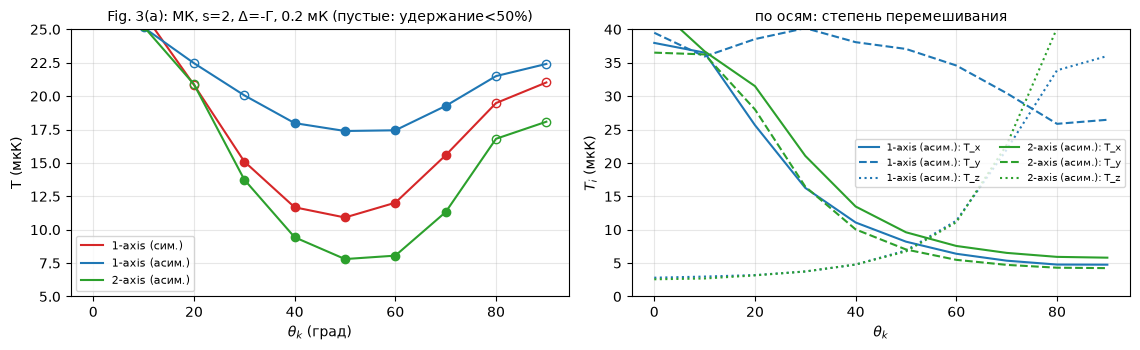

In [48]:
thk = np.arange(0, 91, 10)
cfgs = {'1-axis (сим.)':   dict(aniso=0.0, two=False),
        '1-axis (асим.)':  dict(aniso=0.1, two=False),
        '2-axis (асим.)':  dict(aniso=0.1, two=True)}
tasks, keys = [], []
for name, cf in cfgs.items():
    for th_ in thk:
        b = [kdir(th_, 'xz')] + ([kdir(th_, 'yz')] if cf['two'] else [])
        tasks.append(dict(U0_mK=0.2, beams=b, s=2, Delta=-1.0, gamma=0.0, T_run=20e-3, N=1500*SCALE, T0=15e-6,
                          aniso=cf['aniso'], seed=int(th_) + 7, rec_every=50))
        keys.append((name, th_))
t0 = time.time(); res3a = pmap(mc_task, tasks); print(f"время {time.time()-t0:.0f} с")
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6))
for j, name in enumerate(cfgs):
    rr = [res3a[i] for i, kk in enumerate(keys) if kk[0] == name]
    T_ = np.array([Tmean(r_)[0] for r_ in rr]); ret = np.array([r_['ret'] for r_ in rr])
    ax[0].plot(thk, T_, '-', color=f'C{[3,0,2][j]}', label=name)
    ax[0].plot(thk[ret >= .5], T_[ret >= .5], 'o', color=f'C{[3,0,2][j]}')
    ax[0].plot(thk[ret < .5], T_[ret < .5], 'o', mfc='none', color=f'C{[3,0,2][j]}')
    if name != '1-axis (сим.)':
        Tax = np.array([Tmean(r_)[1] for r_ in rr])
        for a_, ls in zip(range(3), ('-', '--', ':')):
            ax[1].plot(thk, Tax[:, a_], ls, color=f'C{[3,0,2][j]}', label=f'{name}: T_{"xyz"[a_]}')
    print(f"{name:16s} T(θk) =", np.round(T_, 1), "  мин при", thk[np.argmin(T_)], "°;  удержание за 16 мс:", np.round(ret.min(), 3), "-", np.round(ret.max(), 3))
ax[0].set_xlabel(r'$\theta_k$ (град)'); ax[0].set_ylabel('T (мкК)'); ax[0].set_ylim(5, 25); ax[0].legend(); ax[0].set_title('Fig. 3(a): МК, s=2, Δ=-Γ, 0.2 мК (пустые: удержание<50%)')
ax[1].set_xlabel(r'$\theta_k$'); ax[1].set_ylabel(r'$T_i$ (мкК)'); ax[1].set_ylim(0, 40); ax[1].legend(ncol=2, fontsize=7); ax[1].set_title('по осям: степень перемешивания')
plt.tight_layout(); plt.show()

**Интерпретация.**
* Все три качественные особенности Fig. 3(a) воспроизводятся. (1) Минимум при $\theta_k\approx50^\circ$, как в статье. (2) Анизотропия поднимает $T$ при одной оси с ≈11 до ≈17 мкК; на правом графике видно, что виновато неохлаждаемое направление $y$ ($T_y\gg T_x$). (3) Вторая ось в $yz$ напрямую охлаждает $y$, и $T$ опускается ниже уровня одной оси в симметричной ловушке.
* При $\theta_k\lesssim20^\circ$ и $\gtrsim80^\circ$ атомы за 16 мс почти все теряются (пустые маркеры). Температура там относится к немногим выжившим и смещена вниз, то есть реальный нагрев ещё сильнее.
* Почему при $\theta_k\to0$ так плохо: радиальные направления (жёсткие, $\nu_r\approx35$ кГц) охлаждаются только через связь $\rho^2z^2$ с медленным аксиальным движением ($\nu_z\approx7$ кГц). Частоты различаются в 5 раз, обмен энергией нерезонансный и медленный. При $\theta_k\to90^\circ$ симметрично: не охлаждается $z$ ($T_z$ растёт).
* Абсолютные значения зависят от неуказанных деталей модели статьи (глубина, $T_0$, длительность, определение $T$), так что сравнение по величине — порядковое.

---
## §10. Fig. 3(b): release–recapture и частота чередования осей

**Метод release–recapture [41].** После охлаждения ловушку выключают на $t_{\rm rel}=20$ мкс. Атом свободно летит ($\mathbf r\to\mathbf r+\mathbf vt+\tfrac12\mathbf gt^2$) и пойман, если после включения $E=\tfrac12mv^2+U(\mathbf r')<0$. Удержание монотонно падает с ростом $T$. Связь $P_{\rm recap}(T)$ строится по тепловому ансамблю (ниже) и служит «термометром».

**Задача.** Сравнить: одна ось (52° в $xz$ или 73° в $yz$), обе оси одновременно и чередование осей с частотой $f_{\rm alt}=0.1$–100 кГц. Параметры подписи: $s=2$, $\Delta=-\Gamma$, 20 мс охлаждения, $t_{\rm rel}=20$ мкс. Плюс $\gamma=\gamma(16.5^\circ)$ из §7, 0.2 мК, анизотропия 10%.

**Физика чередования.** В эксперименте одновременная работа двух осей **хуже** любой одной оси (зелёная полоса ниже синей и красной). Причина — интерференция пучков: в перекрытии возникают пространственные градиенты поляризации (линейной и круговой). При $\phi\neq0$ появляются тёмные состояния (§3), и охлаждение срывается. МК интерференцию не содержит по построению, поэтому для одновременного режима он даёт «идеальный» результат (фиолетовая линия). Чередование убирает интерференцию: в каждый момент светит одна ось. Если при этом $f_{\rm alt}\gg1/\tau_{\rm eq}$ (время установления $\tau_{\rm eq}\sim1$ мс, вставка Fig. 7(b)), атом «видит» усреднённое охлаждение обеих осей.

время 22 с


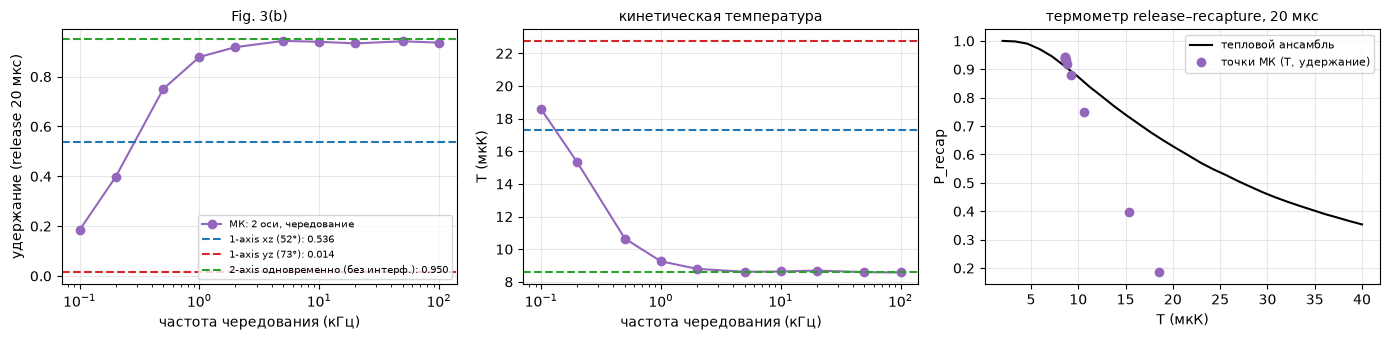

f_alt=   0.1 кГц: удержание 0.184, T=18.6 мкК
f_alt=   0.2 кГц: удержание 0.398, T=15.3 мкК
f_alt=   0.5 кГц: удержание 0.751, T=10.7 мкК
f_alt=   1.0 кГц: удержание 0.879, T=9.3 мкК
f_alt=   2.0 кГц: удержание 0.918, T=8.8 мкК
f_alt=   5.0 кГц: удержание 0.944, T=8.6 мкК
f_alt=  10.0 кГц: удержание 0.940, T=8.6 мкК
f_alt=  20.0 кГц: удержание 0.933, T=8.7 мкК
f_alt=  50.0 кГц: удержание 0.942, T=8.6 мкК
f_alt= 100.0 кГц: удержание 0.936, T=8.6 мкК


In [49]:
f_list = [0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100]          # кГц
common = dict(U0_mK=0.2, s=2, Delta=-1.0, gamma=GAMMA_CLOCK, T_run=20e-3, N=2000*SCALE, T0=15e-6, aniso=0.1,
              t_release=20e-6, rec_every=50)
tasks = [dict(common, beams=BEAMS_EXP, f_alt=f*1e3, seed=100 + i) for i, f in enumerate(f_list)]
tasks += [dict(common, beams=[BEAMS_EXP[0]], seed=201), dict(common, beams=[BEAMS_EXP[1]], seed=202),
          dict(common, beams=BEAMS_EXP, seed=203)]
t0 = time.time(); res3b = pmap(mc_task, tasks); print(f"время {time.time()-t0:.0f} с")
ret_alt = np.array([r_['recap'] for r_ in res3b[:len(f_list)]]); T_alt = np.array([Tmean(r_, .3)[0] for r_ in res3b[:len(f_list)]])
refs = {'1-axis xz (52°)': res3b[-3], '1-axis yz (73°)': res3b[-2], '2-axis одновременно (без интерф.)': res3b[-1]}

# термометр: P_recap(T) для теплового ансамбля (гармоническое приближение) в той же ловушке
def recap_thermal(T, U0_mK=0.2, aniso=0.1, t_rel=20e-6, N=20000, seed=0):
    rng = np.random.default_rng(seed); tr = Trap(U0_mK, aniso=aniso)
    r = rng.normal(size=(N, 3))*np.sqrt(kB*T/m_Yb)/np.array(tr.omegas()); v = rng.normal(size=(N, 3))*np.sqrt(kB*T/m_Yb)
    U, _ = tr.U_grad(r); ok = 0.5*m_Yb*np.sum(v*v, 1) + U < 0
    rr = r + v*t_rel; Ur, _ = tr.U_grad(rr); return np.mean(ok & (0.5*m_Yb*np.sum(v*v, 1) + Ur < 0))
Tgrid = np.linspace(2, 40, 30)*1e-6; Pgrid = np.array([recap_thermal(T) for T in Tgrid])

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].semilogx(f_list, ret_alt, 'C4o-', label='МК: 2 оси, чередование')
for (nm, r_), col in zip(refs.items(), ('C0', 'C3', 'C2')):
    ax[0].axhline(r_['recap'], color=col, ls='--', label=f"{nm}: {r_['recap']:.3f}")
ax[0].set_xlabel('частота чередования (кГц)'); ax[0].set_ylabel('удержание (release 20 мкс)'); ax[0].legend(fontsize=7); ax[0].set_title('Fig. 3(b)')
ax[1].semilogx(f_list, T_alt, 'C4o-')
for (nm, r_), col in zip(refs.items(), ('C0', 'C3', 'C2')): ax[1].axhline(Tmean(r_, .3)[0], color=col, ls='--')
ax[1].set_xlabel('частота чередования (кГц)'); ax[1].set_ylabel('T (мкК)'); ax[1].set_title('кинетическая температура')
ax[2].plot(Tgrid*1e6, Pgrid, 'k-', label='тепловой ансамбль')
ax[2].plot(T_alt, ret_alt, 'C4o', label='точки МК (T, удержание)')
ax[2].set_xlabel('T (мкК)'); ax[2].set_ylabel('P_recap'); ax[2].legend(); ax[2].set_title('термометр release–recapture, 20 мкс')
plt.tight_layout(); plt.show()
for f, rt, T_ in zip(f_list, ret_alt, T_alt): print(f"f_alt={f:6.1f} кГц: удержание {rt:.3f}, T={T_:.1f} мкК")

**Интерпретация Fig. 3(b).**
* **Килогерцовые частоты** ($f_{\rm alt}\gtrsim2$ кГц): $T$ и удержание выходят на уровень одновременной работы обеих осей без интерференции (зелёная штриховая) — ровно то, чего добиваются авторы. Масштаб перехода ~1 кГц согласуется с временем установления $\tau_{\rm eq}\sim1$ мс.
* **Низкие частоты** ($\lesssim0.3$ кГц, полупериод ≥1.5 мс): атом успевает прийти к равновесию одной оси. Результат определяется осью, которая светила последней, и потерями во время «плохой» фазы. В нашей ловушке ось 73° в $yz$ при анизотропии 10% оставляет неохлаждаемым направление $x$, поэтому одна эта ось почти не удерживает атомы (красная штриховая). Это чувствительно к ориентации анизотропии, которая в статье не указана; в эксперименте одна ось 73° работала заметно лучше.
* **Термометр.** При $f_{\rm alt}\ge1$ кГц точки МК ложатся на тепловую кривую $P_{\rm recap}(T)$: распределение после охлаждения близко к тепловому. При низких частотах точки лежат ниже, потому что распределение неравновесное и анизотропное, а часть атомов потеряна ещё во время охлаждения. Экспериментатору это важно: перевод удержания в «температуру» имеет смысл только для термализованного ансамбля.
* Провал удержания у экспериментальной «одновременной» точки МК не воспроизводит **принципиально**: в нём нет интерференции.

---
## §11. Fig. 4(a): температура и удержание в зависимости от отстройки для $s=0.1,1,2,3$

**Задача.** При чередовании с 2.5 кГц, глубине 0.2 мК и $\gamma=\gamma(16.5^\circ)$ найти зависимости удержания (release–recapture 20 мкс) и $T$ от $\Delta$. Сравнить минимальные $T$ с числами статьи (4.9, 7.1, 8.8, 10.3 мкК) и оптимальную отстройку с теорией $-\sqrt{1+s}\,\Gamma/2$.

время 48 с
  s    Delta_opt(МК)/Gamma   -sqrt(1+s)/2   отношение   T_min МК (мкК)   T_min статьи   T_min теория (свободное)
 0.1      -0.526             -0.524         1.00          5.24            4.9            4.58
   1      -0.746             -0.707         1.06          7.05            7.1            6.18
   2      -0.940             -0.866         1.09          8.62            8.8            7.56
   3      -1.043             -1.000         1.04          9.96           10.3            8.73


KeyboardInterrupt: 

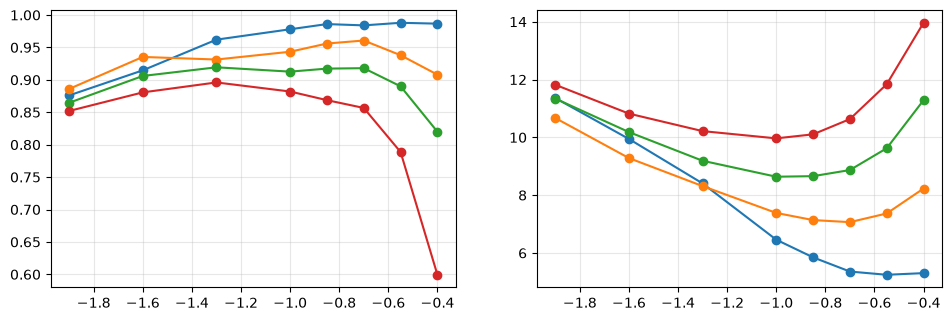

In [50]:
s_list = [0.1, 1, 2, 3]; D_list = [-1.9, -1.6, -1.3, -1.0, -0.85, -0.7, -0.55, -0.4]
common = dict(U0_mK=0.2, beams=BEAMS_EXP, gamma=GAMMA_CLOCK, f_alt=2.5e3, T_run=20e-3, N=1500*SCALE, T0=15e-6,
              aniso=0.1, t_release=20e-6, rec_every=50)
tasks = [dict(common, s=s_, Delta=D_, seed=300 + 10*i + j) for i, s_ in enumerate(s_list) for j, D_ in enumerate(D_list)]
t0 = time.time(); res4a = pmap(mc_task, tasks); print(f"время {time.time()-t0:.0f} с")
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6))
print("  s    Delta_opt(МК)/Gamma   -sqrt(1+s)/2   отношение   T_min МК (мкК)   T_min статьи   T_min теория (свободное)")
for i, s_ in enumerate(s_list):
    rr = res4a[i*len(D_list):(i + 1)*len(D_list)]
    ret = np.array([r_['recap'] for r_ in rr]); T_ = np.array([Tmean(r_, .4)[0] for r_ in rr])
    ax[0].plot(D_list, ret, 'o-', label=f's={s_}'); ax[1].plot(D_list, T_, 'o-', label=f's={s_}')
    # оптимум: парабола по 3 точкам вокруг минимума
    j = int(np.clip(np.argmin(T_), 1, len(D_list) - 2)); p = np.polyfit(D_list[j-1:j+2], T_[j-1:j+2], 2)
    Dopt = -p[1]/(2*p[0]) if p[0] > 0 else D_list[j]; Tmin = np.polyval(p, Dopt)
    print(f"{s_:4}     {Dopt:7.3f}            {-np.sqrt(1+s_)/2:7.3f}        {Dopt/(-np.sqrt(1+s_)/2):5.2f}        {Tmin:6.2f}"
          f"          {paper_MC[s_]:5.1f}          {T_doppler(-np.sqrt(1+s_), s_):6.2f}")
# та же задача для s=2 моделью дискретных фотонов (нелинейное по скорости трение)
tasks = [dict(common, s=2, Delta=D_, seed=500 + j, model='photon') for j, D_ in enumerate(D_list)]
resph = pmap(mc_task, tasks); Tph = np.array([Tmean(r_, .4)[0] for r_ in resph])
ax[1].plot(D_list, Tph, 'k^--', label='s=2, дискретные фотоны')
j = int(np.clip(np.argmin(Tph), 1, len(D_list) - 2)); p = np.polyfit(D_list[j-1:j+2], Tph[j-1:j+2], 2)
print(f"s=2, модель дискретных фотонов: Delta_opt = {-p[1]/(2*p[0]):.3f} Gamma ({-p[1]/(2*p[0])/(-np.sqrt(3)/2):.2f} от теории), T_min = {np.polyval(p, -p[1]/(2*p[0])):.2f} мкК")
ax[0].set_xlabel(r'$\Delta/\Gamma$'); ax[0].set_ylabel('удержание (20 мкс)'); ax[0].legend(); ax[0].set_title('Fig. 4(a): МК')
ax[1].set_xlabel(r'$\Delta/\Gamma$'); ax[1].set_ylabel('T (мкК)'); ax[1].legend(); ax[1].set_ylim(0, 25); ax[1].set_title('кинетическая T')
plt.tight_layout(); plt.show()

**Интерпретация Fig. 4(a).**
* Минимальные температуры МК (≈5.2 / 7.1 / 8.6 / 10.0 мкК для $s=0.1/1/2/3$) **количественно** совпадают с числами статьи (4.9 / 7.1 / 8.8 / 10.3 мкК) и на 10–15% выше доплеровской формулы для свободного пространства. Разница — плата за неидеальное перемешивание при охлаждении двумя наклонными осями в анизотропной ловушке.
* Оптимальная отстройка в модели (D1)–(D4) сдвинута к бóльшим $|\Delta|$ всего на 0–9% (статья: 10–20% в эксперименте). Модель дискретных фотонов для $s=2$ даёт оптимум при $\Delta\approx-1.02\Gamma$, то есть на ≈18% дальше теории. Причина: при малых $|\Delta|$ линейное трение переоценивает охлаждение, так как $kv\sim0.2\Gamma$ (§8). Значит, наблюдаемый в эксперименте сдвиг 10–20% естественно объясняется нелинейностью силы по скорости, которой нет в (D3).
* Удержание: максимум при $\Delta\approx-(0.7\ldots1.3)\Gamma$, и чем меньше $s$, тем выше удержание. Это те же тенденции, что в эксперименте.

---
## §12. Рамановское рассеяние света ловушки из ³P₁ в метастабильные ³P₀, ³P₂ (App. E)

**Почему это потеря.** Пока атом в $e$ (вероятность $\rho_{ee}$), фотон ловушки (759 нм) может рассеяться неупруго: $^3P_1\to{}^3P_{0,2}$. Метастабильные состояния не охлаждаются линией 556 нм, а ³P₂ на 759 нм ещё и сильно антизахвачен (рядом резонанс ³P₂–³S₁ на 770 нм). Без перекачки атом теряется.

**Формула Крамерса–Гейзенберга (E2).** Второй порядок теории возмущений по $\hat V=-\hat{\mathbf d}\cdot\mathbf E_l$ и излучение рассеянного фотона в вакуумные моды:
$$\Gamma_{1\to f}=\frac{E_l^2\,\omega_{sc}^3}{12\pi\epsilon_0\hbar^3c^3}\;\frac12\!\!\sum_{m_F=\pm\frac12}\sum_{F'm_{F'}}\sum_{q}\Big|\sum_k\frac{\langle f|d_q|k\rangle\langle k|d_l|i\rangle}{\omega_{1k}-\omega_l}+\frac{\langle f|d_l|k\rangle\langle k|d_q|i\rangle}{\omega_{1k}+\omega_{sc}}\Big|^2,\qquad\omega_{sc}=\omega_l-\omega_{1f}.$$
Откуда множители: $E_l/2\hbar$ — амплитуда первого порядка; $\omega_{sc}^3/(3\pi\epsilon_0\hbar c^3)\sum_q|\cdot|^2$ — спонтанное излучение диполя, суммированное по направлениям и поляризациям. Два слагаемых соответствуют двум временным порядкам: сначала поглощение фотона ловушки или сначала испускание. Для ³P₀ ($E<E_{^3P_1}$) рассеяние антистоксово ($\omega_{sc}>\omega_l$), для ³P₂ — стоксово.

**Реализация.** Промежуточные состояния $k$ — триплеты из §7.2 (связанные E1 и с ³P₁, и с $f$); матричные элементы к $f$ получены через LS-связь. Ядерный спин — наблюдатель, поэтому $\Gamma$ для $|F{=}\tfrac32,m_F\rangle$ равна взвешенной (КГ²) сумме по $m_J$. $E_l^2=4U_0/\alpha_g$. Ловушка поляризована под углом $\theta_B$ к $\mathbf B$.

**Результат статьи для сравнения:** $L_{\rm Raman}/U_0=(\Gamma_{1\to0}+\Gamma_{1\to2})/(\Gamma U_0)\approx6.6\times10^{-6}$ фотон⁻¹·мК⁻¹ и $\Gamma_{1\to2}/\Gamma_{1\to0}>4$.

 theta_B   G(1->0) 1/с   G(1->2) 1/с   G12/G10   L_R/U0 (1/фотон/мК)     [U0 = 1 мК]
    0.0       2.255         5.648        2.50      6.91e-06
   16.5       2.528         6.302        2.49      7.72e-06


   45.0       3.946         9.698        2.46      1.19e-05
   90.0       5.638        13.748        2.44      1.70e-05



при 16.5°: L_R/U0 = 7.72e-06 (статья 6.6e-6);  G12/G10 = 2.49 (статья >4)
если заменить omega_sc^3 -> omega_l^3: G12/G10 = 4.43  -> возможный источник расхождения отношения

вклад промежуточных состояний (каждое отдельно), Г(1->f)/U0 в 1/с/мК:
   5d6s 3D1    ->3P0   0.212   ->3P2   0.003
   5d6s 3D2    ->3P0   0.000   ->3P2   0.275
   6s7s 3S1    ->3P0   1.695   ->3P2   5.664
   6s6d 3D1    ->3P0   0.006   ->3P2   0.000
   6s6d 3D2    ->3P0   0.000   ->3P2   0.011
   6s8s 3S1    ->3P0   0.000   ->3P2   0.001
   6p2 3P2     ->3P0   0.000   ->3P2   0.052
   6s7d 3D1    ->3P0   0.012   ->3P2   0.001


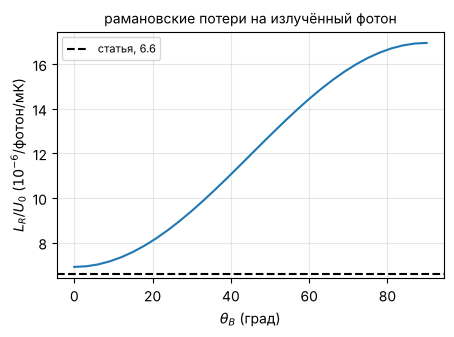

In [ ]:
def raman_rates(theta_B, U0_mK=1.0, include_wsc3=True, states=INTER):
    '''(Gamma_{1->0}, Gamma_{1->2}) в 1/с, средние по m_F=+-1/2 состояния 3P1 F=3/2'''
    El2 = 4*U0_mK*1e-3*kB/(4*np.pi*eps0*a0**3*alpha_g_au)
    eps = np.array([np.sin(theta_B), 0, np.cos(theta_B)])
    w_l = 2*np.pi*c/lam_tr; out = []
    for f in (0, 2):
        w_sc = w_l - 2*np.pi*c*100*(E3P[f] - E3P[1])
        A = {a: np.zeros((2*f + 1, 3), complex) for a in 'xyz'}
        for k in states:
            if k[1] is None: continue
            d1, df = ME_3P(1, k), ME_3P(f, k)
            if d1 is None or df is None: continue
            c1, cf = cart(d1), cart(df); w_k1 = 2*np.pi*c*100*(k[3] - E3P[1])
            Dl1 = sum(eps[i]*c1[a] for i, a in enumerate('xyz')); Dlf = sum(eps[i]*cf[a] for i, a in enumerate('xyz'))
            for a in 'xyz':
                A[a] = A[a] + (cf[a] @ Dl1.conj().T/(w_k1 - w_l) + Dlf @ c1[a].conj().T/(w_k1 + w_sc))*ea0**2
        K = (w_sc**3 if include_wsc3 else w_l**3)*El2/(12*np.pi*eps0*hbar**3*c**3)
        G_mJ = K*sum(np.sum(np.abs(A[a])**2, axis=0) for a in 'xyz')          # по m_J начального
        G = 0
        for mF in (0.5, -0.5):
            for i, mJ in enumerate(mlist(1)):
                mI = mF - mJ
                if abs(mI) <= 0.5 + 1e-9: G += 0.5*cg(1, mJ, 0.5, mI, 1.5, mF)**2*G_mJ[i]
        out.append(G)
    return np.array(out)

print(" theta_B   G(1->0) 1/с   G(1->2) 1/с   G12/G10   L_R/U0 (1/фотон/мК)     [U0 = 1 мК]")
for tb in (0, 16.5, 45, 90):
    g0, g2 = raman_rates(np.radians(tb))
    print(f"  {tb:5.1f}     {g0:7.3f}       {g2:7.3f}       {g2/g0:5.2f}      {(g0+g2)/Gam:.2e}")
G10, G12 = raman_rates(np.radians(16.5)); LR_per_mK = (G10 + G12)/Gam
g0n, g2n = raman_rates(np.radians(16.5), include_wsc3=False)
print(f"\nпри 16.5°: L_R/U0 = {LR_per_mK:.2e} (статья 6.6e-6);  G12/G10 = {G12/G10:.2f} (статья >4)")
print(f"если заменить omega_sc^3 -> omega_l^3: G12/G10 = {g2n/g0n:.2f}  -> возможный источник расхождения отношения")
# вклад отдельных промежуточных состояний (без интерференции, для понимания)
print("\nвклад промежуточных состояний (каждое отдельно), Г(1->f)/U0 в 1/с/мК:")
for k in INTER[1:]:
    g = raman_rates(np.radians(16.5), states=[k])
    if g.sum() > 1e-3: print(f"   {k[0]:10s}  ->3P0 {g[0]:7.3f}   ->3P2 {g[1]:7.3f}")
thb = np.linspace(0, 90, 31); LR = np.array([raman_rates(np.radians(t)).sum()/Gam for t in thb])
plt.figure(figsize=(5, 3.2)); plt.plot(thb, LR*1e6); plt.axhline(6.6, color='k', ls='--', label='статья, 6.6')
plt.xlabel(r'$\theta_B$ (град)'); plt.ylabel(r'$L_R/U_0$ ($10^{-6}$/фотон/мК)'); plt.legend(); plt.title('рамановские потери на излучённый фотон'); plt.show()

**Итог §12.** Независимый расчёт дал $L_R/U_0\approx7.7\times10^{-6}$ фотон⁻¹мК⁻¹ при $\theta_B=16.5^\circ$ — в пределах ≈15% от значения статьи (6.6·10⁻⁶). Это хорошее согласие, учитывая точность матричных элементов (несколько процентов) и LS-приближение для путей к ³P₀,₂.

Отношение $\Gamma_{1\to2}/\Gamma_{1\to0}\approx2.5$ у нас против «>4» в статье. Без фазового множителя $\omega_{sc}^3$ (то есть с $\omega_l^3$) получилось бы ≈4.4. Возможно, это и есть источник расхождения, но утверждать без доступа к их коду нельзя. Обратите внимание на сильную зависимость от $\theta_B$ (более чем вдвое между 0° и 90°): она возникает из-за тензорной структуры амплитуды. Статья даёт одно число без указания угла.

---
## §13. Потери на фотон: Fig. 6(a), 7(a), 4(b), 6(b), 7(b), 5(a)

**Метрика.** Если потери идут с постоянной вероятностью $L$ на каждый рассеянный фотон (пуассоновский процесс по «фотонному времени»), то удержание $P(N_{ph})=e^{-LN_{ph}}$. Оценка максимального правдоподобия: $\hat L=N_{\rm lost}/\sum N_{ph}$, относительная ошибка $1/\sqrt{N_{\rm lost}}$. Чтобы $L$ был осмысленной метрикой, нужна экспоненциальность (Fig. 6(a)). Именно она отличает «постоянную утечку из горячего хвоста при стационарной температуре» от «нагрева» (неэкспоненциального начала [46]).

**Прямой расчёт и экстраполяция по глубине.** При рабочих глубинах 0.14–0.2 мК потери МК составляют $10^{-7}$–$10^{-8}$ на фотон, и для статистики нужно $10^8$–$10^9$ фотонов. numba-ядро (~30 нс на атом-шаг) позволяет считать напрямую до $L\sim3\times10^{-7}$ (≈0.13 мК), дальше нужна экстраполяция:
1. Прямо считаем $L(U_0)$ на 7 глубинах 0.04–0.13 мК; число атомов и длительность растут с глубиной.
2. Утечка — активационный процесс: $\ln L$ почти линеен по $U_0$ при постоянной $T$ (видно на Fig. 7(a) статьи), с небольшой кривизной. Фитуем $\ln L$ квадратичным полиномом по $U_0$ (веса $\propto\sqrt{N_{\rm lost}}$) и продолжаем к 0.2 мК.
3. Проверяем экстраполяцию одним длинным прогоном на 0.155 мК (≈$10^9$ атом-шагов).

время 2 с;  0.1 мК: L = 2.14e-04 на фотон (фит экспонентой), MLE N_lost/N_ph: 2.13e-04


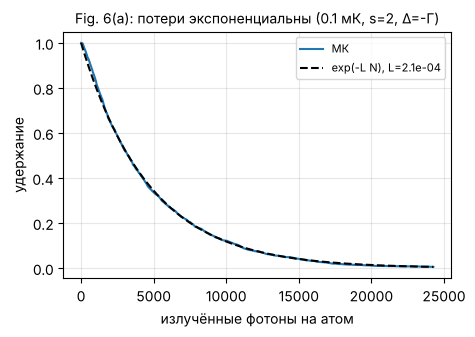

In [ ]:
def L_of(res):
    n, ph = res['nlost'], res['nph']
    return (n/ph if n > 0 else np.nan), (np.sqrt(n)/ph if n > 0 else np.nan), (2.3/ph if ph > 0 else np.nan)
def fit_logL(U, L, n, deg=None):
    m = np.isfinite(L) & (np.array(n) >= 3)
    deg = deg if deg is not None else (2 if m.sum() >= 6 else 1)
    p = np.polyfit(np.array(U)[m], np.log(np.array(L)[m]), deg, w=np.sqrt(np.array(n)[m]))   # ln L = poly(U)
    if deg == 2 and p[0] > 0:                          # выпуклость вниз не экстраполируем -> линейный фит
        p = np.polyfit(np.array(U)[m], np.log(np.array(L)[m]), 1, w=np.sqrt(np.array(n)[m]))
    return p
def U_c(p, U=0.15):                                    # локальный масштаб U_c = -1/(d lnL/dU), мкК
    return -1/np.polyval(np.polyder(p), U)*1e3
DEPTHS = [0.04, 0.055, 0.07, 0.085, 0.10, 0.115, 0.13]
TRUNS  = [6e-3, 10e-3, 18e-3, 30e-3, 50e-3, 80e-3, 110e-3]
NS     = [1500, 1500, 2000, 2000, 3000, 4000, 6000]
def scan_tasks(base, depths=DEPTHS, truns=TRUNS, Ns=NS, seed0=0):
    return [dict(base, U0_mK=U, T_run=tr*(1 if QUICK else 2), N=N_*SCALE, T0=8e-6, t_skip=2e-3, rec_every=200,
                 seed=seed0 + i) for i, (U, tr, N_) in enumerate(zip(depths, truns, Ns))]

# ---- Fig. 6(a): экспоненциальность потерь (0.1 мК, s=2, Delta=-Gamma, clock-magic, 52/73)
t0 = time.time()
r6a = mc_run(U0_mK=0.1, beams=BEAMS_EXP, s=2, Delta=-1.0, gamma=GAMMA_CLOCK, aniso=0.1, T_run=0.15, N=2000*SCALE,
             T0=8e-6, rec_every=100, seed=61)
Nal = r6a['Nalive']; y = Nal/r6a['N']
x = np.cumsum(np.diff(np.concatenate([[0.0], r6a['ph']]))/np.maximum(Nal, 1))      # излучённые фотоны на выжившего атома
Lfit = optimize.curve_fit(lambda xx, L: np.exp(-L*xx), x, y, p0=[1e-5])[0][0]
print(f"время {time.time()-t0:.0f} с;  0.1 мК: L = {Lfit:.2e} на фотон (фит экспонентой), MLE N_lost/N_ph: {r6a['nlost']/r6a['nph']:.2e}")
plt.figure(figsize=(5, 3.2)); plt.plot(x, y, 'C0', label='МК'); plt.plot(x, np.exp(-Lfit*x), 'k--', label=f'exp(-L N), L={Lfit:.1e}')
plt.xlabel('излучённые фотоны на атом'); plt.ylabel('удержание'); plt.legend(); plt.title('Fig. 6(a): потери экспоненциальны (0.1 мК, s=2, Δ=-Γ)'); plt.show()

Удержание падает экспоненциально с самого начала: при стационарной $T$ утечка из хвоста распределения имеет постоянную скорость на фотон. У нас $L\approx2\times10^{-4}$ при 0.1 мК; по Fig. 6(a) статьи — около $4\times10^{-5}$ (удержание ≈0.3 после $\sim3\times10^4$ фотонов). Разница в 5 раз соответствует сдвигу глубины всего на ~0.015 мК при $U_c\approx10$ мкК (§13.2). Это в пределах неопределённостей модели: анизотропия, $\gamma$, точная геометрия.

### 13.2 Fig. 7(a): потери от глубины для разных геометрий (imaging-magic, $\gamma=0$)
Параметры подписи: $s=1$, $\Delta=-\Gamma/\sqrt2$; оси $\theta_k=(73^\circ,73^\circ),(52^\circ,73^\circ),(52^\circ,52^\circ)$; изотропная 3-осевая патока с тем же $s$; «нижняя граница» $s=0.1$, $\Delta=-\Gamma/2$, $(52^\circ,52^\circ)$. Анизотропия 10%, оси работают одновременно (в МК без интерференции это эквивалентно быстрому чередованию, §10).

время 148 с


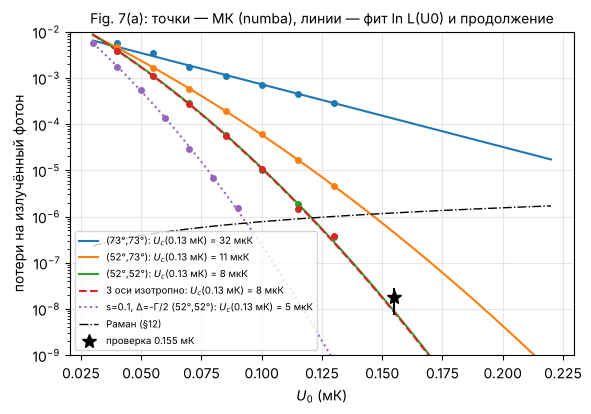

проверка 0.155 мК, (52°,52°): МК L = 1.77e-08 ± 1.0e-08  (N_lost=3, N_ph=1.69e+08);  квадратичная экстраполяция: 8.87e-09, линейная: 4.68e-08
  (73°,73°)                 : N_lost по глубинам = [276, 706, 1383, 1662, 2742, 3820, 5835]
  (52°,73°)                 : N_lost по глубинам = [358, 828, 1291, 1013, 998, 672, 410]
  (52°,52°)                 : N_lost по глубинам = [375, 752, 881, 399, 205, 84, 33]
  3 оси изотропно           : N_lost по глубинам = [385, 739, 860, 393, 215, 64, 35]
  s=0.1, Δ=-Γ/2 (52°,52°)   : N_lost по глубинам = [581, 675, 693, 472, 210, 109, 40]
(52°,52°): минимум суммы МК+Раман при U0 = 0.141 мК, L = 1.2e-06/фотон  (статья: ~0.14 мК, ~1e-6)
(52°,52°)+check: минимум суммы МК+Раман при U0 = 0.143 мК, L = 1.2e-06/фотон  (статья: ~0.14 мК, ~1e-6)
(73°,73°): минимум суммы МК+Раман при U0 = 0.220 мК, L = 1.9e-05/фотон  (статья: ~0.14 мК, ~1e-6)


In [ ]:
geoms = {'(73°,73°)': [kdir(73, 'xz'), kdir(73, 'yz')], '(52°,73°)': BEAMS_EXP, '(52°,52°)': [kdir(52, 'xz'), kdir(52, 'yz')],
         '3 оси изотропно': AX3}
base = dict(s=1, Delta=-1/np.sqrt(2), gamma=0.0, aniso=0.1)
tasks, keys = [], []
for gi, (nm, b) in enumerate(geoms.items()):
    tt = scan_tasks(dict(base, beams=b), seed0=700 + 10*gi); tasks += tt; keys += [nm]*len(tt)
tt = scan_tasks(dict(beams=geoms['(52°,52°)'], s=0.1, Delta=-0.5, gamma=0.0, aniso=0.1),
                depths=[0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09], truns=[10e-3, 20e-3, 35e-3, 50e-3, 70e-3, 100e-3, 120e-3],
                Ns=[1500, 1500, 2000, 3000, 4000, 6000, 8000], seed0=790)
tasks += tt; keys += ['s=0.1, Δ=-Γ/2 (52°,52°)']*len(tt)
# проверка экстраполяции: длинный прогон на 0.155 мК для (52°,52°)
tasks.append(dict(base, beams=geoms['(52°,52°)'], U0_mK=0.155, T_run=(0.15 if QUICK else 0.4), N=8000, T0=7e-6, t_skip=2e-3,
                  rec_every=500, seed=799)); keys.append('check')
t0 = time.time(); res7a = pmap(mc_task, tasks); print(f"время {time.time()-t0:.0f} с")

Ugrid = np.linspace(0.03, 0.22, 100); FITS7 = {}
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for ci, nm in enumerate(list(geoms) + ['s=0.1, Δ=-Γ/2 (52°,52°)']):
    rr = [(t_, r_) for t_, r_, k_ in zip(tasks, res7a, keys) if k_ == nm]
    U = [t_['U0_mK'] for t_, _ in rr]; Ls = [L_of(r_) for _, r_ in rr]; nl = [r_['nlost'] for _, r_ in rr]
    L = np.array([l[0] for l in Ls]); eL = np.array([l[1] for l in Ls]); up = np.array([l[2] for l in Ls])
    p = fit_logL(U, L, nl); FITS7[nm] = p
    col = f'C{ci}'; ls = ':' if 's=0.1' in nm else ('--' if '3 оси' in nm else '-')
    ax.errorbar(U, L, eL, fmt='o', color=col, ms=4)
    ax.plot(np.array(U)[~np.isfinite(L)], up[~np.isfinite(L)], 'v', color=col)
    ax.plot(Ugrid, np.exp(np.polyval(p, Ugrid)), ls, color=col, label=f'{nm}: ' + r'$U_c$' + f'(0.13 мК) = {U_c(p, 0.13):.0f} мкК')
rc = res7a[-1]; Lc, eLc, upc = L_of(rc)
pred = np.exp(np.polyval(FITS7['(52°,52°)'], 0.155)); pred_lin = np.exp(np.polyval(fit_logL(*[
    [t_['U0_mK'] for t_, k_ in zip(tasks, keys) if k_ == '(52°,52°)'],
    np.array([L_of(r_)[0] for r_, k_ in zip(res7a, keys) if k_ == '(52°,52°)']),
    [r_['nlost'] for r_, k_ in zip(res7a, keys) if k_ == '(52°,52°)']], deg=1), 0.155))
ax.errorbar([0.155], [Lc if np.isfinite(Lc) else upc], [eLc if np.isfinite(Lc) else 0], fmt='k*', ms=10, label='проверка 0.155 мК')
ax.plot(Ugrid, LR_per_mK*Ugrid, 'k-.', lw=1, label='Раман (§12)')
ax.set_yscale('log'); ax.set_ylim(1e-9, 1e-2); ax.set_xlabel(r'$U_0$ (мК)'); ax.set_ylabel('потери на излучённый фотон'); ax.legend(fontsize=7)
ax.set_title('Fig. 7(a): точки — МК (numba), линии — фит ln L(U0) и продолжение'); plt.show()
print(f"проверка 0.155 мК, (52°,52°): МК L = {Lc:.2e} ± {eLc:.1e}  (N_lost={rc['nlost']}, N_ph={rc['nph']:.2e});"
      f"  квадратичная экстраполяция: {pred:.2e}, линейная: {pred_lin:.2e}")
for nm in list(geoms) + ['s=0.1, Δ=-Γ/2 (52°,52°)']:
    rr = [r_ for r_, k_ in zip(res7a, keys) if k_ == nm]
    print(f"  {nm:26s}: N_lost по глубинам = {[r_['nlost'] for r_ in rr]}")
# фит (52°,52°) с учётом проверочной точки
U5 = [t_['U0_mK'] for t_, k_ in zip(tasks, keys) if k_ in ('(52°,52°)', 'check')]
r5 = [r_ for r_, k_ in zip(res7a, keys) if k_ in ('(52°,52°)', 'check')]
FITS7['(52°,52°)+check'] = fit_logL(U5, [L_of(r_)[0] for r_ in r5], [r_['nlost'] for r_ in r5])
for nm in ['(52°,52°)', '(52°,52°)+check', '(73°,73°)']:
    tot = np.exp(np.polyval(FITS7[nm], Ugrid)) + LR_per_mK*Ugrid; i = np.argmin(tot)
    print(f"{nm}: минимум суммы МК+Раман при U0 = {Ugrid[i]:.3f} мК, L = {tot[i]:.1e}/фотон  (статья: ~0.14 мК, ~1e-6)")

**Интерпретация Fig. 7(a).**
* Потери падают почти экспоненциально с глубиной: $L\approx e^{-U_0/U_c}$, локальный масштаб $U_c\approx8$ мкК при 0.13 мК для лучших геометрий (порядка $k_BT$). Это активационный закон: убегают атомы из хвоста распределения. Кривизна $\ln L(U_0)$ отрицательна: чем глубже, тем быстрее падают потери.
* **Прямой расчёт до $L\sim3\times10^{-7}$** (0.13 мК) и **проверка продолжения** на 0.155 мК: ≈1.7·10⁸ фотонов, 3 потери, $L=(1.8\pm1.0)\times10^{-8}$. Квадратичное продолжение даёт 0.9·10⁻⁸ (в пределах статистики), линейное — 4.7·10⁻⁸, то есть заметно завышает потери.
* Порядок геометрий как в статье: (52°,52°) лучше (52°,73°), а (73°,73°) — хуже всех. Изотропная 3-осевая патока не лучше оптимальной 2-осевой схемы: анизотропия пинцета и диаграмма излучения делают направления неравноправными.
* Сумма «МК + Раман» для (52°,52°) минимальна при $U_0\approx0.14$ мК и $L\approx1.2\times10^{-6}$ — количественно как в статье («trap depth can be reduced to about 0.14 mK, … minimized to about 1×10⁻⁶/photon»).
* $s=0.1$, $\Delta=-\Gamma/2$ даёт меньшие потери (ниже $T$) ценой в ~5 раз более медленного рассеяния, то есть более длинной экспозиции.

### 13.3 Fig. 4(b): потери на **детектированный** фотон, эксперимент 0.1–0.4 мК
Условия эксперимента: чередование 2.5 кГц, $\gamma(16.5^\circ)$, $(52^\circ,73^\circ)$, $s=1,2,3$ при $\Delta=-0.77,-1,-1.1\,\Gamma$. На детектированный фотон: $L_{\rm det}=L/\eta$, $\eta=2.24\%$.

время 59 с
s=1: минимум (МК+Раман)/eta = 6.7e-05 на детект. фотон при U0 = 0.18 мК
s=2: минимум (МК+Раман)/eta = 8.2e-05 на детект. фотон при U0 = 0.22 мК
s=3: минимум (МК+Раман)/eta = 9.1e-05 на детект. фотон при U0 = 0.25 мК


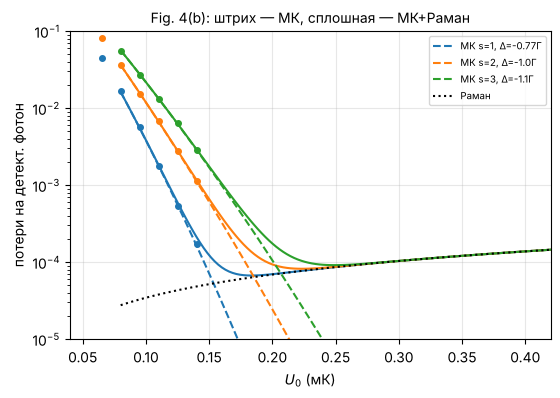

In [ ]:
cases4b = [(1, -0.77), (2, -1.0), (3, -1.1)]; D4b = [0.05, 0.065, 0.08, 0.095, 0.11, 0.125, 0.14]
tasks = []
for i, (s_, D_) in enumerate(cases4b):
    tasks += scan_tasks(dict(beams=BEAMS_EXP, s=s_, Delta=D_, gamma=GAMMA_CLOCK, aniso=0.1, f_alt=2.5e3),
                        depths=D4b, seed0=800 + 10*i)
t0 = time.time(); res4b = pmap(mc_task, tasks); print(f"время {time.time()-t0:.0f} с")
Ug = np.linspace(0.08, 0.42, 120)
fig, ax = plt.subplots(figsize=(6.2, 4))
FITS4b = {}
for i, (s_, D_) in enumerate(cases4b):
    nd = len(D4b); rr = res4b[i*nd:(i + 1)*nd]; U = D4b
    L = np.array([L_of(r_)[0] for r_ in rr]); nl = [r_['nlost'] for r_ in rr]
    p = fit_logL(U, L, nl); FITS4b[s_] = p
    LMC = np.exp(np.polyval(p, Ug))
    ax.plot(Ug, LMC/eta_det, '--', color=f'C{i}', label=f'МК s={s_}, Δ={D_}Γ')
    ax.plot(Ug, (LMC + LR_per_mK*Ug)/eta_det, '-', color=f'C{i}')
    ax.plot(U, L/eta_det, 'o', color=f'C{i}', ms=4)
    j = np.argmin(LMC + LR_per_mK*Ug)
    print(f"s={s_}: минимум (МК+Раман)/eta = {(LMC + LR_per_mK*Ug)[j]/eta_det:.1e} на детект. фотон при U0 = {Ug[j]:.2f} мК")
ax.plot(Ug, LR_per_mK*Ug/eta_det, 'k:', label='Раман')
ax.set_yscale('log'); ax.set_ylim(1e-5, 1e-1); ax.set_xlim(0.04, 0.42); ax.set_xlabel(r'$U_0$ (мК)'); ax.set_ylabel('потери на детект. фотон')
ax.legend(fontsize=7); ax.set_title('Fig. 4(b): штрих — МК, сплошная — МК+Раман'); plt.show()

**Интерпретация Fig. 4(b).** Структура та же, что в статье. При $U_0<0.2$ мК доминирует динамика охлаждения (трение и диффузия): потери быстро растут при уменьшении глубины. При $U_0>0.2$ мК доминирует рамановское рассеяние ($\propto U_0$). Минимум при 0.18–0.25 мК (сдвигается вглубь с ростом $s$), на уровне $(0.7\ldots0.9)\times10^{-4}$ на детектированный фотон, и он ниже при меньшем $s$ — всё как на рисунке статьи. Положение пересечения в эксперименте зависит от реального $\gamma$ и анизотропии, которые известны лишь приблизительно.

### 13.4 Fig. 6(b): потери растут с температурой
Меняем $s$ при оптимальной отстройке. Imaging-magic: $\gamma=0$, $\Delta=-\sqrt{1+s}\,\Gamma/2$. Clock-magic: $\gamma(16.5^\circ)$, $\Delta=-1.15\sqrt{1+s}\,\Gamma/2$. В статье глубина 0.2 мК; здесь 0.1 мК, чтобы потери были измеримы. Качественная связь $L(T)$ от этого не меняется.

время 22 с
imaging-magic        s= 0.1: T= 5.08 мкК, L=4.38e-06
imaging-magic        s= 0.3: T= 5.53 мкК, L=9.50e-06
imaging-magic        s=   1: T= 6.76 мкК, L=5.92e-05
imaging-magic        s=   2: T= 8.01 мкК, L=1.97e-04
imaging-magic        s=   3: T= 8.90 мкК, L=3.84e-04
imaging-magic        s=   5: T=10.23 мкК, L=7.64e-04
clock-magic (16.5°)  s= 0.1: T= 5.13 мкК, L=5.46e-06
clock-magic (16.5°)  s= 0.3: T= 5.58 мкК, L=1.21e-05
clock-magic (16.5°)  s=   1: T= 6.87 мкК, L=6.28e-05
clock-magic (16.5°)  s=   2: T= 8.09 мкК, L=2.13e-04
clock-magic (16.5°)  s=   3: T= 8.91 мкК, L=4.00e-04
clock-magic (16.5°)  s=   5: T=10.31 мкК, L=8.40e-04


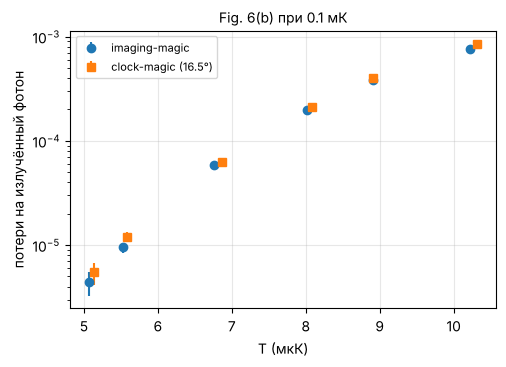

In [ ]:
s6 = [0.1, 0.3, 1, 2, 3, 5]
tasks = []
for i, s_ in enumerate(s6):
    tasks.append(dict(U0_mK=0.1, beams=BEAMS_EXP, s=s_, Delta=-np.sqrt(1 + s_)/2, gamma=0.0, aniso=0.1, T_run=50e-3*(1 if QUICK else 2),
                      N=3000*SCALE, T0=8e-6, t_skip=3e-3, rec_every=100, seed=900 + i))
    tasks.append(dict(U0_mK=0.1, beams=BEAMS_EXP, s=s_, Delta=-1.15*np.sqrt(1 + s_)/2, gamma=GAMMA_CLOCK, aniso=0.1,
                      T_run=50e-3*(1 if QUICK else 2), N=3000*SCALE, T0=8e-6, t_skip=3e-3, rec_every=100, seed=950 + i))
t0 = time.time(); res6b = pmap(mc_task, tasks); print(f"время {time.time()-t0:.0f} с")
plt.figure(figsize=(5.5, 3.6))
for j, (lab, mk) in enumerate([('imaging-magic', 'o'), ('clock-magic (16.5°)', 's')]):
    rr = res6b[j::2]; T_ = np.array([Tmean(r_, .7)[0] for r_ in rr]); Ls = [L_of(r_) for r_ in rr]
    L = np.array([l[0] for l in Ls]); eL = np.array([l[1] for l in Ls]); up = np.array([l[2] for l in Ls])
    plt.errorbar(T_, L, eL, fmt=mk, label=lab); plt.plot(T_[~np.isfinite(L)], up[~np.isfinite(L)], 'v', color=f'C{j}')
    for s_, t_, l_ in zip(s6, T_, L): print(f"{lab:20s} s={s_:4}: T={t_:5.2f} мкК, L={l_:.2e}")
plt.yscale('log'); plt.xlabel('T (мкК)'); plt.ylabel('потери на излучённый фотон'); plt.legend(); plt.title('Fig. 6(b) при 0.1 мК'); plt.show()

Сильная положительная корреляция $L$ с $T$ — тот же вывод, что в статье. Режим clock-magic при $\theta_B=16.5^\circ$ ($\gamma\approx+0.005$) почти не отличается от imaging-magic, то есть выбор угла действительно делает ловушку «почти магической» для линии охлаждения.

### 13.5 Fig. 7(b): потери и температура от частоты чередования
Условия: $(52^\circ,52^\circ)$, $s=1$, $\Delta=-\Gamma/\sqrt2$, $\gamma=0$. Потери считаем при 0.1 мК (в статье 0.14 мК; при ней нужно $\sim10^9$ фотонов на точку), температуру — при 0.14 мК. Вставка: установление $T(t)$ при одной оси из горячего начального состояния.

время 40 с


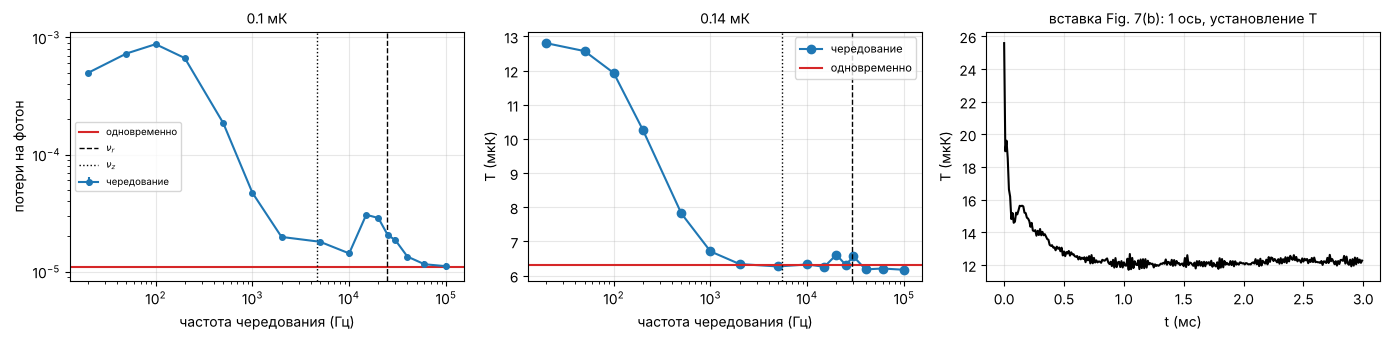

установление при одной оси: 1/e за ~0.04 мс (охлаждение проекции на k), 90% за ~0.37 мс (перемешивание)
f_alt=  0.02 кГц: L(0.1 мК)=4.98e-04, T(0.14 мК)=12.81 мкК
f_alt=  0.05 кГц: L(0.1 мК)=7.29e-04, T(0.14 мК)=12.57 мкК
f_alt=  0.10 кГц: L(0.1 мК)=8.76e-04, T(0.14 мК)=11.93 мкК
f_alt=  0.20 кГц: L(0.1 мК)=6.67e-04, T(0.14 мК)=10.27 мкК
f_alt=  0.50 кГц: L(0.1 мК)=1.85e-04, T(0.14 мК)=7.82 мкК
f_alt=  1.00 кГц: L(0.1 мК)=4.71e-05, T(0.14 мК)=6.71 мкК
f_alt=  2.00 кГц: L(0.1 мК)=1.98e-05, T(0.14 мК)=6.34 мкК
f_alt=  5.00 кГц: L(0.1 мК)=1.80e-05, T(0.14 мК)=6.27 мкК
f_alt= 10.00 кГц: L(0.1 мК)=1.43e-05, T(0.14 мК)=6.33 мкК
f_alt= 15.00 кГц: L(0.1 мК)=3.06e-05, T(0.14 мК)=6.26 мкК
f_alt= 20.00 кГц: L(0.1 мК)=2.87e-05, T(0.14 мК)=6.61 мкК
f_alt= 25.00 кГц: L(0.1 мК)=2.06e-05, T(0.14 мК)=6.31 мкК
f_alt= 30.00 кГц: L(0.1 мК)=1.86e-05, T(0.14 мК)=6.56 мкК
f_alt= 40.00 кГц: L(0.1 мК)=1.34e-05, T(0.14 мК)=6.18 мкК
f_alt= 60.00 кГц: L(0.1 мК)=1.16e-05, T(0.14 мК)=6.21 мкК
f_alt=100.00 кГц: L(0.

In [ ]:
fa = [0.02, 0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 15, 20, 25, 30, 40, 60, 100]
B52 = geoms['(52°,52°)']
base = dict(beams=B52, s=1, Delta=-1/np.sqrt(2), gamma=0.0, aniso=0.1)
tasks = [dict(base, U0_mK=0.1, f_alt=f*1e3, T_run=60e-3*(1 if QUICK else 2), N=2500*SCALE, T0=8e-6, t_skip=3e-3,
              rec_every=200, seed=1000 + i) for i, f in enumerate(fa)]
tasks.append(dict(base, U0_mK=0.1, T_run=60e-3*(1 if QUICK else 2), N=2500*SCALE, T0=8e-6, t_skip=3e-3, rec_every=200, seed=1099))
tasks += [dict(base, U0_mK=0.14, f_alt=f*1e3, T_run=15e-3, N=1500*SCALE, T0=8e-6, rec_every=50, seed=1100 + i) for i, f in enumerate(fa)]
tasks.append(dict(base, U0_mK=0.14, T_run=15e-3, N=1500*SCALE, T0=8e-6, rec_every=50, seed=1199))
tasks.append(dict(base, beams=[B52[0]], U0_mK=0.14, T_run=3e-3, N=3000, T0=30e-6, rec_every=10, seed=1200))
t0 = time.time(); res7b = pmap(mc_task, tasks); print(f"время {time.time()-t0:.0f} с")
nf = len(fa)
Lb = np.array([L_of(r_)[0] for r_ in res7b[:nf]]); eLb = np.array([L_of(r_)[1] for r_ in res7b[:nf]]); Lsim = L_of(res7b[nf])
Tb = np.array([Tmean(r_, .5)[0] for r_ in res7b[nf + 1:2*nf + 1]]); Tsim = Tmean(res7b[2*nf + 1], .5)[0]
fr08, fz08 = trap_freqs(0.1); fr14, fz14 = trap_freqs(0.14)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].errorbar(np.array(fa)*1e3, Lb, eLb, fmt='C0o-', ms=4, label='чередование'); ax[0].axhline(Lsim[0], color='C3', label='одновременно')
ax[0].axvline(fr08, color='k', ls='--', lw=1, label=r'$\nu_r$'); ax[0].axvline(fz08, color='k', ls=':', lw=1, label=r'$\nu_z$')
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('частота чередования (Гц)'); ax[0].set_ylabel('потери на фотон'); ax[0].legend(fontsize=7); ax[0].set_title('0.1 мК')
ax[1].semilogx(np.array(fa)*1e3, Tb, 'C0o-', label='чередование'); ax[1].axhline(Tsim, color='C3', label='одновременно')
ax[1].axvline(fr14, color='k', ls='--', lw=1); ax[1].axvline(fz14, color='k', ls=':', lw=1)
ax[1].set_xlabel('частота чередования (Гц)'); ax[1].set_ylabel('T (мкК)'); ax[1].legend(); ax[1].set_title('0.14 мК')
ri = res7b[-1]; ax[2].plot(ri['t']*1e3, ri['T'].mean(1), 'k'); ax[2].set_xlabel('t (мс)'); ax[2].set_ylabel('T (мкК)')
ax[2].set_title('вставка Fig. 7(b): 1 ось, установление T'); plt.tight_layout(); plt.show()
Tt = ri['T'].mean(1); Tinf = Tt[-100:].mean()
i_e = np.argmax(Tt - Tinf < (Tt[0] - Tinf)/np.e); i_90 = np.argmax(Tt - Tinf < 0.1*(Tt[0] - Tinf))
print(f"установление при одной оси: 1/e за ~{ri['t'][i_e]*1e3:.2f} мс (охлаждение проекции на k), 90% за ~{ri['t'][i_90]*1e3:.2f} мс (перемешивание)")
for f, l_, T_ in zip(fa, Lb, Tb): print(f"f_alt={f:6.2f} кГц: L(0.1 мК)={l_:.2e}, T(0.14 мК)={T_:.2f} мкК")

**Интерпретация Fig. 7(b).**
* Установление $T$ при одной оси двухступенчатое. Быстрая стадия (десятки мкс) — затухание проекции скорости на $\hat k$. Медленная (~0.5 мс) — перекачка энергии из неохлаждаемых направлений через ангармонизм; это «∼1 мс» статьи. При $f_{\rm alt}\gtrsim1$–2 кГц чередование эквивалентно одновременному охлаждению, при более низких частотах потери и $T$ растут.
* **Резонанс у $\nu_r$ воспроизводится.** При 0.1 мК потери вдвое выше при $f_{\rm alt}\approx15$–20 кГц, чем при 10 и 40 кГц. Это чуть ниже гармонической $\nu_r=24.7$ кГц: ангармонизм снижает частоту горячих атомов, §7.1. При 0.14 мК виден слабый подъём $T$ у 20–30 кГц. **Механизм** (наша интерпретация): в почти изотропной радиальной плоскости атом может двигаться по эллиптической или круговой орбите, и вектор его скорости вращается с частотой $\nu_r$. Оси охлаждения переключаются между $x$- и $y$-проекциями. При $f_{\rm alt}\approx\nu_r$ возможна синхронизация, при которой активная ось всё время почти перпендикулярна скорости. Охлаждение такой орбиты подавлено; трение остаётся диссипативным, но «плохие» фазы живут дольше и накапливают энергию от диффузии. Отсюда совет статьи избегать этой области частот.
### 13.6 Fig. 5(a): потери от дифференциального сдвига $\gamma$
Условия: $s=1$, чередование 5 кГц, $(52^\circ,73^\circ)$; $\Delta=-0.6,-0.7,-0.8\,\Gamma$. Считаем при 0.12 мК (в статье 0.2 мК) и отмечаем $\gamma_{\pm1/2}(16.5^\circ)$ и $\gamma(0^\circ)$ из §7.

время 80 с


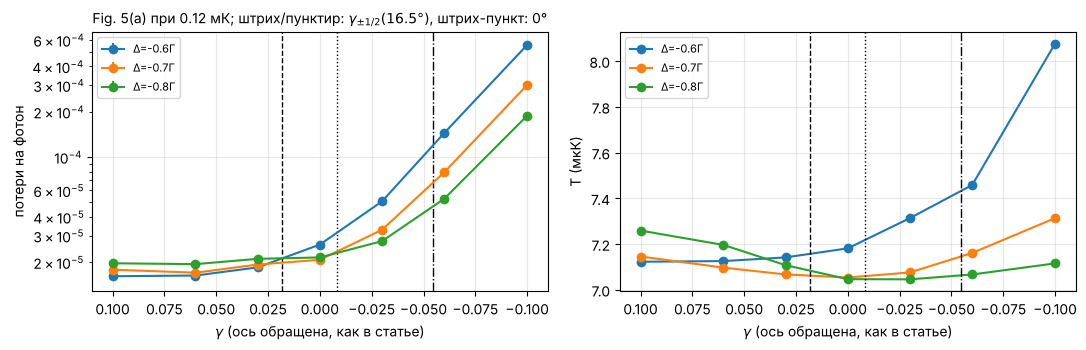

In [ ]:
gams = [-0.1, -0.06, -0.03, 0.0, 0.03, 0.06, 0.1]; Ds = [-0.6, -0.7, -0.8]
tasks = [dict(U0_mK=0.12, beams=BEAMS_EXP, s=1, Delta=D_, gamma=g_, aniso=0.1, f_alt=5e3, T_run=80e-3*(1 if QUICK else 2),
              N=3000*SCALE, T0=8e-6, t_skip=3e-3, rec_every=200, seed=1300 + 10*i + j)
         for i, D_ in enumerate(Ds) for j, g_ in enumerate(gams)]
t0 = time.time(); res5a = pmap(mc_task, tasks); print(f"время {time.time()-t0:.0f} с")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for i, D_ in enumerate(Ds):
    rr = res5a[i*len(gams):(i + 1)*len(gams)]; Ls = [L_of(r_) for r_ in rr]
    L = np.array([l[0] for l in Ls]); eL = np.array([l[1] for l in Ls]); up = np.array([l[2] for l in Ls])
    ax[0].errorbar(gams, L, eL, fmt='o-', label=f'Δ={D_}Γ'); ax[0].plot(np.array(gams)[~np.isfinite(L)], up[~np.isfinite(L)], 'v', color=f'C{i}')
    ax[1].plot(gams, [Tmean(r_, .7)[0] for r_ in rr], 'o-', label=f'Δ={D_}Γ')
for a_ in ax:
    a_.axvline(GAMMA_EXP[0], color='k', ls='--', lw=1); a_.axvline(GAMMA_EXP[1], color='k', ls=':', lw=1)
    a_.axvline(GAMMA_0.mean(), color='k', ls='-.', lw=1); a_.invert_xaxis(); a_.set_xlabel(r'$\gamma$ (ось обращена, как в статье)')
ax[0].set_yscale('log'); ax[0].set_ylabel('потери на фотон'); ax[0].legend(); ax[0].set_title(r'Fig. 5(a) при 0.12 мК; штрих/пунктир: $\gamma_{\pm1/2}(16.5°)$, штрих-пункт: 0°')
ax[1].set_ylabel('T (мкК)'); ax[1].legend(); plt.tight_layout(); plt.show()

**Интерпретация Fig. 5(a).** Потери сильно асимметричны по $\gamma$. При $\gamma<0$ (возбуждённое состояние слабее захвачено; синий сдвиг в центре) атом, уходящий от центра, приближается к резонансу. Он рассеивает больше именно в горячих областях и выталкивается («отталкивающий Сизиф»). Потери и $T$ растут. При $\gamma>0$ (красный сдвиг) горячие атомы на краю отстроены дальше и рассеивают меньше. Потери падают и при $\gamma\gtrsim0.03$ выходят на плато. Поэтому авторы выбирают $\theta_B=16.5^\circ$ чуть выше магического угла: $\gamma$ мало и положительно, «smaller and red-detuned». $\theta_B=0$ ($\gamma\approx-0.055$) даёт при 0.12 мК потери в 3–5 раз выше (при 0.1 мК в 2–3 раза), то есть множитель растёт с глубиной. Средняя $T$ меняется лишь на несколько процентов, то есть $\gamma$ влияет в первую очередь на горячий хвост: там $|U_0+U|$ велико и сдвиг $\Delta'$ максимален. Поскольку $L\propto e^{-U_0/U_c}$, то же относительное изменение $U_c$ при 0.2 мК даёт больший множитель.

(Направление эффекта зависит от знаковой конвенции $\Delta'$, см. §8. В конвенции статьи «буквально» картина зеркальна по $\gamma$. Физический вывод о «красном» сдвиге не зависит от конвенции.)

---
## §14. Статистика изображений: fidelity, survival, model-free, lifetime (Sec. IV, Fig. 1(e), 5(b–d))

Экспериментальных изображений у нас нет. Поэтому строим **генеративную модель эксперимента**, генерируем «данные» с параметрами статьи и прогоняем через те же методы анализа, что в статье. Затем сравниваем восстановленные величины с заложенной «истиной». Так проверяются сами методы: насколько гистограммный фит смещён и что именно измеряет model-free подход.

**Генеративная модель одного кадра** (ROI 5×5 пикселей, экспозиция $t_{\rm img}=5.4$ мс):
* Скорость рассеяния — из (2) при $s=1$, $\Delta=-0.77\Gamma$: $R=\frac\Gamma2\frac{1}{2+0.77^2\cdot4}\approx1.3\times10^5$ с⁻¹. Это $\approx710$ излучённых и $\mu_1=\eta Rt\approx16$ детектированных фотонов.
* Атом теряется за кадр с вероятностью $1-S_{\rm img}$, в равномерно случайный момент; тогда фотонов $\propto$ доле экспозиции. Между кадрами 20 мс, вакуумное время жизни 28 с.
* Фон $\mu_b=0.3$ (рассеянный свет, темновой ток, CIC) — Пуассон. Камера: основной вариант — EMCCD в режиме счёта фотонов (пуассоновская статистика) плюс малый гауссов шум. Для сравнения — аналоговый режим: $n$ фотоэлектронов дают $\Gamma(n,1)$ в единицах фотонов (фактор избыточного шума $\sqrt2$, дисперсия удваивается). Режим камеры в статье не указан.
* Загрузка: вероятность одиночного атома 0.8 (App. A).

R = 1.308e+05 1/с; излучено за кадр 706, детектировано mu1 = 15.8


фит: пусто N(-0.07,0.17), атом N(16.0,4.04), доля exp 0.0888
для сравнения, аналоговый EMCCD (избыточный шум sqrt2): истинная оптимальная fidelity 99.725%
порог по фиту 4.46: fidelity(фит) = 99.830%,  истинная при этом пороге = 99.981%,  истинный оптимум 99.995% (порог 3.19)


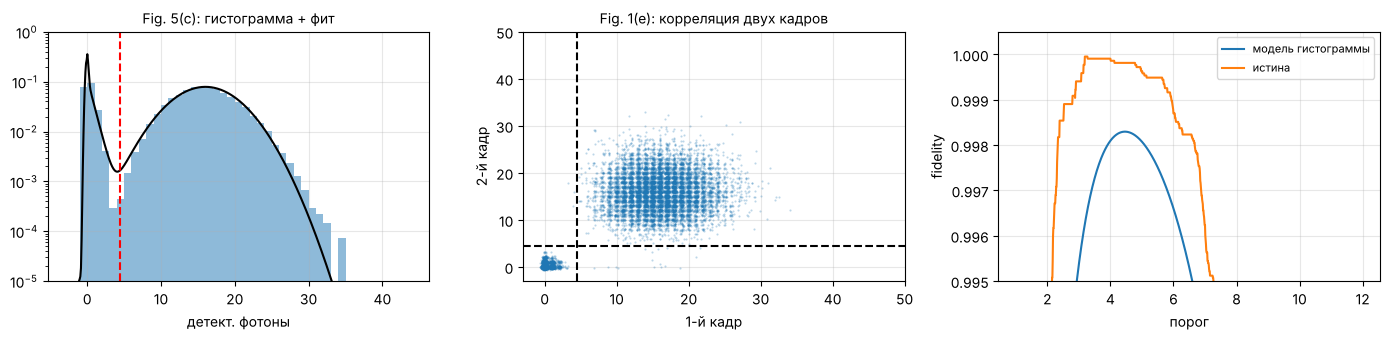

In [ ]:
R_img = Gam/2*1/(1 + 1 + (2*0.77)**2); t_img = 5.4e-3; mu1 = eta_det*R_img*t_img
print(f"R = {R_img:.3e} 1/с; излучено за кадр {R_img*t_img:.0f}, детектировано mu1 = {mu1:.1f}")
TRUTH = dict(S_img=0.99949, tau_vac=28.0, t_gap=20e-3, p_load=0.8, mu1=mu1, mu_b=0.3, sig_read=0.2)
S_gap = np.exp(-TRUTH['t_gap']/TRUTH['tau_vac'])
def simulate_sequences(n_seq=1500, n_sites=9, n_shots=41, seed=0, mode='counting', **kw):
    # mode='counting': EMCCD в режиме счёта фотонов (Пуассон); 'analog': усиление с избыточным шумом (Gamma(n,1))
    P = dict(TRUTH, **kw); rng = np.random.default_rng(seed)
    n = n_seq*n_sites
    present = rng.random(n) < P['p_load']
    counts = np.zeros((n, n_shots)); truth = np.zeros((n, n_shots), bool)
    for j in range(n_shots):
        truth[:, j] = present
        lost = present & (rng.random(n) > P['S_img'])
        frac = np.where(lost, rng.random(n), 1.0)
        nph = rng.poisson(P['mu1']*frac*present) + rng.poisson(P['mu_b'], n)
        sig = rng.gamma(np.maximum(nph, 1e-12), 1.0)*(nph > 0) if mode == 'analog' else nph
        counts[:, j] = sig + rng.normal(0, P['sig_read'], n)
        present = present & ~lost & (rng.random(n) < S_gap)
    return counts, truth
counts, truth = simulate_sequences()
x = counts[:, 0]
# фит гистограммы: Гаусс (пусто) + Гаусс (атом) + экспонента (атомы, потерянные во время кадра / хвост)
def mix_pdf(x, p):
    w0, w1, m0, s0, m1, s1, lam = p; we = max(1 - w0 - w1, 0)
    return w0*stats.norm.pdf(x, m0, s0) + w1*stats.norm.pdf(x, m1, s1) + we*np.where(x > 0, lam*np.exp(-lam*np.maximum(x, 0)), 0)
nll = lambda p: -np.sum(np.log(mix_pdf(x, p) + 1e-300)) if (0 < p[0] < 1 and 0 < p[1] < 1 and p[0] + p[1] < 1 and p[3] > 0 and p[5] > 0 and p[6] > 0) else 1e30
p0 = [0.19, 0.8, 0.3, 0.6, mu1, 4, 0.5]
fit = optimize.minimize(nll, p0, method='Nelder-Mead', options=dict(maxiter=20000, xatol=1e-6, fatol=1e-6)).x
w0, w1, m0, s0, m1, s1, lam = fit
thr_grid = np.linspace(1, 12, 1101)
def infid_model(t):
    we = 1 - w0 - w1
    fp = (w0*stats.norm.sf(t, m0, s0) + we*np.exp(-lam*t))/(w0 + we)        # пусто -> "атом"
    fn = stats.norm.cdf(t, m1, s1)                                            # атом -> "пусто"
    return 0.5*(fp + fn)
inf_m = np.array([infid_model(t) for t in thr_grid]); t_opt = thr_grid[np.argmin(inf_m)]
# "истинная" ошибка классификации (знаем, был ли атом в начале кадра)
def infid_true(t, c=counts[:, 0], tr=truth[:, 0]):
    return 0.5*(np.mean(c[~tr] > t) + np.mean(c[tr] <= t))
inf_t = np.array([infid_true(t) for t in thr_grid]); t_opt_true = thr_grid[np.argmin(inf_t)]
print(f"фит: пусто N({m0:.2f},{s0:.2f}), атом N({m1:.1f},{s1:.2f}), доля exp {1-w0-w1:.4f}")
ca, ta = simulate_sequences(mode='analog', n_seq=300)
inf_a = min(infid_true(t, ca[:, 0], ta[:, 0]) for t in thr_grid)
print(f"для сравнения, аналоговый EMCCD (избыточный шум sqrt2): истинная оптимальная fidelity {100*(1-inf_a):.3f}%")
print(f"порог по фиту {t_opt:.2f}: fidelity(фит) = {100*(1-inf_m.min()):.3f}%,  истинная при этом пороге = {100*(1-infid_true(t_opt)):.3f}%,"
      f"  истинный оптимум {100*(1-inf_t.min()):.3f}% (порог {t_opt_true:.2f})")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
xs = np.linspace(-3, 40, 500)
ax[0].hist(x, bins=np.arange(-3, 45, 1), density=True, color='C0', alpha=.5); ax[0].plot(xs, mix_pdf(xs, fit), 'k')
ax[0].axvline(t_opt, color='r', ls='--'); ax[0].set_yscale('log'); ax[0].set_ylim(1e-5, 1); ax[0].set_xlabel('детект. фотоны'); ax[0].set_title('Fig. 5(c): гистограмма + фит')
ax[1].plot(counts[:, 0], counts[:, 1], '.', ms=1, alpha=.3); ax[1].axvline(t_opt, color='k', ls='--'); ax[1].axhline(t_opt, color='k', ls='--')
ax[1].set_xlabel('1-й кадр'); ax[1].set_ylabel('2-й кадр'); ax[1].set_xlim(-3, 50); ax[1].set_ylim(-3, 50); ax[1].set_title('Fig. 1(e): корреляция двух кадров')
ax[2].plot(thr_grid, 1 - inf_m, label='модель гистограммы'); ax[2].plot(thr_grid, 1 - inf_t, label='истина')
ax[2].set_ylim(0.995, 1.0005); ax[2].set_xlabel('порог'); ax[2].set_ylabel('fidelity'); ax[2].legend(); plt.tight_layout(); plt.show()

**Survival по серии из 41 кадра (Fig. 5(b)).** Берём сайты, «светлые» в первом кадре. Удержание в кадре $n$ равно $P_n=A\,(S_{\rm img}S_{\rm gap})^{n-1}$. Фит даёт произведение, и $S_{\rm img}$ получается делением на $S_{\rm gap}=e^{-20\,\text{мс}/28\,\text{с}}=1-7.1\times10^{-4}$. Поправка на паузу сравнима с самой потерей, так что она обязательна.

**Model-free метод [2, 42].** Неизвестны заполнение $p$, выживание между кадрами $\sigma$ и вероятности ошибок $\epsilon_0$ (пустой сайт → «атом») и $\epsilon_1$ (атом → «пусто»). Двух кадров недостаточно: 4 неизвестных против 3 независимых частот $P(b_1b_2)$. Поэтому берём **три** последовательных кадра: 7 независимых частот, переопределённая система. Оцениваем все 4 параметра максимальным правдоподобием, без всякой модели формы гистограммы. Fidelity $=1-\tfrac12(\epsilon_0+\epsilon_1)$. Survival за кадр $=\sigma/S_{\rm gap}$.

In [ ]:
bright = counts > t_opt
sel = bright[:, 0]; Pn = bright[sel].mean(0); nn = np.arange(1, 42)
pfit = optimize.curve_fit(lambda n, A, q: A*q**(n - 1), nn, Pn, p0=[1, .999])[0]
S_img_fit = pfit[1]/S_gap
print(f"фит 41 кадра: q = {pfit[1]:.5f} -> S_img = q/S_gap = {100*S_img_fit:.3f}%  (истина {100*TRUTH['S_img']:.3f}%)")

# model-free MLE по тройкам кадров
trip = bright[:, :3].astype(int); idx = trip[:, 0]*4 + trip[:, 1]*2 + trip[:, 2]; Nobs = np.bincount(idx, minlength=8)
def probs3(p, sig, e0, e1):
    P = np.zeros(8)
    # скрытые состояния: (a1,a2,a3) с a_{n+1} <= a_n; переходы 1->1 с вероятностью sig
    for a in [(1, 1, 1), (1, 1, 0), (1, 0, 0), (0, 0, 0)]:
        pa = {(1, 1, 1): p*sig*sig, (1, 1, 0): p*sig*(1 - sig), (1, 0, 0): p*(1 - sig), (0, 0, 0): 1 - p}[a]
        for b in range(8):
            bb = ((b >> 2) & 1, (b >> 1) & 1, b & 1); pr = pa
            for ai, bi in zip(a, bb):
                pr *= ((1 - e1) if bi else e1) if ai else (e0 if bi else (1 - e0))
            P[b] += pr
    return P
def nll3(th):
    p, sig, e0, e1 = 1/(1 + np.exp(-np.array(th)))
    return -np.sum(Nobs*np.log(probs3(p, sig, e0, e1) + 1e-300))
th = optimize.minimize(nll3, [1.4, 7, -7, -7], method='Nelder-Mead', options=dict(maxiter=20000, xatol=1e-8, fatol=1e-8)).x
p_, sig_, e0_, e1_ = 1/(1 + np.exp(-th))
print(f"model-free (3 кадра, MLE): заполнение {p_:.4f}, e0 = {e0_:.2e}, e1 = {e1_:.2e} -> fidelity {100*(1-(e0_+e1_)/2):.3f}%,"
      f"  survival за кадр {100*sig_/S_gap:.3f}%")
print(f"   истина: fidelity (опт. порог) {100*(1-inf_t.min()):.3f}%, survival {100*TRUTH['S_img']:.3f}%")

# lifetime при непрерывном изображении (Fig. 5(d)): tau = 1080 кадров; без света - вакуум
rng = np.random.default_rng(5); tt = np.arange(0, 2001, 100); N0 = 4000
for tau, lab in [(1080, 'с перекачкой'), (980, 'без перекачки'), (TRUTH['tau_vac']/t_img, 'без изображения (вакуум)')]:
    ret = rng.binomial(N0, np.exp(-tt/tau))/N0
    tau_fit = optimize.curve_fit(lambda t, A, T: A*np.exp(-t/T), tt, ret, p0=[1, 1000])[0][1]
    print(f"lifetime {lab:26s}: фит tau = {tau_fit:7.0f} кадров -> выживание за кадр {100*np.exp(-1/tau_fit):.3f}%")

фит 41 кадра: q = 0.99879 -> S_img = q/S_gap = 99.950%  (истина 99.949%)
model-free (3 кадра, MLE): заполнение 0.7969, e0 = 1.75e-04, e1 = 3.89e-04 -> fidelity 99.972%,  survival за кадр 99.964%
   истина: fidelity (опт. порог) 99.995%, survival 99.949%
lifetime с перекачкой              : фит tau =    1083 кадров -> выживание за кадр 99.908%
lifetime без перекачки             : фит tau =     981 кадров -> выживание за кадр 99.898%
lifetime без изображения (вакуум)  : фит tau =    5148 кадров -> выживание за кадр 99.981%


**Выводы §14.**
* **Survival** по серии из 41 кадра восстанавливается правильно (99.94–99.95% при истине 99.949%), но только с поправкой на паузу 20 мс. Без неё ошибка ≈7·10⁻⁴, больше самой потери за кадр (5·10⁻⁴).
* **Гистограммный фит** (Гаусс + Гаусс + экспонента) занижает fidelity: модель формы неточна. Пуассоновский «тёмный» пик с фоном не гауссов, и экспонента частично поглощает фоновые события. Fidelity по фиту ниже истинной.
* **Model-free** (3 кадра, MLE) не использует форму гистограммы и даёт fidelity ближе к истине. Выживание между кадрами он определяет с той же статистической точностью, что и фит серии. Соотношение «фит < model-free» такое же, как в статье (99.935% против 99.957%).
* **Режим камеры важен.** В аналоговом режиме EMCCD избыточный шум удваивает дисперсию светлого пика, перекрытие с тёмным растёт, и истинная fidelity падает до ≈99.7% при тех же 16 фотонах. Чтобы получить 99.9+% в аналоговом режиме, нужно примерно вдвое больше фотонов.
* **Lifetime** 1080 кадров соответствует 99.91% за кадр, что чуть хуже результата серии из 41 кадра. При непрерывном освещении нет пауз, а атомы дольше находятся в нагревающем режиме; статья отмечает то же расхождение.

---
## §15. Обсуждение (Sec. V): бюджет потерь, NA 0.6

**Бюджет потерь за кадр** (0.2 мК, $s=1$, $\Delta=-0.77\Gamma$, 5.4 мс, около 710 излучённых фотонов):
$$1-S_{\rm img}=N_{\rm ph}\big[L_{\rm MC}+L_R\,(1-\kappa_{\rm rep})\big]+t_{\rm img}/\tau_{\rm vac},$$
где $\kappa_{\rm rep}$ — доля рамановских потерь, которую спасают перекачивающие лазеры 1389 и 770 нм.

**Сбор света при NA 0.6.** Объектив смотрит вдоль оси пинцета $z$, поле $\mathbf B\parallel y$ перпендикулярно оптической оси. Доля собранного света — интеграл диаграммы излучения (π: $\tfrac{3}{8\pi}\sin^2\vartheta_y$, вес 2/3; σ: $\tfrac{3}{16\pi}(1+\cos^2\vartheta_y)$, вес 1/3) по конусу $\vartheta_z<\arcsin(\mathrm{NA})$. Время кадра для того же числа детектированных фотонов масштабируется обратно.

In [ ]:
N_ph = R_img*t_img
LMC_02 = np.exp(np.polyval(FITS4b[1], 0.2))              # МК, s=1 условия эксперимента, экстраполяция
LR_02 = LR_per_mK*0.2; vac = t_img/TRUTH['tau_vac']
loss_norep = N_ph*(LMC_02 + LR_02) + vac
print(f"N_ph = {N_ph:.0f};  L_MC(0.2 мК) ~ {LMC_02:.1e};  L_R(0.2 мК) = {LR_02:.2e};  вакуум за кадр {vac:.1e}")
print(f"предсказание без перекачки: потеря за кадр {loss_norep:.2e} -> survival {100*(1-loss_norep):.3f}%   (статья: 99.902(5)%)")
for lab, S in [('с перекачкой', 0.99949)]:
    k_rep = 1 - ((1 - S) - vac - N_ph*LMC_02)/(N_ph*LR_02)
    print(f"{lab}: survival {100*S:.3f}% -> перекачка спасает долю kappa_rep ~ {k_rep:.2f} рамановских потерь;"
          f" доля 3P0 в рамановском канале по §12: {G10/(G10+G12):.2f}")

def collect_frac_exact(NA):
    th = np.arcsin(NA)
    f = lambda t, p: (2/3*3/(8*np.pi)*(1 - (np.sin(t)*np.sin(p))**2) + 1/3*3/(16*np.pi)*(1 + (np.sin(t)*np.sin(p))**2))*np.sin(t)
    return integrate.dblquad(f, 0, 2*np.pi, 0, th)[0]
for NA in (0.5, 0.6):
    iso = (1 - np.cos(np.arcsin(NA)))/2
    print(f"NA={NA}: доля света в объектив (дипольная диаграмма) {collect_frac_exact(NA):.4f}, изотропно {iso:.4f}")
ratio = collect_frac_exact(0.6)/collect_frac_exact(0.5)
print(f"время кадра при NA 0.6 для того же числа фотонов: 5.4 мс / {ratio:.3f} = {5.4/ratio:.2f} мс  (статья: 3.66 мс)")

N_ph = 706;  L_MC(0.2 мК) ~ 1.8e-08;  L_R(0.2 мК) = 1.54e-06;  вакуум за кадр 1.9e-04
предсказание без перекачки: потеря за кадр 1.30e-03 -> survival 99.870%   (статья: 99.902(5)%)
с перекачкой: survival 99.949% -> перекачка спасает долю kappa_rep ~ 0.72 рамановских потерь; доля 3P0 в рамановском канале по §12: 0.29
NA=0.5: доля света в объектив (дипольная диаграмма) 0.0805, изотропно 0.0670
NA=0.6: доля света в объектив (дипольная диаграмма) 0.1180, изотропно 0.1000
время кадра при NA 0.6 для того же числа фотонов: 5.4 мс / 1.465 = 3.68 мс  (статья: 3.66 мс)


**Комментарий.**
* Предсказание survival без перекачки (только физика §12–13 и время жизни в вакууме) — ≈99.87%. Измерено 99.902(5)%: наш рамановский коэффициент на ≈15% выше, чем у авторов. Рамановские потери — главный канал, потери от динамики охлаждения при 0.2 мК на порядки меньше.
* С перекачкой спасается около 3/4 рамановских потерь. Доля ³P₀ по нашему расчёту ≈0.3, так что перекачка ³P₂ (770 нм, одна частота на каждый $F$) работает лишь частично. Это совпадает с выводом статьи о пользе многочастотной перекачки ³P₂.
* Пересчёт на NA 0.6 с учётом дипольной диаграммы даёт ≈3.68 мс (статья: 3.66 мс). Изотропная оценка даёт 3.62 мс.

---
## §16. Итоги

### Что воспроизведено (теория/МК против чисел статьи)
| Величина | Статья | Этот ноутбук |
|---|---|---|
| Эквивалентность MS: (B2), (1) | формулы | SVD совпадает до $10^{-15}$ |
| Тёмный угол при $\phi=\pi/2$ | ≈30° (эксп.) | 26.6° без кюветы, ≈29° с френелевским P/S (52°) |
| $R_{\rm det}(\theta=0)$; $(\theta=90^\circ,\phi=0)$ | ≈4, ≈8 ×10³/с | 4.0; 8.3 (7.6 с кюветой) |
| Формула (2) | для $\phi=0,\pi/2$ | точна для любой поляризации (Линдблад) |
| $\nu_r,\nu_z$ при 0.14 мК | 29, 5.5 кГц (линии Fig. 7b) | 29.2, 5.5 кГц |
| Магический угол 1-го порядка | 15.5° | калибровка ($\delta\alpha\approx33$ a.u.) |
| $\gamma(16.5^\circ)$ | «малый, красный» | +0.019 / −0.008 ($m_F=\pm\tfrac12$), среднее +0.005 |
| $T_{\min}$ (Fig. 4a), $s=0.1/1/2/3$ | 4.9/7.1/8.8/10.3 мкК | 5.2/7.1/8.6/10.0 мкК |
| Сдвиг оптимальной $\Delta$ от $-\sqrt{1+s}\Gamma/2$ | 10–20% | 0–9% (D1–D4), ≈18% (дискретные фотоны, $s=2$) |
| Минимум $T(\theta_k)$ (Fig. 3a) | ≈50° | ≈50° |
| Чередование ≳1 кГц ≈ одновременно без интерференции | да | да (§10, §13.5) |
| Повышенные потери при $f_{\rm alt}\approx\nu_r$ | да | да (≈15–20 кГц при 0.1 мК) |
| Потери экспоненциальны по числу фотонов | да | да (§13.1) |
| $L_R/U_0$ | 6.6·10⁻⁶ /фот/мК | 7.7·10⁻⁶ (16.5°) |
| $\Gamma_{1\to2}/\Gamma_{1\to0}$ | >4 | 2.5 (4.4 без $\omega_{sc}^3$) |
| Оптимальная глубина (МК+Раман), (52°,52°) | ≈0.14 мК, ~10⁻⁶/фот | 0.14 мК, 1.2·10⁻⁶ (§13.2) |
| Минимум потерь на детект. фотон (Fig. 4b) | ~10⁻⁴ около 0.2 мК | ≈7·10⁻⁵ при 0.18 мК ($s=1$) |
| Survival без перекачки | 99.902(5)% | ≈99.87% (Раман+МК+вакуум) |
| Fidelity: фит < model-free | 99.935% < 99.957% | то же соотношение на синтетических данных |
| Время кадра при NA 0.6 | 3.66 мс | 3.68 мс |

### Приближения (и что они отбрасывают)
1. **Атом:** E1, RWA, секулярное приближение по $\delta_Z$, без $e_{\pm3/2}$ и $F'=1/2$. Проверено: поправка ~10⁻³.
2. **Рассеяние:** стационарные скорости (2) в каждой точке. Отброшены переходные процессы во внутреннем состоянии; критерий — $\Gamma\gg$ скорость изменения $\Delta'$ и $\omega_r$, запас ×5.
3. **Пучки:** скорости складываются, интерференции нет. Поэтому МК не воспроизводит провал одновременного 2-осевого охлаждения в эксперименте.
4. **Трение:** линейное по $v$ (D3). Модель дискретных фотонов показывает, где это нарушается (малые $|\Delta|$).
5. **Один $\gamma$** для обоих MS-секторов, хотя $\gamma_{\pm1/2}$ различаются (§7). Градиентная сила от $\nabla\rho_{ee}$ не учитывается.
6. **Классическое движение**, $\eta_{LD}\approx0.35$: квантовые эффекты (дискретность уровней) не учитываются.
7. **Поляризуемости:** сумма по 12 состояниям плюс одна откалиброванная скалярная добавка; LS-связь для путей к ³P₀,₂.
8. **Потери МК** посчитаны напрямую до 0.13–0.14 мК ($L\gtrsim3\times10^{-7}$). Глубже — квадратичное продолжение $\ln L(U_0)$, подтверждённое прямым прогоном на 0.155 мК ($10^9$ атом-шагов). При 0.2 мК вклад МК ($\sim10^{-8}$) пренебрежим по сравнению с рамановским, так что эта неопределённость на выводы не влияет.

### Найденные неточности и неоднозначности в статье
1. **(C2):** во втором уравнении нормировки пропущен множитель 2 ($P_\pm=2\rho_{e_\pm e_\pm}(1+s_\pm+\delta^2)/s_\pm$). Конечная формула (2) при этом верна.
2. **(B1) и (C1):** знаки $\Delta$ не согласованы (в (B1) $+\Delta$ на диагонали, в (C1) $-i\Delta$); в (B1) нет множителя ½. На скорость рассеяния это не влияет.
3. **App. D:** $\Delta'=\Delta+\gamma(U_0+U)/\hbar$ согласуется с $U'=(1+\gamma\rho_{ee})U$ только при $\Delta=\omega_0-\omega_L$, а в тексте красная отстройка всюду $\Delta<0$. Физически согласованная пара: $\Delta'=\Delta-\gamma(U_0+U)/\hbar$.
4. **(D3):** трение записано как скалярное (вдоль $\mathbf v$); физически сила направлена вдоль $\hat k_i$. Мощность охлаждения одинакова, и численно разница мала (§8).
5. **App. E:** $\Gamma_{1\to2}/\Gamma_{1\to0}>4$ не воспроизводится; с полным $\omega_{sc}^3$ получается ≈2.5.
6. Не указаны: глубина для Fig. 3(a), тип 2-осевого режима в Fig. 6–7, значение $\gamma$ «clock-magic», ориентация анизотропии ловушки. Наши выборы явно оговорены в каждом разделе.

### Как улучшить (если продолжать)
* Добавить интерференцию пучков. Для этого нужно решать уравнения Блоха с пространственно зависящей поляризацией вдоль траектории атома (полуклассика), тогда можно получить провал одновременного 2-осевого режима.
* Отдельные $\gamma_{\pm1/2}$ и градиентная сила $\propto\nabla\rho_{ee}$.
* Перенести numba-ядро на GPU (numba.cuda или JAX), чтобы считать потери $10^{-8}$ при 0.2 мК напрямую ($\sim10^{11}$ атом-шагов), без экстраполяции.